# Figure 3 main — alternative composite layouts (archive)

Original, v2, v4 and v5 layouts moved out of `figure_3_main.ipynb`, which now only builds the final v3 layout. Data loading and per-panel cells are duplicated here so these layouts can still be regenerated. Their saved PDFs are in `figure_3/composite/old_versions/`.


## Figure 3 - Population responses across experience levels

This script generates Figure 3, showing population neural
responses to image changes and omissions across experience levels (Familiar, Novel, Novel+),
including single cell examples, population averages, response heatmaps, fraction of
responsive cells, and experience modulation indices.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context('notebook', font_scale=1.5, rc={'lines.markeredgewidth': 2})

import visual_behavior.data_access.utilities as utilities
from visual_behavior.data_access import loading as loading

import visual_behavior.visualization.utils as utils
import visual_behavior.visualization.ophys.platform_paper_figures as ppf
import visual_behavior.visualization.ophys.platform_single_cell_examples as pse
import visual_behavior.ophys.response_analysis.cell_metrics as cm
import visual_behavior.dimensionality_reduction.clustering.processing as processing

from allensdk.brain_observatory.behavior.behavior_project_cache import VisualBehaviorOphysProjectCache


%matplotlib inline
%load_ext autoreload
%autoreload 2

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.py", line 632, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.py", line 687, in __get__
    return t.cast(G, self.get(obj, cls))  # the G should encode the Optional
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.p

In [2]:
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'figure_3')
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

folder = 'population_activity'

palette = utils.get_experience_level_colors()
experience_levels = utils.get_new_experience_levels()
experience_level_colors = utils.get_experience_level_colors()
cell_types = utils.get_cell_types()

## Data Loading

### Metadata tables

In [3]:
# AllenSDK cache
platform_cache_dir = loading.get_platform_analysis_cache_dir()
cache = loading._get_cache()

# Curated metadata tables
metadata_tables_dir = loading.get_metadata_tables_dir()
experiments_table = pd.read_csv(os.path.join(metadata_tables_dir, 'all_ophys_experiments_table.csv'), index_col=0)
platform_experiments = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_experiments_table.csv'), index_col=0)
platform_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_cells_table.csv'), index_col=0)
matched_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_matched_ophys_cells_table.csv'), index_col=0)

# Relevant IDs
matched_cells = matched_cells_table.cell_specimen_id.unique()
matched_experiments = matched_cells_table.ophys_experiment_id.unique()

# Cre lines, cell types, and palette for plotting
cre_lines = np.sort(platform_cells_table.cre_line.unique())
palette = utils.get_experience_level_colors()
cell_types = utils.get_cell_types()


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

### Response metrics and multi-session dataframes 

In [4]:
data_type = 'events'
interpolate = True
output_sampling_rate = 30

session_subset = 'full_session'
inclusion_criteria = 'platform_experiment_table'

#### Cell response metrics metrics

In [5]:
metrics_dir = loading.get_cell_metrics_dir()
filepath = os.path.join(metrics_dir, f'merged_model_free_metrics_table_{data_type}_{inclusion_criteria}.csv')
filtered_events_metrics_table = pd.read_csv(filepath, index_col=0)

metrics_table = filtered_events_metrics_table.copy()

# Merge with platform experiments
metrics_table = metrics_table.merge(platform_experiments.reset_index(),
                                   on=['ophys_experiment_id', 'experience_level'])

#### Multi session response dataframes

In [6]:
# Image changes
event_type = 'all'
conditions = ['cell_specimen_id', 'is_change']
multi_session_df = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

change_mdf = multi_session_df[multi_session_df.is_change == True]
image_mdf = multi_session_df[multi_session_df.is_change == False]

# Omissions
conditions = ['cell_specimen_id', 'omitted']
omission_mdf = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)

omission_mdf = omission_mdf[omission_mdf.omitted == True]

# Per image
conditions = ['cell_specimen_id', 'is_change', 'image_name']
each_image_mdf = loading.get_multi_session_df_for_conditions(
    data_type, event_type, conditions, inclusion_criteria,
    interpolate=interpolate, output_sampling_rate=output_sampling_rate,
    epoch_duration_mins=None)


print(len(change_mdf.ophys_experiment_id.unique()))
print(len(omission_mdf.ophys_experiment_id.unique()))
print(len(each_image_mdf.ophys_experiment_id.unique()))

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_platform_experiment_table.feather
there are 1881 experiments in the full multi_session_df
there are 400 experiments in the multi_session_df after limiting to platform experiments
there are 400 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_omitted_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_omitted_platform_experiment_table.feather
there are 1879 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_image_name_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_image_name_platform_experiment_table.feather
there are 1885 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table
400
401
401


#### Dataset objects for all experiments for one field of view (container)

In [7]:
ophys_container_ids = [829561794]

# Load dataset dict for single cell plotting
# ophys_container_ids = matched_cells_table.ophys_container_id.unique()[:4]
dataset_dict = loading.get_dataset_dict_for_containers(ophys_container_ids,
                                                       platform_experiments,
                                                       dataset_dict=None)

833629926


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

834279496


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

835006071


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

## Plotting

### Population activity for image changes

#### Population mean response

In [8]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
# df = image_mdf.copy()
# xlim_seconds = [-0.25, 0.75]

# ppf.plot_population_averages_for_cell_types_across_experience(
#     df, xlim_seconds=xlim_seconds, xlabel='Time from image onset (s)',
#     ylabel='', data_type=data_type, event_type='images',
#     interval_sec=0.5, save_dir=save_dir, folder='population_activity',
#     suffix='', ax=None)

In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

removing 1 problematic experiments


array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nn=12826 cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nn=465 cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nn=1196 cells'>, <Axes: >, <Axes: >],
      dtype=object)

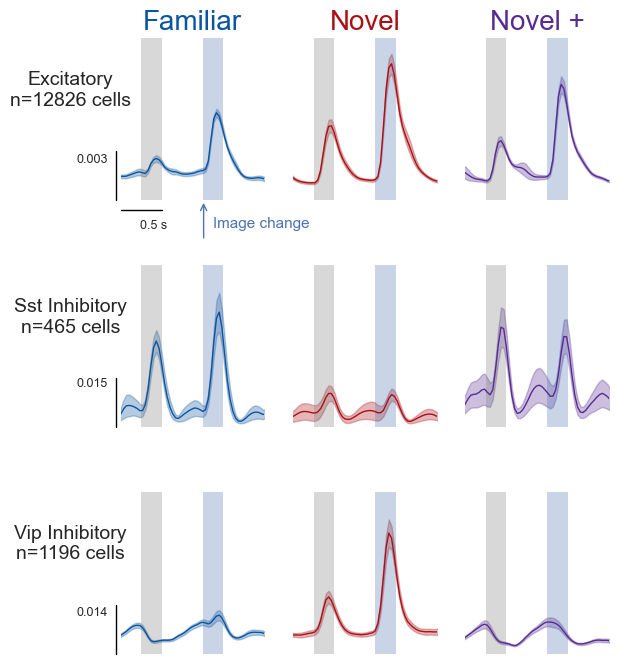

In [11]:
df = change_mdf.copy()
xlim_seconds = [-1., 0.75]

ppf.plot_population_averages_for_cell_types_across_experience(
    df, xlim_seconds=xlim_seconds, xlabel='Time from image change (s)',
    ylabel='Calcium events', data_type=data_type, event_type='changes',
    interval_sec=1, save_dir=save_dir, folder='population_activity',
    suffix='_changes_stacked', ax=None)

#### Quantification of mean response

array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean non-change image response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

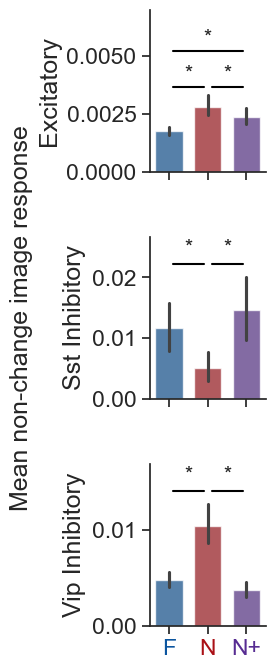

In [12]:
metric = 'mean_response_all_images'
ylabel = 'Mean non-change image response'

event_type = 'all'

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', #show_containers=True,
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=None, save_dir=save_dir, ax=None)



array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean image change response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

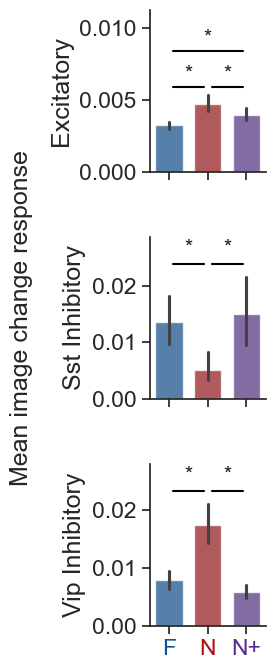

In [13]:
metric = 'mean_response_changes'
ylabel = 'Mean image change response'

event_type = 'changes'

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', 
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=None, save_dir=save_dir, ax=None)



array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean non-change image response - pref image\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

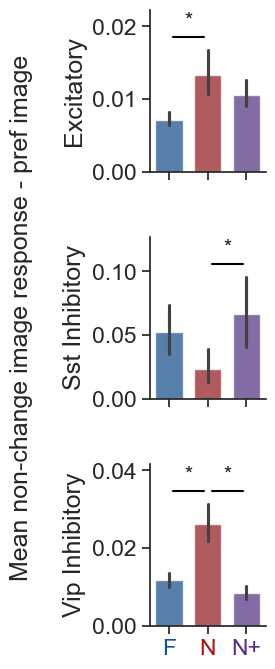

In [14]:
metric = 'mean_response_pref_image'
ylabel = 'Mean non-change image response - pref image'
event_type = 'pref_image'

ppf.plot_metric_distribution_by_experience(metrics_table, metric, plot_type='barplot', #show_containers=True,
                                           horiz=False, add_zero_line=False, event_type=event_type, data_type=data_type,
                                           ylabel=ylabel, ylims=None, save_dir=save_dir, ax=None)



#### Percent responsive cells

Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='% Non-change image responsive cells'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

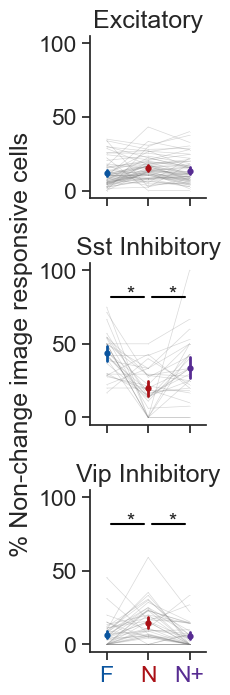

In [15]:
# Quantify fraction of cells responsive to their preferred stimulus
df = each_image_mdf[(each_image_mdf.is_change==False)& (each_image_mdf.pref_stim==True)]

ppf.plot_percent_responsive_cells(df, responsiveness_threshold=0.2, ylim=(-5, 105), ylabel='% Non-change image responsive cells',
                                    save_dir=save_dir, folder =folder, suffix='_images_pref_stim', horizontal=False, ax=None, event_type='images')


Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='% Image change responsive cells'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

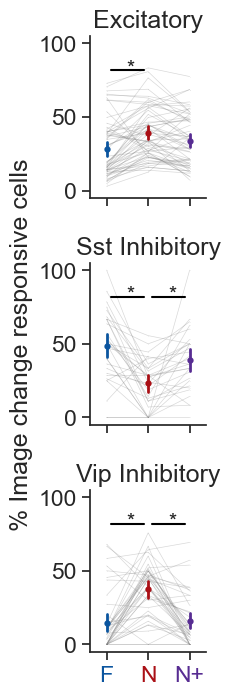

In [16]:
# Quantify fraction of cells responsive to their preferred stimulus
df = each_image_mdf[(each_image_mdf.is_change==True)& (each_image_mdf.pref_stim==True)]

ppf.plot_percent_responsive_cells(df, responsiveness_threshold=0.2, ylim=(-5, 105), ylabel='% Image change responsive cells',
                                    save_dir=save_dir, folder =folder, suffix='_changes_pref_stim', horizontal=False, ax=None, event_type='changes')


#### Change modulation

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Change modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

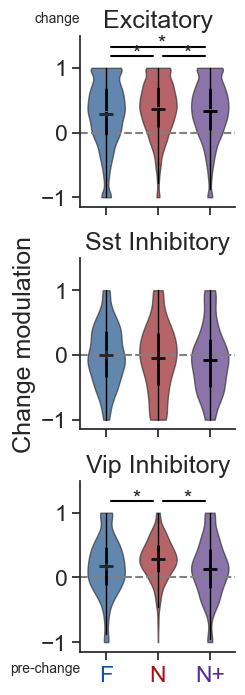

In [17]:
metric = 'change_modulation_index'
xlabel = 'Change modulation'
event_type = 'changes'
annot = ('pre-change', 'change')
xlims = (-1.15, 1.15)

ppf.plot_modulation_index_distribution(metrics_table, metric, label=xlabel, 
                                       lims=xlims, horiz=False, annot=annot, metric_on_y=True,
                                        abbreviate_exp=True, suptitle=None, fill=True, 
                                        save_dir=save_dir, event_type='changes')


In [18]:
missing_ids = metrics_table.loc[
    ~metrics_table['ophys_experiment_id'].isin(change_mdf['ophys_experiment_id']),
    'ophys_experiment_id'].unique()

tmp = metrics_table[metrics_table.ophys_experiment_id.isin(missing_ids)==False]

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y

array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='Change modulation'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

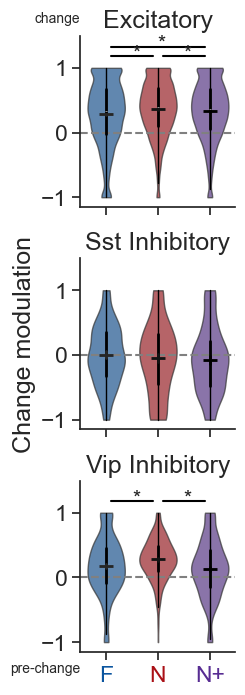

In [19]:
metric = 'change_modulation_index'
xlabel = 'Change modulation'
event_type = 'changes'
annot = ('pre-change', 'change')
xlims = (-1.15, 1.15)

ppf.plot_modulation_index_distribution(tmp, metric, label=xlabel, 
                                       lims=xlims, horiz=False, annot=annot, metric_on_y=True,
                                        abbreviate_exp=True, suptitle=None, fill=True, 
                                        save_dir=save_dir, event_type='changes')


In [20]:
print('image_mdf.mouse_id dtype:', image_mdf.mouse_id.dtype)
print('platform_cells_table.mouse_id dtype:', platform_cells_table.mouse_id.dtype)

image_mdf.mouse_id dtype: int64
platform_cells_table.mouse_id dtype: int64


#### Experience modulation

Quantification of how neural responses change across experience levels. Includes
experience modulation index (computed as the difference in mean response between
two experience levels divided by the sum) for each cell, shown as distributions
per cell type. Also shows mean image change response magnitude across cohorts,
depths, and cortical areas, and the change modulation index (response to image
changes minus response to non-change images, over the sum) split by area and
depth. Corresponds to PPT Figure S6 panels I-N.

In [21]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}>,
       <Axes: title={'center': 'Vip Inhibitory'}, xlabel='Experience modulation'>],
      dtype=object)

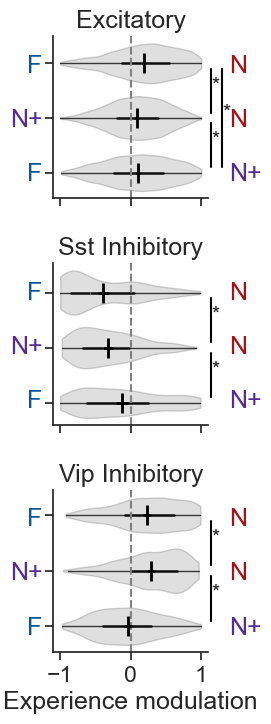

In [22]:
metric = 'mean_response'
event_type = 'images'
xlabel = 'Experience modulation'

ppf.plot_experience_modulation_index_annotated_by_cell_type(image_mdf, event_type, metric, platform_cells_table,
                                                            xlims=(-1.1, 1.1), xlabel=xlabel,
                                                            all_comparisons=True, horiz=False,
                                                            suptitle=None, suffix='', save_dir=None, ax=None)

/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:4373: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_yticklabels([cell_type[:3] for cell_type in cell_types])


array([<Axes: title={'center': 'Novel vs. Familiar'}>,
       <Axes: title={'center': 'Novel vs. Novel +'}>,
       <Axes: title={'center': 'Novel + vs. Familiar'}, xlabel='Experience modulation'>],
      dtype=object)

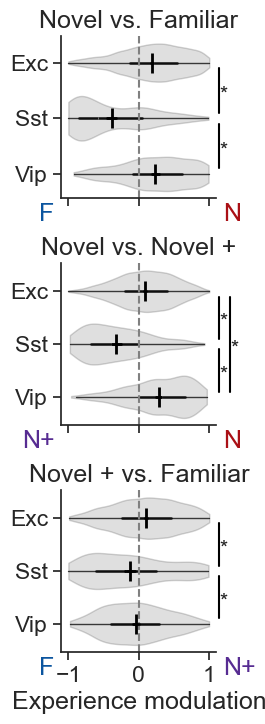

In [23]:
metric = 'mean_response'
event_type = 'images'
xlabel = 'Experience modulation'

ppf.plot_experience_modulation_index_annotated(
    image_mdf, event_type, metric, platform_cells_table,
    horiz=False, xlims=(-1.1, 1.1), xlabel='Experience modulation',
    suffix='_images_modulation', save_dir=save_dir,)

##### Experience vs change modulation 

### Population activity for image omissions

#### Population mean response

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

removing 1 problematic experiments


array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nn=12826 cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nn=465 cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nn=1197 cells'>, <Axes: >, <Axes: >],
      dtype=object)

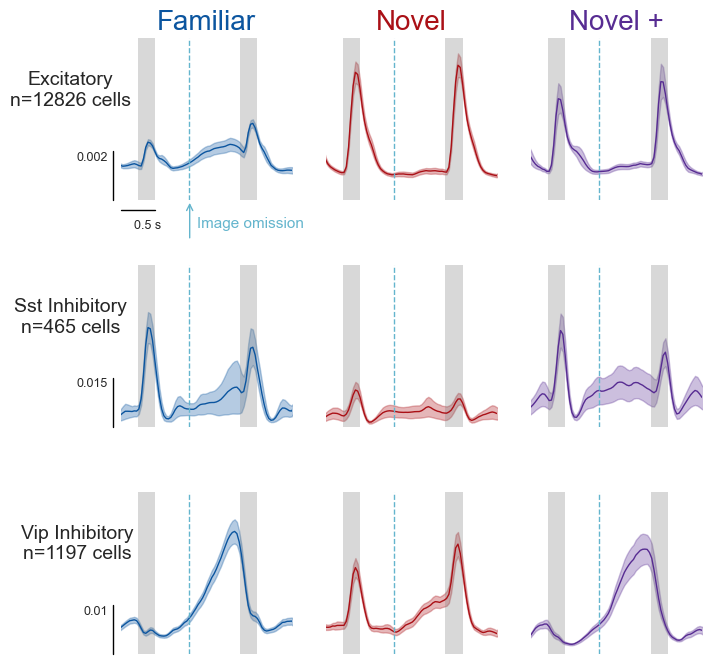

In [24]:
df = omission_mdf.copy()
xlim_seconds = [-1., 1.5]

ppf.plot_population_averages_for_cell_types_across_experience(
    df, xlim_seconds=xlim_seconds, xlabel='Time from image omission (s)',
    ylabel='Calcium events', data_type=data_type, event_type='omissions',
    interval_sec=1, save_dir=save_dir, folder='population_activity',
    suffix='', ax=None)

### Quantification of mean response

array([<Axes: ylabel='Excitatory'>,
       <Axes: ylabel='Mean image omission response\n\nSst Inhibitory'>,
       <Axes: ylabel='Vip Inhibitory'>], dtype=object)

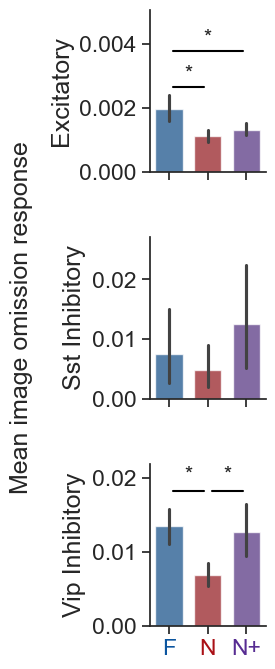

In [25]:
metric = 'mean_response_omissions'
ylabel = 'Mean image omission response'
event_type = 'omissions'

ppf.plot_metric_distribution_by_experience(
    metrics_table, metric, plot_type='barplot', horiz=False,
    suptitle='', add_zero_line=False, event_type=event_type, data_type=data_type,
    ylabel=ylabel, ylims=None, save_dir=save_dir, ax=None)

#### Percent responsive cells 

Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


array([<Axes: title={'center': 'Excitatory'}>,
       <Axes: title={'center': 'Sst Inhibitory'}, ylabel='% Image omission responsive cells'>,
       <Axes: title={'center': 'Vip Inhibitory'}>], dtype=object)

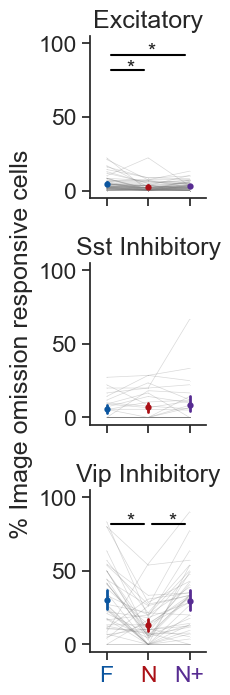

In [26]:
# Quantify fraction of cells responsive to their preferred stimulus
df = omission_mdf.copy()

ppf.plot_percent_responsive_cells(df, responsiveness_threshold=0.1, ylim=(-5, 105), 
                                    ylabel='% Image omission responsive cells',
                                    save_dir=save_dir, folder =folder, suffix='_omissions_pref_stim', 
                                    horizontal=False, ax=None, event_type='omissions')


### Single cell diversity

Example container and cells for matched cell plotting

#### Matched cell response heatmaps

##### Image changes

Sst Inhibitory: dropping 8 of 198 matched cells not present in all 3 experience_level conditions
Vip Inhibitory: dropping 10 of 411 matched cells not present in all 3 experience_level conditions


array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from image onset (s)'>, <Axes: >], dtype=object)

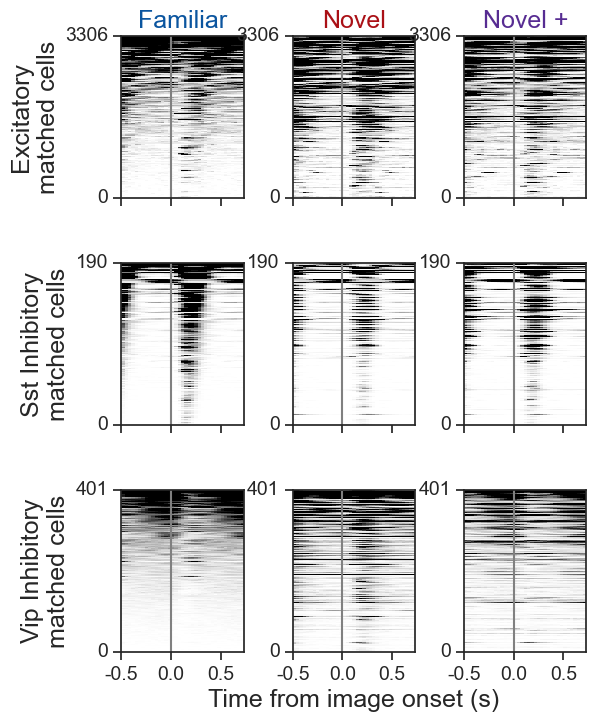

In [27]:
df = image_mdf.copy()

xlim_seconds = [-0.5, 0.75]

event_type = 'images'

timestamps = df.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(df, timestamps, data_type, event_type, row_condition, col_condition, 
                                          col_to_sort_by='mean_baseline', suptitle='', xlabel='Time from image onset (s)',
                                          match_cells=True, matched_cells_table=matched_cells_table,
                                          exp_to_match='Familiar', xlim_seconds=xlim_seconds, cbar=False,
                                          save_dir=save_dir, suffix='', ax=None)



array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from image change (s)'>, <Axes: >],
      dtype=object)

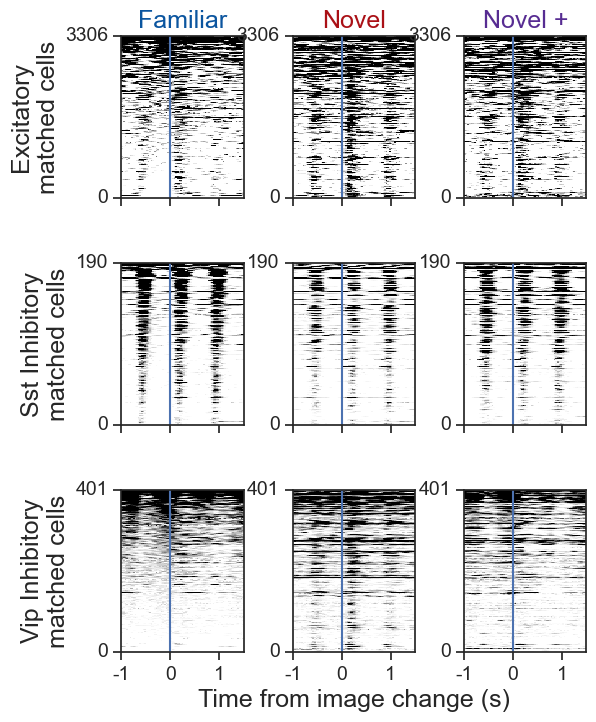

In [28]:
# Cell-matched response heatmaps for images
timestamps = change_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'
cols_to_sort_by = ['mean_response']

# Cell-matched population averages for changes
matched_changes = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(change_mdf)
xlim_seconds = [-1., 1.5]

# Cell-matched response heatmaps for changes
ppf.plot_response_heatmaps_for_conditions(
    matched_changes, timestamps, data_type, 'changes', row_condition, col_condition,
    col_to_sort_by='mean_baseline', suptitle='Matched cells - Changes',
    xlabel='Time from image change (s)', exp_to_match='Familiar', matched_cells_table=matched_cells_table,
    microscope=None, xlim_seconds=[-1, 1.5], match_cells=True, cbar=False,
    save_dir=save_dir, suffix='_matched_changes', ax=None)

##### Image omissions

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\ncells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\ncells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\ncells'>,
       <Axes: xlabel='Time from image omission (s)'>, <Axes: >],
      dtype=object)

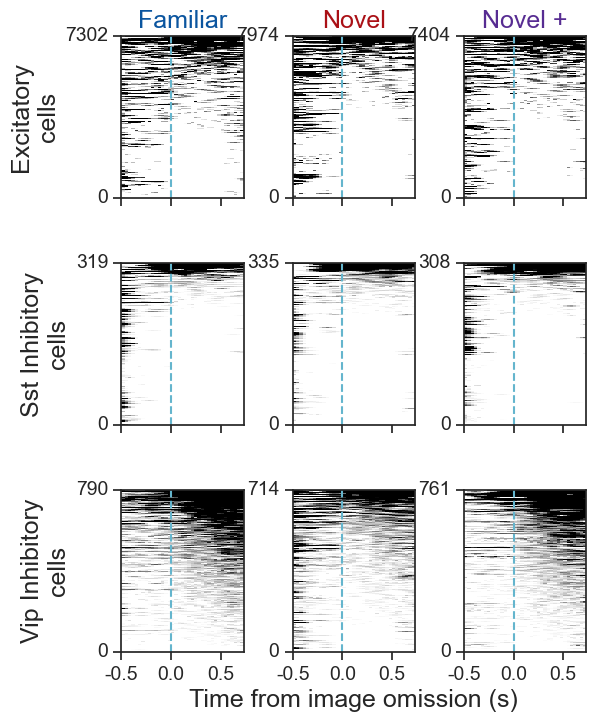

In [29]:
df = omission_mdf.copy()

xlim_seconds = [-0.5, 0.75]

event_type = 'omissions'

timestamps = df.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

ppf.plot_response_heatmaps_for_conditions(df, timestamps, data_type, event_type, row_condition, col_condition, 
                                          col_to_sort_by='mean_response', suptitle='', xlabel='Time from image omission (s)',
                                          microscope=None, vmax=None, xlim_seconds=xlim_seconds, match_cells=False, cbar=False,
                                          save_dir=None, suffix='_heatmap_omissions', ax=None)

array([<Axes: title={'center': 'Familiar'}, ylabel='Excitatory\nmatched cells'>,
       <Axes: title={'center': 'Novel'}>,
       <Axes: title={'center': 'Novel +'}>,
       <Axes: ylabel='Sst Inhibitory\nmatched cells'>, <Axes: >, <Axes: >,
       <Axes: ylabel='Vip Inhibitory\nmatched cells'>,
       <Axes: xlabel='Time from omission (s)'>, <Axes: >], dtype=object)

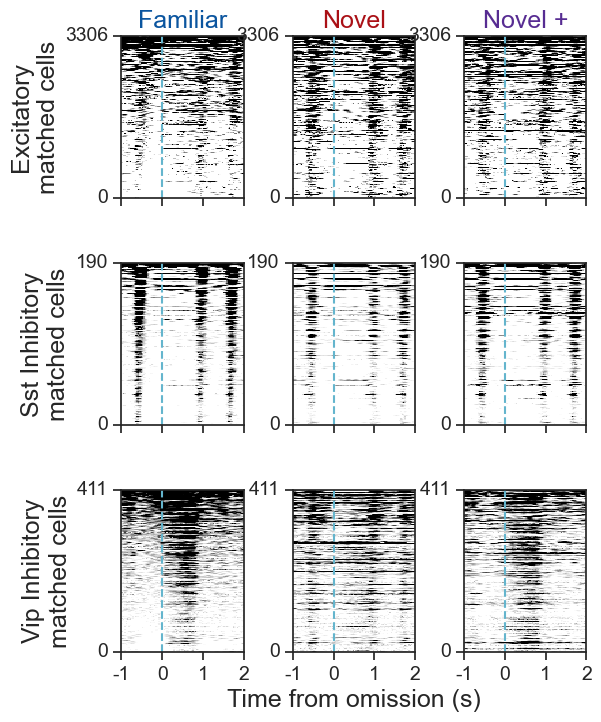

In [30]:
# Population averages for omissions - heatmaps
timestamps = omission_mdf.trace_timestamps.values[0]
row_condition = 'cell_type'
col_condition = 'experience_level'

# Cell-matched omission heatmaps
matched_omissions = utilities.limit_to_cell_specimen_ids_matched_in_all_experience_levels(omission_mdf)

ppf.plot_response_heatmaps_for_conditions(
    matched_omissions, timestamps, data_type, 'omissions', row_condition, col_condition,
    col_to_sort_by='mean_baseline', suptitle='Matched cells - Omissions',
    xlabel='Time from omission (s)', exp_to_match='Familiar', matched_cells_table=matched_cells_table,
    microscope=None, xlim_seconds=[-1, 2], match_cells=True, cbar=False,
    save_dir=save_dir, suffix='_matched_omissions', ax=None)

#### Matched cell example responses across sessions 

In [31]:
Vip_containers = [1018027599, 1018027859, 1046576787, 1018027862, 1018028367]

Sst_containers = [1018028339, 1018028135, 1018028202, 1018028153, 1074913336]

Exc_containers = [1018027663, 1018027790, 1018028046, 1074922997, 1079028117, 1018027775,]


##### Image changes

In [32]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


###### Excitatory

In [33]:
# Exc_change_cells = [1086579153, 1086559786, 1086523675,  1086514966, 1086514622, 1120104688,  #1086514606, ]
#                      1086558573, 1086527750, 1086517398, 1086577182, 1120108338, 1086510825, ]#1086558285, 1086519596, 1086529704, ]

# event_type = 'images'
# cell_type = 'Excitatory'

# df = each_image_mdf[(each_image_mdf.pref_stim==True) & (each_image_mdf.is_change==False)].copy()

# pse.plot_reliable_example_cells(df, Exc_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_images_selected')


In [34]:
# Exc_change_cells = [1086579153, 1086559786, 1086523675,  1086514966, 1086514622, 1120104688,  #1086514606, ]
#                      1086558573, 1086527750, 1086517398, 1086577182, 1120108338, 1086510825, ]#1086558285, 1086519596, 1086529704, ]

# event_type = 'changes'

# cell_type = 'Excitatory'
# pse.plot_reliable_example_cells(change_mdf, Exc_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [35]:
# Exc_change_cells = [1086579153, 1086559786, 1086523675,  1086514966, 1086514622, 1120104688,  1086514606, 
#                      1086558573, 1086527750, 1086517398, 1086577182, 1120108338, 1086510825, 1086558285, 1086519596, 1086529704, ]

# event_type = 'changes'

# cell_type = 'Excitatory'
# pse.plot_reliable_example_cells(change_mdf, Exc_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-1, 1.5],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [36]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


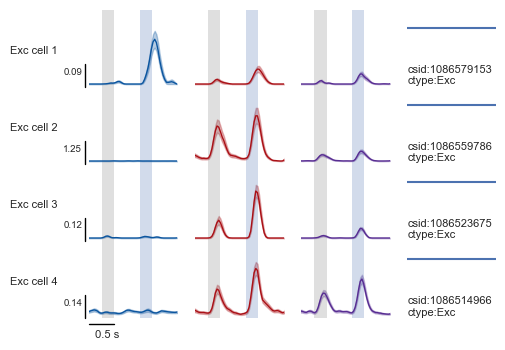

In [37]:
Exc_change_cells = [1086579153, 1086559786, 1086523675,  1086514966, 1086514622, 1120104688,  #1086514606, ]
                     1086558573, 1086527750, 1086517398, 1086577182, 1120108338, 1086510825, ]#1086558285, 1086519596, 1086529704, ]

event_type = 'changes'

pse.plot_selected_cell_examples(change_mdf, Exc_change_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 0.75], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Exc_changes')
    


In [38]:
Exc_change_cells = matched_cells_table[(matched_cells_table.cell_type=='Excitatory') & 
                                        (matched_cells_table.project_code=='VisualBehavior') &
                                        (matched_cells_table.binned_depth==175)].cell_specimen_id.unique()
Exc_change_cells = np.random.choice(Exc_change_cells, 10)

In [39]:
# for cell_specimen_id in Exc_change_cells:
#     pse.plot_matched_roi_mask_zoom(cell_specimen_id, platform_cells_table, platform_experiments, save_dir=save_dir)


###### Sst Inhibitory

In [40]:
# Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]
#                     # 1086559885, 1086619787, 1086553602, 1120094297]
# #1086575742, ]
# cell_type = 'Sst Inhibitory'
# event_type = 'images'
# df = each_image_mdf[(each_image_mdf.pref_stim==True) & (each_image_mdf.is_change==False)].copy()

# pse.plot_reliable_example_cells(df, Sst_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [41]:
# Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]
#                     # 1086559885, 1086619787, 1086553602, 1120094297]
# #1086575742, ]
# cell_type = 'Sst Inhibitory'
# event_type = 'changes'

# pse.plot_reliable_example_cells(change_mdf, Sst_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [42]:
# Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]
#                     # 1086559885, 1086619787, 1086553602, 1120094297]
# #1086575742, ]
# cell_type = 'Sst Inhibitory'
# event_type = 'changes'

# pse.plot_reliable_example_cells(change_mdf, Sst_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-1, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')

In [43]:
# Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]
#                     # 1086559885, 1086619787, 1086553602, 1120094297]
# #1086575742, ]
# cell_type = 'Sst Inhibitory'
# event_type = 'changes'

# pse.plot_reliable_example_cells(change_mdf, Sst_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-1, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


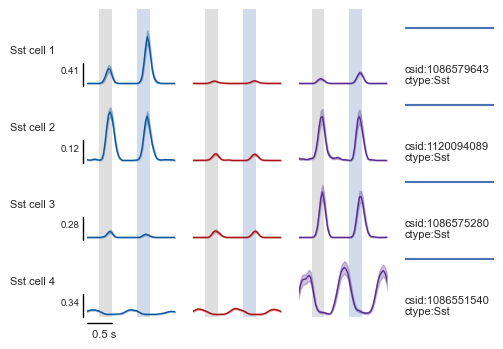

In [44]:
Sst_change_cells =  [1086579643, 1120094089, 1086575280, 1086551540, 1086581760, 1086572621, ]

cell_type = 'Sst Inhibitory'
event_type = 'changes'

pse.plot_selected_cell_examples(change_mdf, Sst_change_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 0.75], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Sst_changes')
    

In [45]:
    
# for cell_specimen_id in Sst_change_cells[:4]:
#     pse.plot_matched_roi_mask_zoom(cell_specimen_id, platform_cells_table, platform_experiments, save_dir=save_dir)


###### Vip Inhibitory

In [46]:
# Vip_change_cells = [1086673402, 1086501825, 1086627590, 1086514444, 1086627527, 1086514260, ] 

# itory'
# event_type = 'images'
# df = each_image_mdf[(each_image_mdf.pref_stim==True) & (each_image_mdf.is_change==False)].copy()

# pse.plot_reliable_example_cells(df, Vip_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [47]:

# Vip_change_cells = [1086673402, 1086501825, 1086627590, 1086514444, 1086627527, 1086514260, ] 
# # 1086627395, 1086673073, 1086519532, 1086516885, 1086615418, ]
# event_type='changes'
# cell_type = 'Vip Inhibitory'
# pse.plot_reliable_example_cells(change_mdf, Vip_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-0.25, 0.75],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


In [48]:
# event_type='changes'
# cell_type = 'Vip Inhibitory'
# pse.plot_reliable_example_cells(change_mdf, Vip_change_cells[:4], cell_type, event_type=event_type, 
#                                 xlim_seconds=[-1, 1.5],
#                                 save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


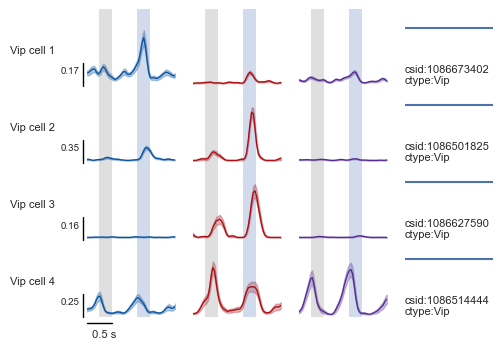

In [49]:
Vip_change_cells = [1086673402, 1086501825, 1086627590, 1086514444, 1086627527, 1086514260, ] 

event_type = 'changes'

pse.plot_selected_cell_examples(change_mdf, Vip_change_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 0.75], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Vip_changes')
    


In [50]:
# for cell_specimen_id in Vip_change_cells[4:]:
#     pse.plot_matched_roi_mask_zoom(cell_specimen_id, platform_cells_table, platform_experiments, save_dir=save_dir)


##### Image omissions

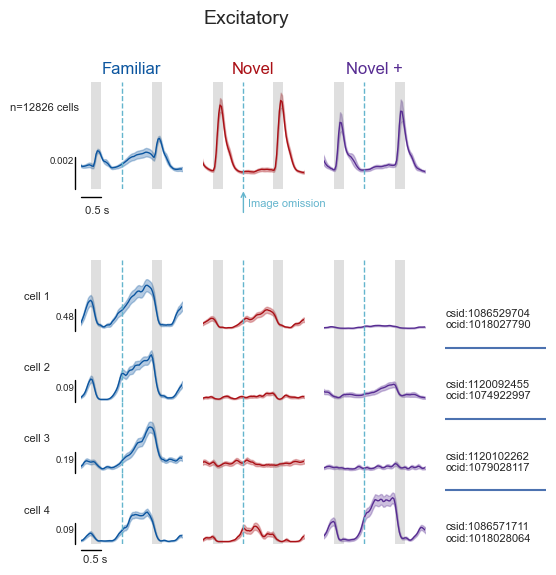

In [51]:
Exc_omission_cells = [ 1086529704, 1120092455, 1120102262, 1086571711,  1086514606, 
                      1086530117, 1120090879,  1086526518,]
event_type = 'omissions'

cell_type = 'Excitatory'
pse.plot_reliable_example_cells(omission_mdf, Exc_omission_cells[:4], cell_type, event_type=event_type, 
                                xlim_seconds=[-1, 1.5],
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')

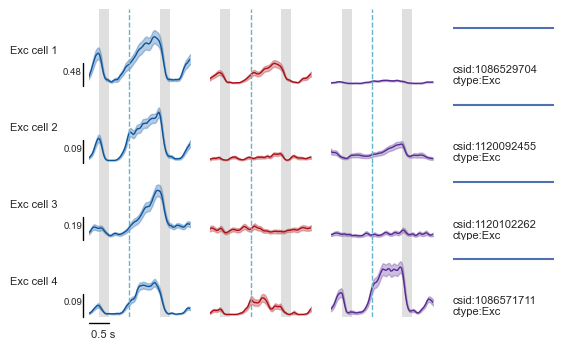

In [52]:
Exc_omission_cells = [ 1086529704, 1120092455, 1120102262, 1086571711,  1086514606, 
                      1086530117, 1120090879,  1086526518,]
event_type = 'omissions'

pse.plot_selected_cell_examples(omission_mdf, Exc_omission_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 1.5], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Exc_omissions')
    


24


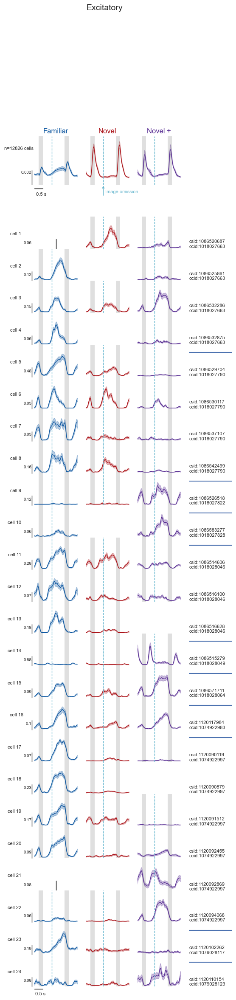

In [53]:
cell_types = utils.get_cell_types()
cell_type = 'Excitatory'
# for cell_type in cell_types: 
event_type = 'omissions'
# get reliable cells for this cell type
reliable_cells = omission_mdf[(omission_mdf.fraction_significant_p_value_gray_screen>0.15) & 
            (omission_mdf.mean_response > 0.1) &
            (omission_mdf.cell_type==cell_type)]
reliable_cells = reliable_cells.sort_values(by=['ophys_container_id', 'cell_specimen_id'])
cells_to_plot = reliable_cells.cell_specimen_id.unique()
print(len(cells_to_plot))

pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type, 
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_top_cells')

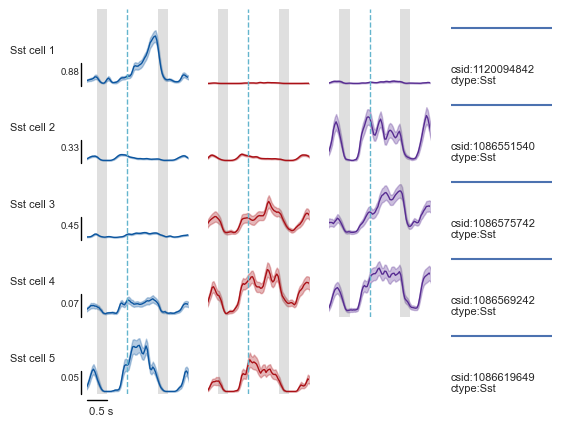

In [54]:
Sst_omission_cells = [1120094842, 1086551540, 1086575742, 1086569242, 
                       1086619649,]

event_type = 'omissions'

pse.plot_selected_cell_examples(omission_mdf, Sst_omission_cells, event_type=event_type,
                                xlim_seconds=[-1, 1.5], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Sst_omissions')
    


12


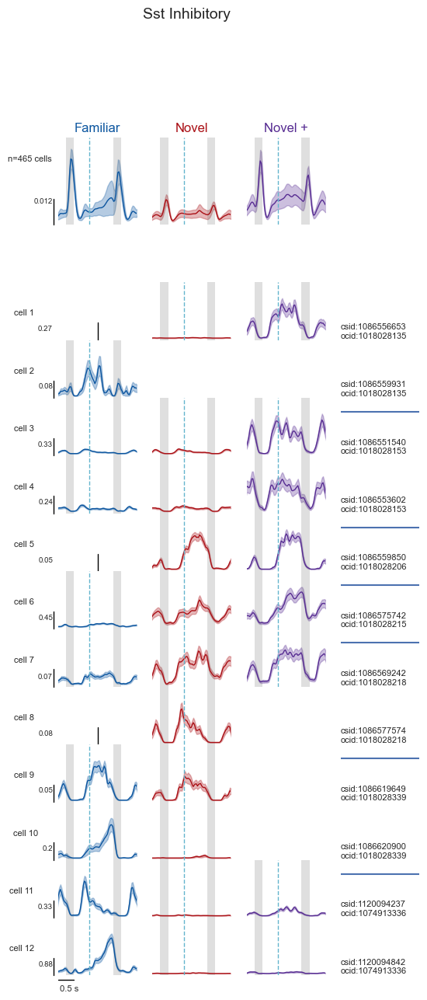

In [55]:
cell_types = utils.get_cell_types()
cell_type = 'Sst Inhibitory'
# for cell_type in cell_types: 
event_type = 'omissions'
# get reliable cells for this cell type
reliable_cells = omission_mdf[(omission_mdf.fraction_significant_p_value_gray_screen>0.15) & 
            (omission_mdf.mean_response > 0.1) &
            (omission_mdf.cell_type==cell_type)]
reliable_cells = reliable_cells.sort_values(by=['ophys_container_id', 'cell_specimen_id'])
cells_to_plot = reliable_cells.cell_specimen_id.unique()
print(len(cells_to_plot))

pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type, 
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_top_cells')

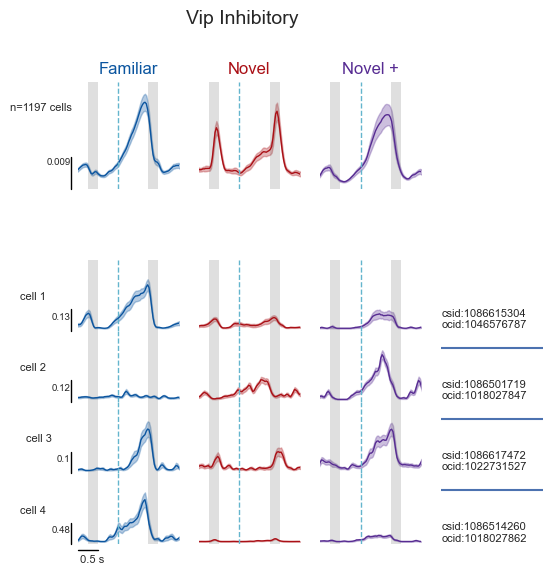

In [56]:
Vip_omission_cells = [1086615304, 1086501719, 1086617472, 1086514260, 1086616294, 1086514444, 
                      1086614936 ,1086614349, 1086510096, 1086673225,  1086516885, 1086627910,  ]
                      
event_type = 'omissions'

cell_type = 'Vip Inhibitory'
pse.plot_reliable_example_cells(omission_mdf, Vip_omission_cells[:4], cell_type, event_type=event_type, 
                                xlim_seconds=[-1, 1.5],
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_selected')


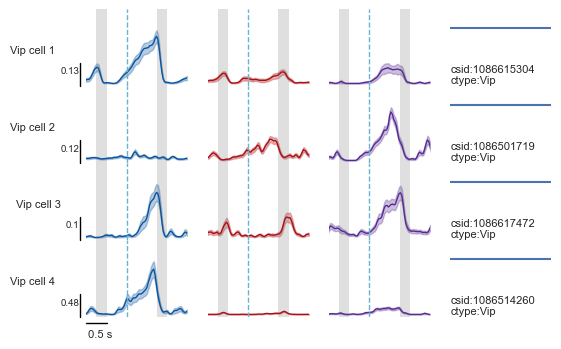

In [57]:
Vip_omission_cells = [1086615304, 1086501719, 1086617472, 1086514260, 1086616294, 1086514444, 
                      1086614936 ,1086614349, 1086510096, 1086673225,  1086516885, 1086627910,  ]
                      
event_type = 'omissions'


pse.plot_selected_cell_examples(omission_mdf, Vip_omission_cells[:4], event_type=event_type,
                                xlim_seconds=[-1, 1.5], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_Vip_omissions')
    


56


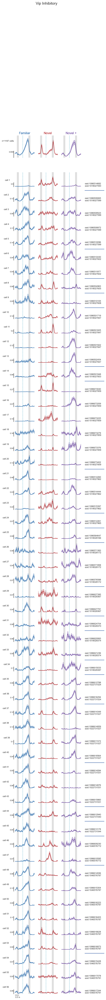

In [58]:
cell_types = utils.get_cell_types()
cell_type = 'Vip Inhibitory'
# for cell_type in cell_types: 
event_type = 'omissions'
# get reliable cells for this cell type
reliable_cells = omission_mdf[(omission_mdf.fraction_significant_p_value_gray_screen>0.05) & 
            (omission_mdf.mean_response > 0.05) &
            (omission_mdf.cell_type==cell_type)]
reliable_cells = reliable_cells[reliable_cells.cell_specimen_id.isin(matched_cells)]
reliable_cells = reliable_cells.sort_values(by=['ophys_container_id', 'cell_specimen_id'])
cells_to_plot = reliable_cells.cell_specimen_id.unique()
print(len(cells_to_plot))

pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type, 
                                save_dir=save_dir, folder='reliable_example_cells', suffix='_top_cells')

##### Omission examples sampled from the omission modulation index distribution

Excitatory enhanced: 83 candidate cells with fraction_significant_p_value_gray_screen > 0.15, plotting 20
Excitatory suppressed: 149 candidate cells with reliability > 0.1, plotting 10
Excitatory silent: 87 candidate cells with reliability > 0.1, plotting 10
Sst Inhibitory enhanced: 17 candidate cells with fraction_significant_p_value_gray_screen > 0.15, plotting 17
Sst Inhibitory suppressed: 8 candidate cells with reliability > 0.1, plotting 8
Sst Inhibitory silent: 386 candidate cells (no reliability criterion), plotting 10
Vip Inhibitory enhanced: 83 candidate cells with fraction_significant_p_value_gray_screen > 0.15, plotting 20
Vip Inhibitory suppressed: 22 candidate cells with reliability > 0.1, plotting 10
Vip Inhibitory silent: 9 candidate cells with reliability > 0.1, plotting 9


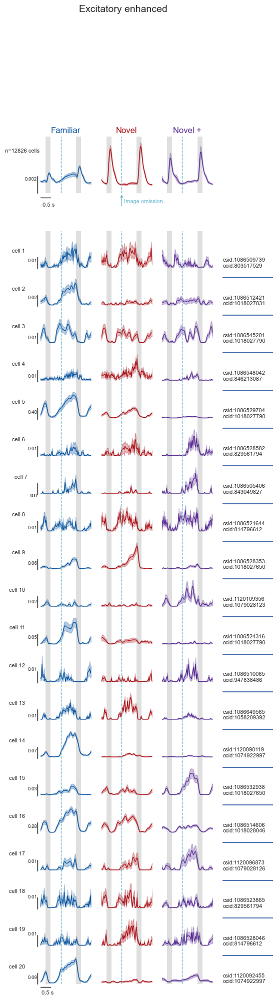

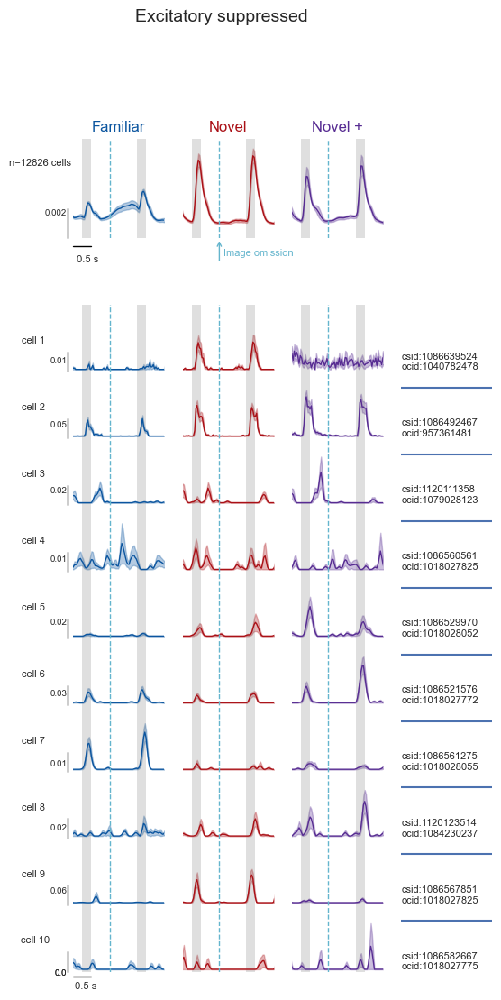

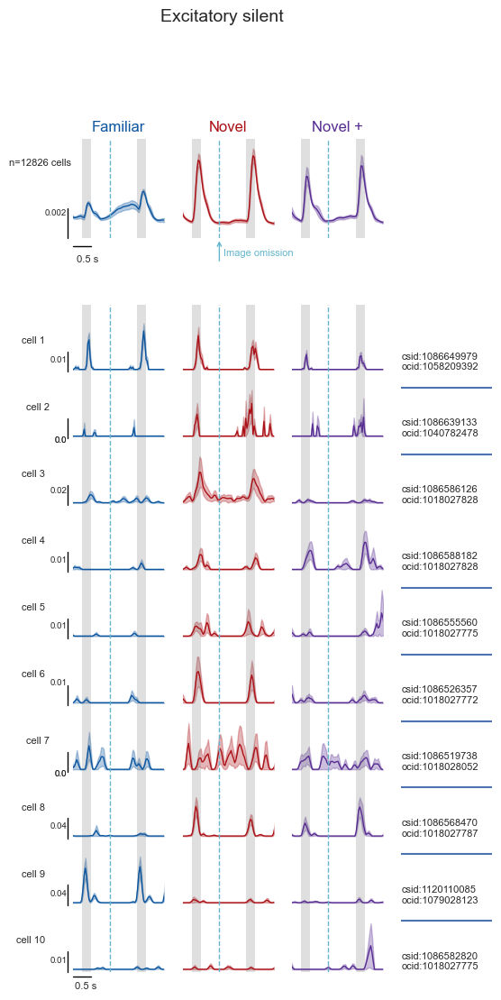

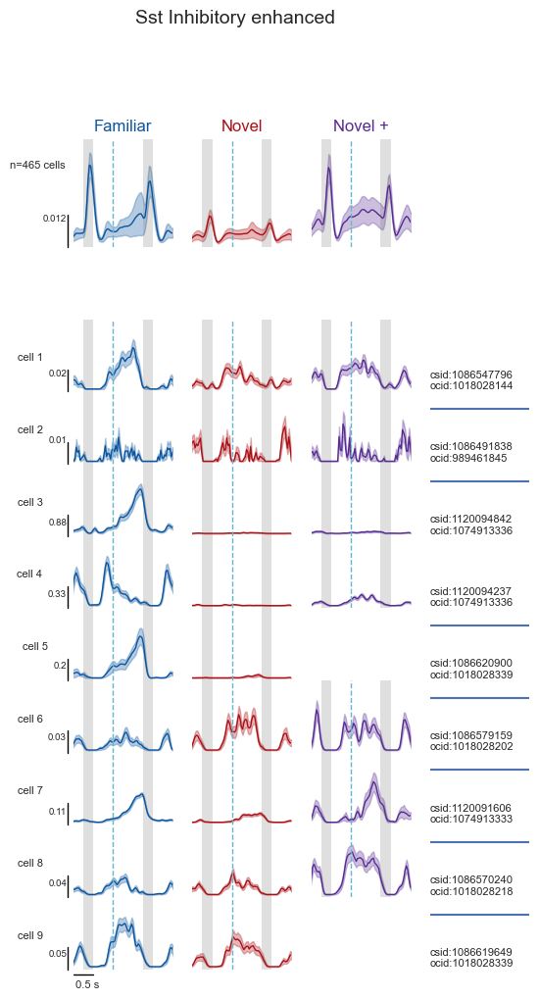

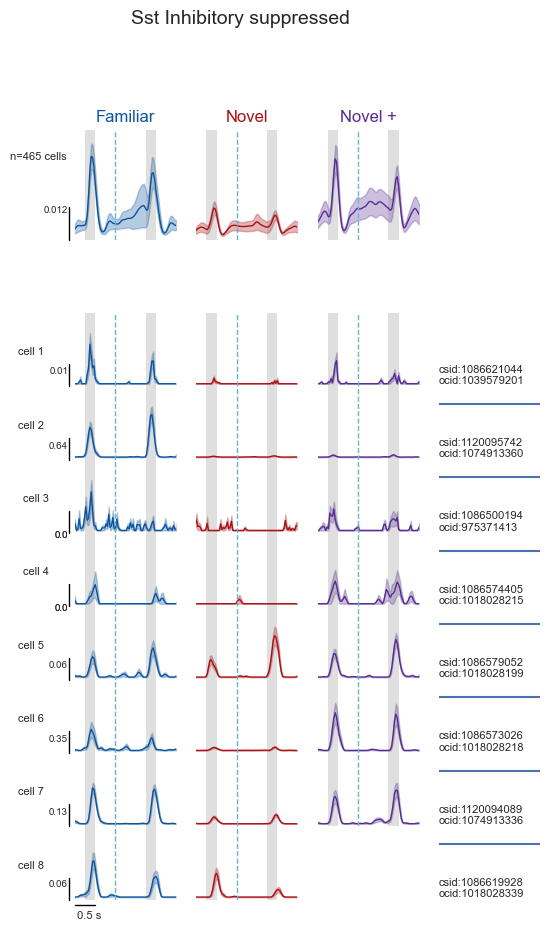

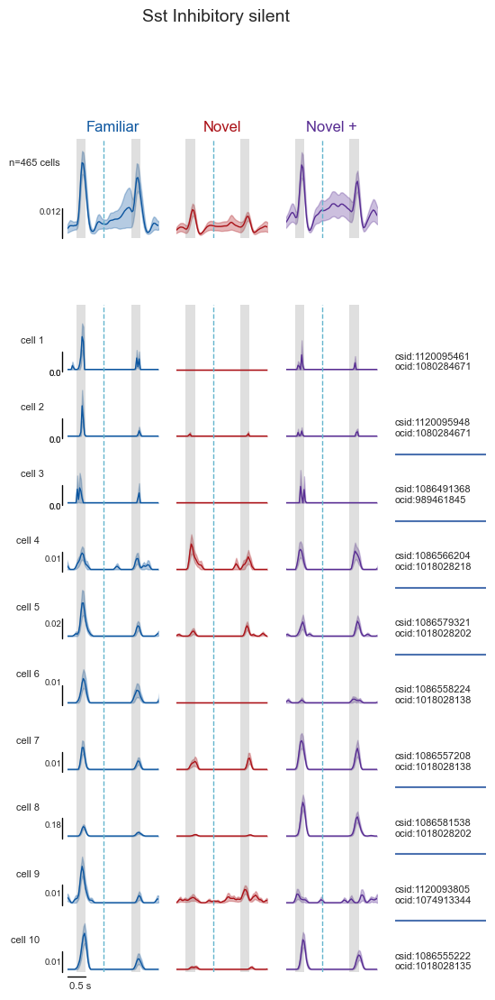

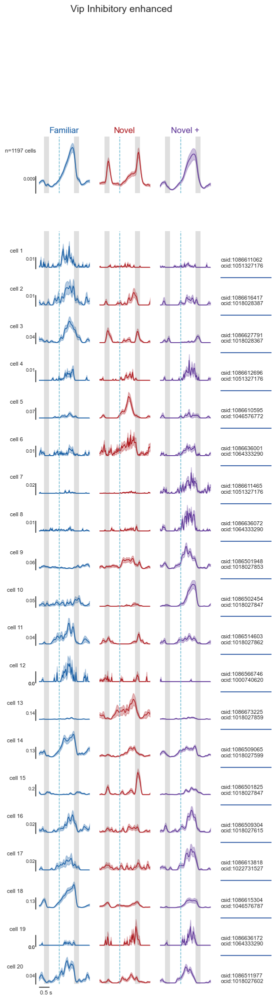

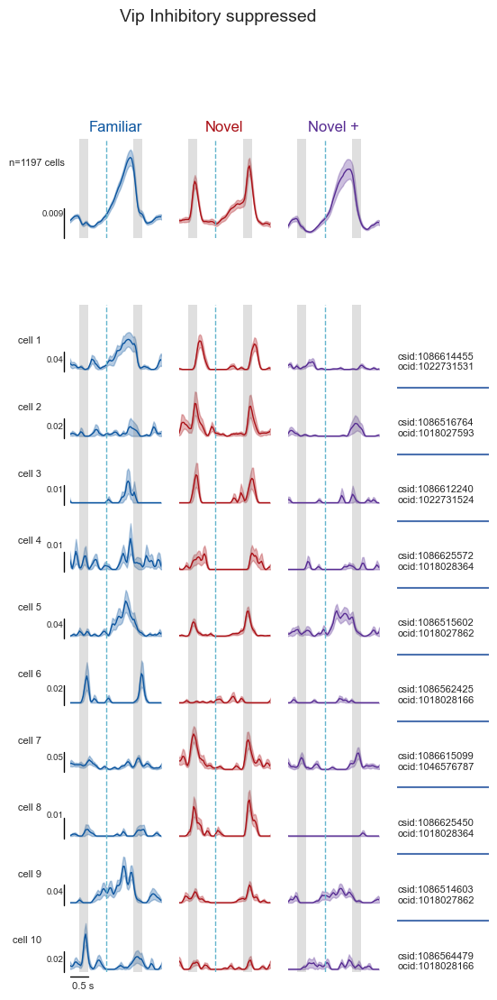

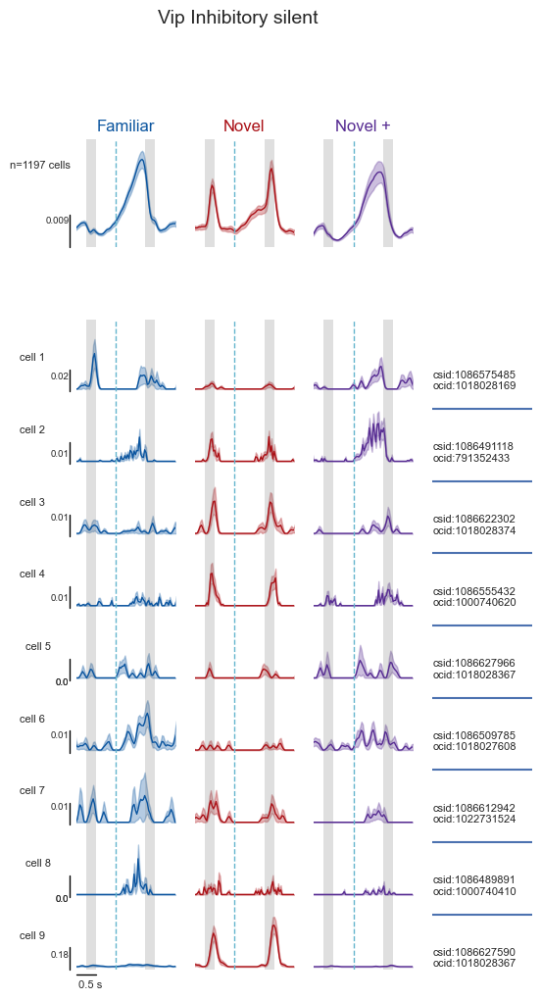

In [59]:
# Reviewer request (Fig 5H): pick omission example cells from the omission modulation index (OMI) distribution.
# For each cell type, pool cell-sessions across all experience levels and bin on the OMI value:
#   enhanced:   OMI > 0.5            filtered on fraction_significant_p_value_gray_screen > 0.1
#   suppressed: -1 < OMI < -0.5      filtered on reliability > 0.1 (excludes the pile-up at OMI = -1)
#   silent:     OMI = -1             filtered on reliability > 0.1 (no omission response at all)
# n_cells[bin] are drawn at random (fixed seed) from the candidates in each bin.
n_cells = {'enhanced': 20, 'suppressed': 10, 'silent': 10}
seed = 0
bin_filters = {'enhanced': ('fraction_significant_p_value_gray_screen', 0.15),
               'suppressed': ('reliability', 0.1),
               'silent': ('reliability', 0.1)}
event_type = 'omissions'

omi = metrics_table[['cell_specimen_id', 'ophys_experiment_id', 'omission_modulation_index']].drop_duplicates()
assert not omi.duplicated(['cell_specimen_id', 'ophys_experiment_id']).any()
omi_df = omission_mdf.merge(omi, on=['cell_specimen_id', 'ophys_experiment_id'], how='left')
omi_df = omi_df[omi_df.cell_specimen_id.isin(matched_cells)]

omi_example_cells = {}
for cell_type in utils.get_cell_types():
    ct_df = omi_df[(omi_df.cell_type == cell_type) & omi_df.omission_modulation_index.notnull()]
    omi_vals = ct_df.omission_modulation_index
    silent = np.isclose(omi_vals, -1)
    bin_masks = {'enhanced': omi_vals > 0.75,
                 'suppressed': (omi_vals < -0.75) & ~silent,
                 'silent': silent}
    for bin_name, in_omi_bin in bin_masks.items():
        filter_col, threshold = bin_filters[bin_name]
        in_bin = ct_df[in_omi_bin & (ct_df[filter_col] > threshold)]
        if len(in_bin)<5: # if there are no reliable cells in bin, drop the reliability criterion
            in_bin = ct_df[in_omi_bin]
            print(f'{cell_type} {bin_name}: {len(in_bin)} candidate cells (no {filter_col} criterion), '
                  f'plotting {min(n_cells[bin_name], len(in_bin))}')
        else: 
            print(f'{cell_type} {bin_name}: {len(in_bin)} candidate cells with {filter_col} > {threshold}, '
                  f'plotting {min(n_cells[bin_name], len(in_bin))}')        
        candidates = in_bin.cell_specimen_id.unique()
        rng = np.random.default_rng(seed)
        cells_to_plot = list(rng.choice(candidates, size=min(n_cells[bin_name], len(candidates)), replace=False))
        omi_example_cells[(cell_type, bin_name)] = cells_to_plot
        if len(cells_to_plot) == 0:
            continue
        pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type,
                                        save_dir=save_dir, folder='reliable_example_cells',
                                        suptitle=f'{cell_type} {bin_name}', suffix=f'_omi_{bin_name}')

#### Top and bottom 5% examples

Excitatory bottom5: OMI [-1.00, -1.00], 89 candidate cells, plotting 10
Excitatory middle5: OMI [-0.87, -0.77], 81 candidate cells, plotting 10
Excitatory top5: OMI [0.82, 1.00], 89 candidate cells, plotting 20
Sst Inhibitory bottom5: OMI [-1.00, -1.00], 2 candidate cells, plotting 2
Sst Inhibitory middle5: OMI [-1.00, -1.00], 2 candidate cells, plotting 2
Sst Inhibitory top5: OMI [0.75, 1.00], 10 candidate cells, plotting 10
Vip Inhibitory bottom5: OMI [-1.00, -0.98], 14 candidate cells, plotting 10
Vip Inhibitory middle5: OMI [0.31, 0.43], 16 candidate cells, plotting 10
Vip Inhibitory top5: OMI [1.00, 1.00], 24 candidate cells, plotting 20


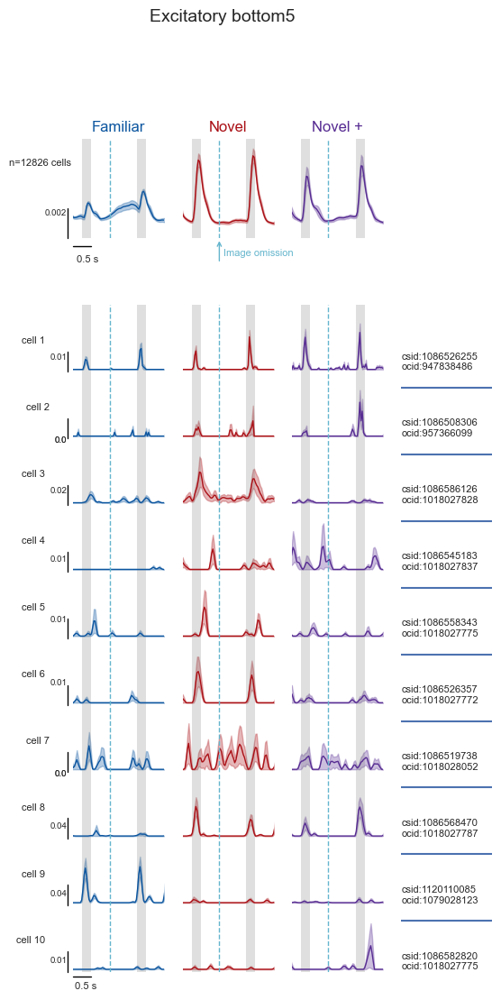

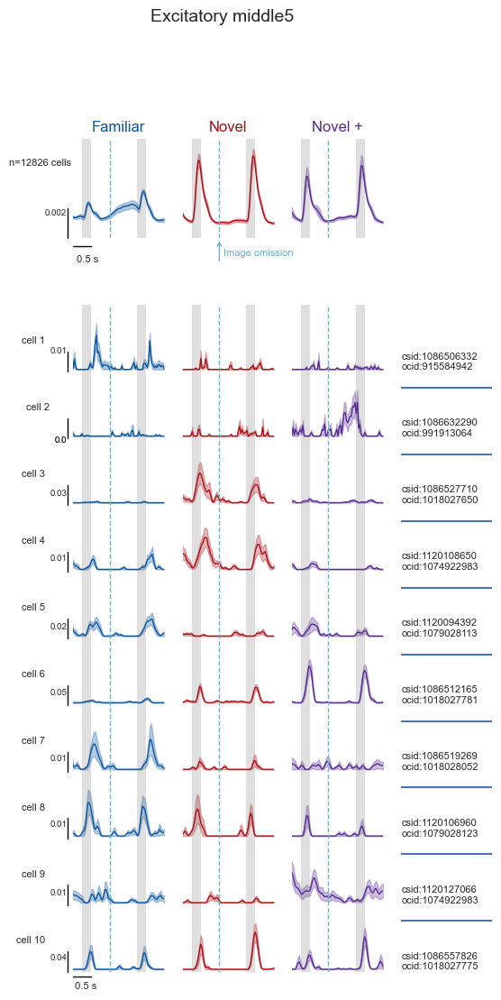

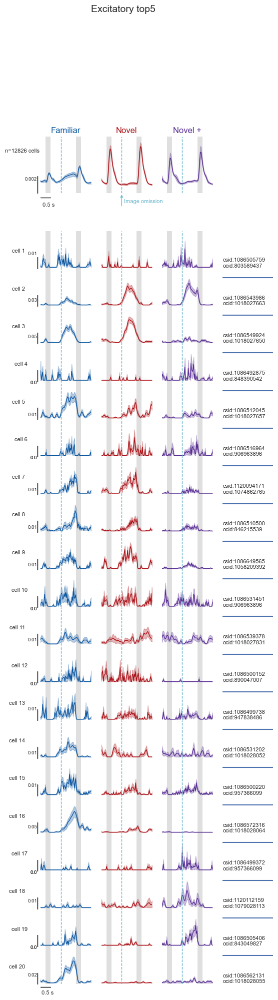

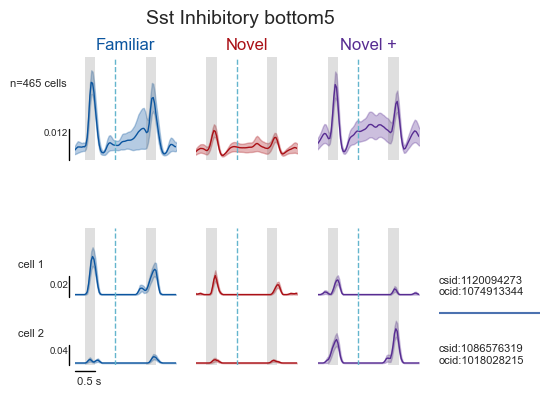

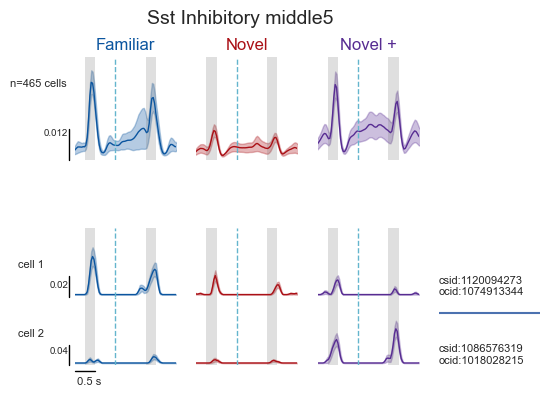

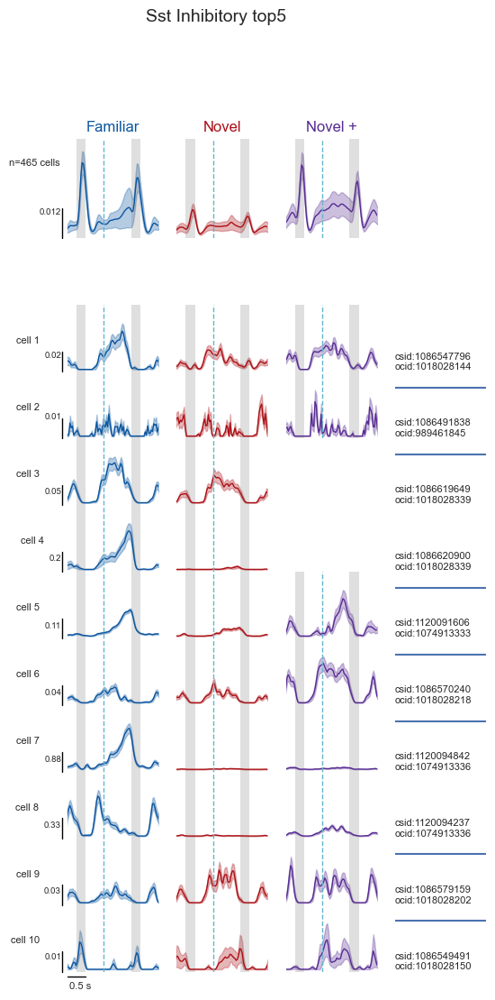

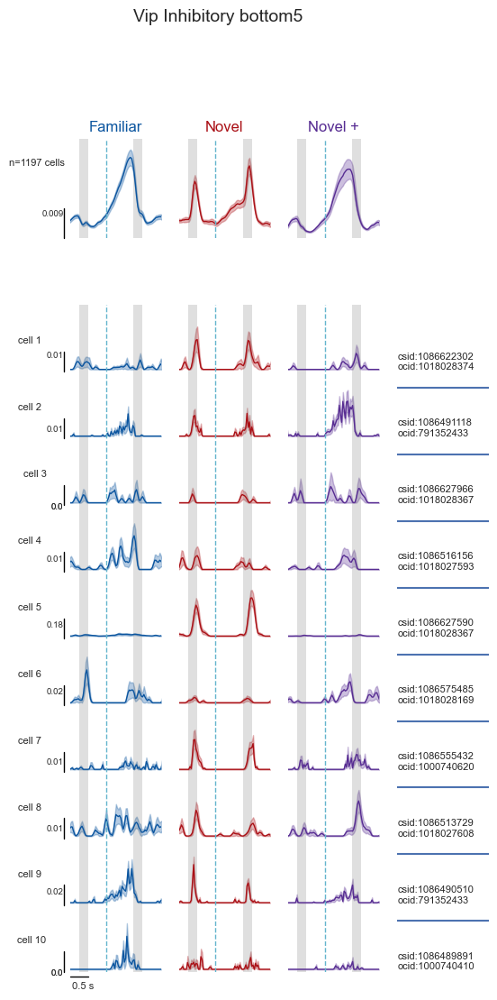

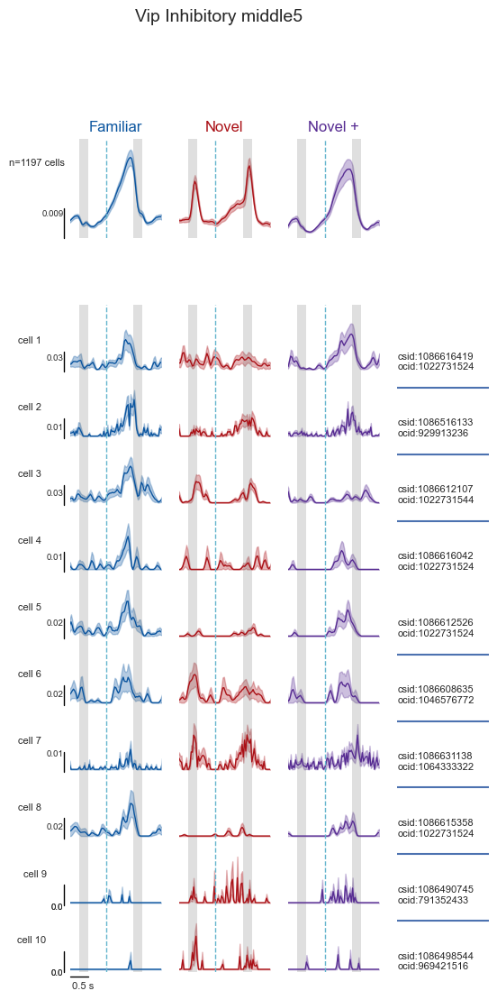

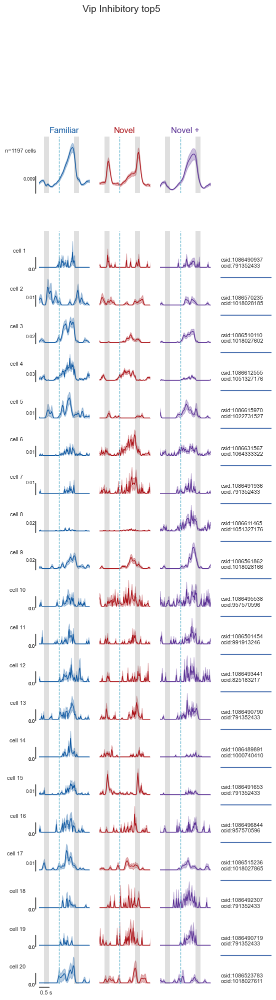

In [60]:
# Omission examples from the bottom / middle / top 5% of the omission modulation index (OMI) distribution.
# For each cell type, pool matched cell-sessions across all experience levels and take percentile bins of OMI.
# Top 5% requires fraction_significant_p_value_gray_screen > 0.1; bottom and middle 5% have no filter.
# n_cells[bin] are drawn at random (fixed seed) from the candidates in each bin.
n_cells = {'bottom5': 10, 'middle5': 10, 'top5': 20}
pct_bins = {'bottom5': (0, 5), 'middle5': (47.5, 52.5), 'top5': (95, 100)}
seed = 0
event_type = 'omissions'

omi = metrics_table[['cell_specimen_id', 'ophys_experiment_id', 'omission_modulation_index']].drop_duplicates()
assert not omi.duplicated(['cell_specimen_id', 'ophys_experiment_id']).any()
omi_df = omission_mdf.merge(omi, on=['cell_specimen_id', 'ophys_experiment_id'], how='left')
omi_df = omi_df[omi_df.cell_specimen_id.isin(matched_cells)]

omi_pct_example_cells = {}
for cell_type in utils.get_cell_types():
    ct_df = omi_df[(omi_df.cell_type == cell_type) & omi_df.omission_modulation_index.notnull()]
    for bin_name, (lo, hi) in pct_bins.items():
        lo_val, hi_val = np.percentile(ct_df.omission_modulation_index, [lo, hi])
        in_bin = ct_df[ct_df.omission_modulation_index.between(lo_val, hi_val)]
        if bin_name == 'top5':
            in_bin = in_bin[(in_bin.fraction_significant_p_value_gray_screen > 0.05)]
        else: 
            in_bin = in_bin[in_bin.reliability > 0.05]
        candidates = in_bin.cell_specimen_id.unique()
        rng = np.random.default_rng(seed)
        cells_to_plot = list(rng.choice(candidates, size=min(n_cells[bin_name], len(candidates)), replace=False))
        omi_pct_example_cells[(cell_type, bin_name)] = cells_to_plot
        print(f'{cell_type} {bin_name}: OMI [{lo_val:.2f}, {hi_val:.2f}], '
              f'{len(candidates)} candidate cells, plotting {len(cells_to_plot)}')
        if len(cells_to_plot) == 0:
            continue
        pse.plot_reliable_example_cells(omission_mdf, cells_to_plot, cell_type, event_type=event_type,
                                        save_dir=save_dir, folder='reliable_example_cells',
                                        suptitle=f'{cell_type} {bin_name}', suffix=f'_omi_{bin_name}')

#### Selected omission examples with position in the omission modulation index distribution

In [61]:
CHANGE_CELLS = {
    'Excitatory':     [1086523675, 1086512165, 1086579153],
    'Sst Inhibitory': [1120094089, 1086575280, 1086579643],
    'Vip Inhibitory': [1086627590, 1086501825, 1086615304],
}

OMISSION_CELLS = {
    'Excitatory':     [1086523675, 1086512165, 1120090119,], 
    'Sst Inhibitory': [1120094089, 1086579643, 1086569242,],                                                   # 108656942 -> 1086569242
    'Vip Inhibitory': [1086627590, 1086615304, 1086501922,]
}

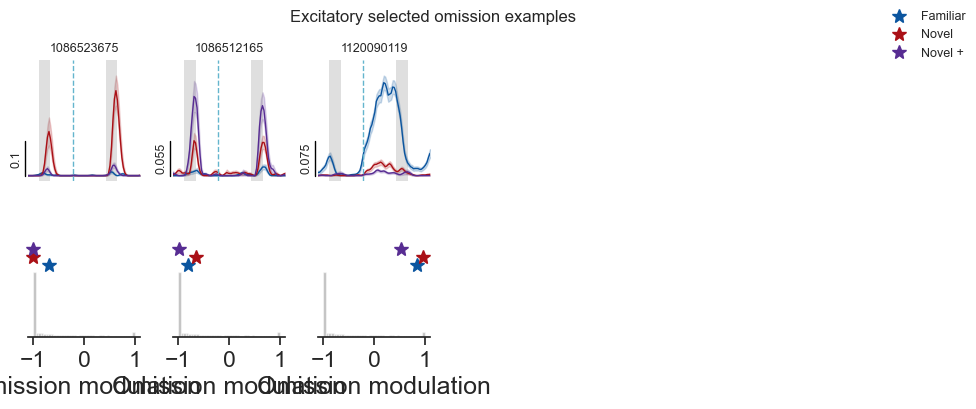

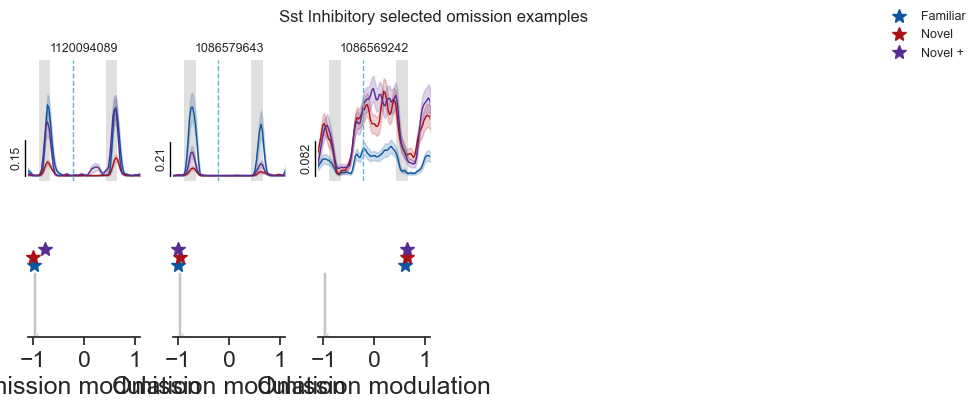

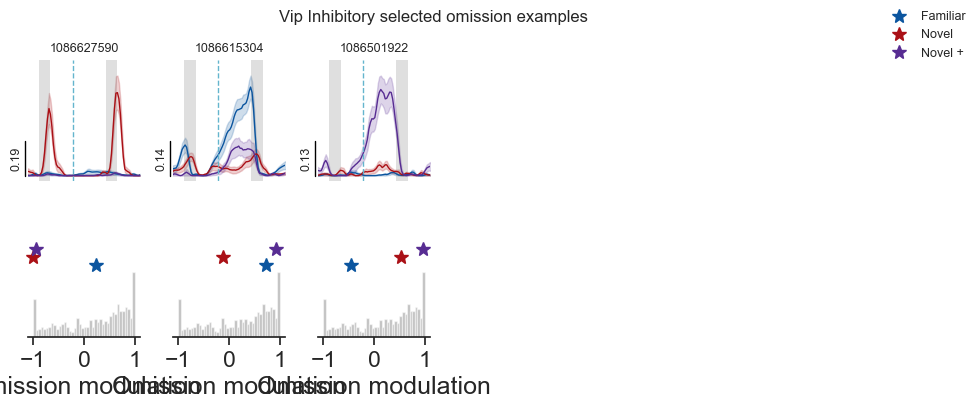

In [62]:
# Selected omission example cells in the Fig 5 style (Familiar / Novel / Novel+ overlaid), each paired with
# where the cell falls in its cell type's omission modulation index (OMI) distribution.
# Batches of 6 cells -> one 2 x 6 figure: top row = mean omission response, bottom row = pooled OMI
# distribution (matched cells, all experience levels, as used for selection) with a star per experience level
# at this cell's OMI in that session.
SELECTED_OMISSION_CELLS = {
    'Excitatory':     [1086559786, 1086512165, 1120090119, 1120133471, 1086518655, 1086557826, 1086512642, 1220092455,
                       1086543986, 1086529704, 1120092455, 1120102262, 1086571711, 1086557826,
                       1086579153, 1086523675],  # 112010262 -> 1120102262
    'Sst Inhibitory': [1120094089, 1086579643, 1086569242, 1086555222, 1086558224, 1086570240, 1120094842, 1086547796, 1086579052,
                       1120094089, 1086575280],                                                   # 108656942 -> 1086569242
    'Vip Inhibitory': [1086627590, 1086615304, 1086501922, 1086614455,  1086509065, 1086501719,  1086617472, 
                       1086673402, 1086501825, 1086627590]
}


SELECTED_OMISSION_CELLS = {
    'Excitatory':     [1086523675, 1086512165, 1120090119,], 
    'Sst Inhibitory': [1120094089, 1086579643, 1086569242,],                                                   # 108656942 -> 1086569242
    'Vip Inhibitory': [1086627590, 1086615304, 1086501922,]
}

# # THESE ARE ACTUALLY THE CHANGE CELLS
# SELECTED_OMISSION_CELLS = {
#     'Excitatory':     [1086523675, 1086512165, 1086579153],
#     'Sst Inhibitory': [1120094089, 1086575280, 1086579643],
#     'Vip Inhibitory': [1086627590, 1086501825, 1086615304],
# }



# put in change row for Sst: 1086579643,
batch_size = 6
xlim = [-1, 1.5]
EXP = utils.get_experience_levels()
exp_colors = utils.get_experience_level_colors()
omi_bin_edges = np.linspace(-1, 1, 41)

omi = metrics_table[['cell_specimen_id', 'ophys_experiment_id', 'omission_modulation_index']].drop_duplicates()
assert not omi.duplicated(['cell_specimen_id', 'ophys_experiment_id']).any()
omi_df = omission_mdf.merge(omi, on=['cell_specimen_id', 'ophys_experiment_id'], how='left')
omi_df = omi_df[omi_df.cell_specimen_id.isin(matched_cells)]


def plot_overlaid_omission_cell(ax, csid):
    """mean +/- sem omission response for each experience level, overlaid (same style as the composite)."""
    cdf = omission_mdf[omission_mdf.cell_specimen_id == csid]
    ts = None
    for e, exp in enumerate(EXP):
        d = cdf[cdf.experience_level == exp]
        if len(d) == 0:
            continue
        utils.plot_mean_trace_from_mean_df(d, ylabel='', xlabel='', xlims=xlim, alpha=0.2,
                                           color=exp_colors[e], interval_sec=1, linewidth=1, ax=ax)
        ts = d.trace_timestamps.values[0]
    if ts is not None:
        utils.plot_flashes_on_trace(ax, ts, change=False, omitted=True, alpha=0.25, linewidth=1)
    ax.set_xlim(xlim)
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(min(ymin, 0), ymax * 1.1)
    ymin, ymax = ax.get_ylim()
    bar = float(f'{ymax * .3:.2g}')
    ax.set_yticks([])
    x_bar = xlim[0] - (xlim[1] - xlim[0]) * 0.03
    ax.axvline(x=x_bar, ymin=(0 - ymin) / (ymax - ymin), ymax=(bar - ymin) / (ymax - ymin),
               color='k', linewidth=1, clip_on=False)
    ax.annotate(f'{bar:g}', xy=(x_bar, bar / 2), xycoords='data', xytext=(-2, 0), textcoords='offset points',
                rotation=90, ha='right', va='center', fontsize=9, annotation_clip=False)
    ax.set_xlabel(''); ax.set_ylabel('')
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
    ax.tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
    ax.set_xticks([])


def plot_omi_position(ax, ct_omi, csid):
    """pooled OMI histogram for the cell type + a star per experience level at this cell's OMI."""
    ax.hist(ct_omi.omission_modulation_index, bins=omi_bin_edges, density=True, color='gray', alpha=0.5)
    ymax = ax.get_ylim()[1]
    cell_rows = ct_omi[ct_omi.cell_specimen_id == csid]
    for e, exp in enumerate(EXP):
        vals = cell_rows[cell_rows.experience_level == exp].omission_modulation_index.values
        if len(vals):   # stagger stars vertically so identical values (e.g. 1) stay visible
            ax.plot(vals[0], ymax * (1.05 + 0.12 * e), marker='*', markersize=10, color=exp_colors[e],
                    clip_on=False, linestyle='')
    ax.set_xlim(-1.1, 1.1)
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([])
    ax.set_xlabel('Omission modulation')
    sns.despine(ax=ax, left=True)


for cell_type, cells in SELECTED_OMISSION_CELLS.items():
    ct_omi = omi_df[(omi_df.cell_type == cell_type) & omi_df.omission_modulation_index.notnull()]
    cells = list(dict.fromkeys(cells))                          # drop duplicate IDs, keep order
    missing = [c for c in cells if c not in set(ct_omi.cell_specimen_id)]
    if missing:
        print(f'{cell_type}: not found among matched {cell_type} cells with OMI, skipping {missing}')
    cells = [c for c in cells if c not in missing]
    for b in range(0, len(cells), batch_size):
        batch = cells[b:b + batch_size]
        figsize = (1.8 * batch_size, 3.6)
        fig, ax = plt.subplots(2, batch_size, figsize=figsize, gridspec_kw={'height_ratios': [1.3, 1]})
        for j in range(batch_size):
            if j >= len(batch):
                ax[0, j].axis('off'); ax[1, j].axis('off')
                continue
            plot_overlaid_omission_cell(ax[0, j], batch[j])
            ax[0, j].set_title(str(batch[j]), fontsize=9)
            plot_omi_position(ax[1, j], ct_omi, batch[j])
        handles = [plt.Line2D([], [], marker='*', color=c, linestyle='', markersize=10) for c in exp_colors]
        fig.legend(handles, EXP, loc='upper right', fontsize=9, frameon=False)
        fig.suptitle(f'{cell_type} selected omission examples', x=0.5, y=1.02, fontsize=12)
        fig.subplots_adjust(hspace=0.6, wspace=0.3)
        utils.save_figure(fig, figsize, save_dir, 'reliable_example_cells',
                          f'{cell_type}_omission_selected_with_omi_batch{b // batch_size + 1}')

#### Selected change example cells

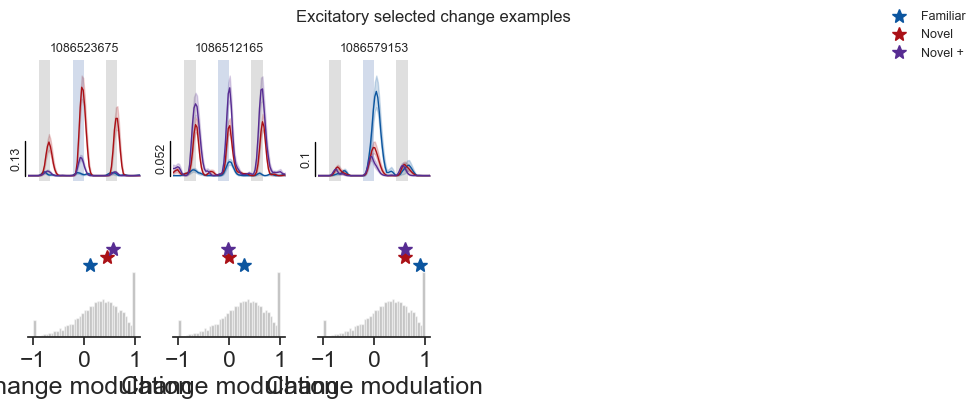

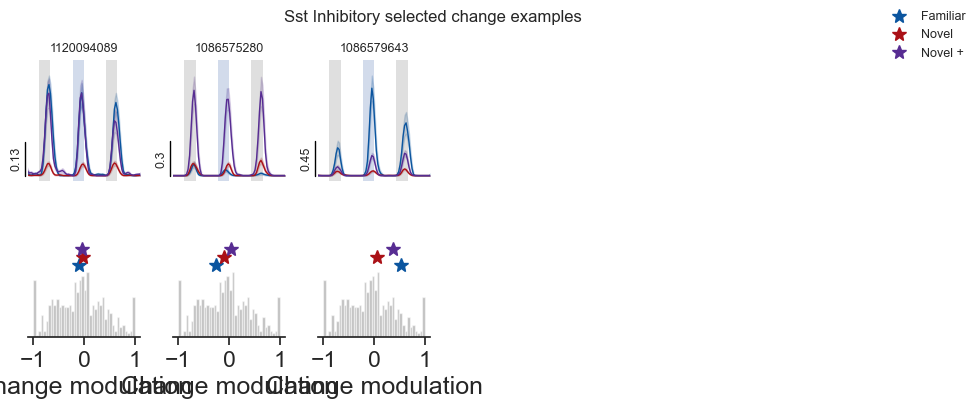

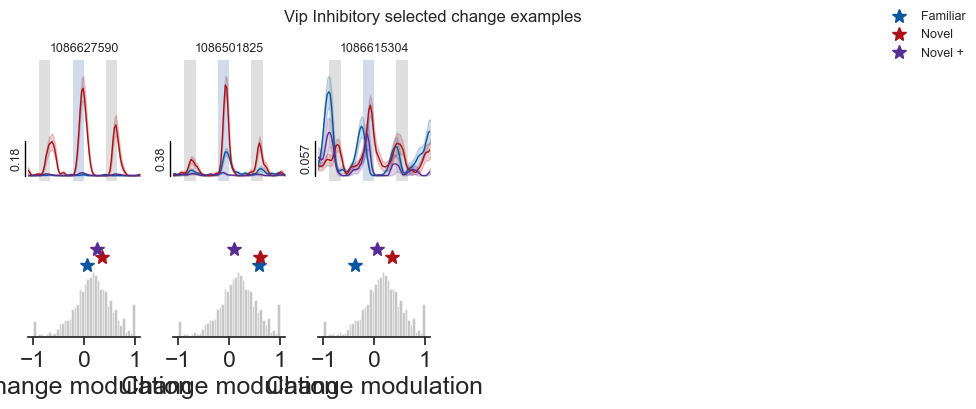

In [63]:

SELECTED_CHANGE_CELLS = {
    'Excitatory':     [1086523675, 1086512165, 1086579153],
    'Sst Inhibitory': [1120094089, 1086575280, 1086579643],
    'Vip Inhibitory': [1086627590, 1086501825, 1086615304],
}

# put in change row for Sst: 1086579643,
batch_size = 6
xlim = [-1, 1.5]
EXP = utils.get_experience_levels()
exp_colors = utils.get_experience_level_colors()
omi_bin_edges = np.linspace(-1, 1, 41)

cmi = metrics_table[['cell_specimen_id', 'ophys_experiment_id', 'change_modulation_index']].drop_duplicates()
assert not cmi.duplicated(['cell_specimen_id', 'ophys_experiment_id']).any()
cmi_df = change_mdf.merge(cmi, on=['cell_specimen_id', 'ophys_experiment_id'], how='left')
cmi_df = cmi_df[cmi_df.cell_specimen_id.isin(matched_cells)]


def plot_overlaid_change_cell(ax, csid):
    """mean +/- sem change response for each experience level, overlaid (same style as the composite)."""
    cdf = change_mdf[change_mdf.cell_specimen_id == csid]
    ts = None
    for e, exp in enumerate(EXP):
        d = cdf[cdf.experience_level == exp]
        if len(d) == 0:
            continue
        utils.plot_mean_trace_from_mean_df(d, ylabel='', xlabel='', xlims=xlim, alpha=0.2,
                                           color=exp_colors[e], interval_sec=1, linewidth=1, ax=ax)
        ts = d.trace_timestamps.values[0]
    if ts is not None:
        utils.plot_flashes_on_trace(ax, ts, change=True, omitted=False, alpha=0.25, linewidth=1)
    ax.set_xlim(xlim)
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(min(ymin, 0), ymax * 1.1)
    ymin, ymax = ax.get_ylim()
    bar = float(f'{ymax * .3:.2g}')
    ax.set_yticks([])
    x_bar = xlim[0] - (xlim[1] - xlim[0]) * 0.03
    ax.axvline(x=x_bar, ymin=(0 - ymin) / (ymax - ymin), ymax=(bar - ymin) / (ymax - ymin),
               color='k', linewidth=1, clip_on=False)
    ax.annotate(f'{bar:g}', xy=(x_bar, bar / 2), xycoords='data', xytext=(-2, 0), textcoords='offset points',
                rotation=90, ha='right', va='center', fontsize=9, annotation_clip=False)
    ax.set_xlabel(''); ax.set_ylabel('')
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
    ax.tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
    ax.set_xticks([])


def plot_cmi_position(ax, ct_omi, csid):
    """pooled CMI histogram for the cell type + a star per experience level at this cell's CMI."""
    ax.hist(ct_omi.change_modulation_index, bins=omi_bin_edges, density=True, color='gray', alpha=0.5)
    ymax = ax.get_ylim()[1]
    cell_rows = ct_omi[ct_omi.cell_specimen_id == csid]
    for e, exp in enumerate(EXP):
        vals = cell_rows[cell_rows.experience_level == exp].change_modulation_index.values
        if len(vals):   # stagger stars vertically so identical values (e.g. 1) stay visible
            ax.plot(vals[0], ymax * (1.05 + 0.12 * e), marker='*', markersize=10, color=exp_colors[e],
                    clip_on=False, linestyle='')
    ax.set_xlim(-1.1, 1.1)
    ax.set_xticks([-1, 0, 1])
    ax.set_yticks([])
    ax.set_xlabel('Change modulation')
    sns.despine(ax=ax, left=True)


for cell_type, cells in SELECTED_CHANGE_CELLS.items():
    ct_omi = cmi_df[(cmi_df.cell_type == cell_type) & cmi_df.change_modulation_index.notnull()]
    cells = list(dict.fromkeys(cells))                          # drop duplicate IDs, keep order
    missing = [c for c in cells if c not in set(ct_omi.cell_specimen_id)]
    if missing:
        print(f'{cell_type}: not found among matched {cell_type} cells with OMI, skipping {missing}')
    cells = [c for c in cells if c not in missing]
    for b in range(0, len(cells), batch_size):
        batch = cells[b:b + batch_size]
        figsize = (1.8 * batch_size, 3.6)
        fig, ax = plt.subplots(2, batch_size, figsize=figsize, gridspec_kw={'height_ratios': [1.3, 1]})
        for j in range(batch_size):
            if j >= len(batch):
                ax[0, j].axis('off'); ax[1, j].axis('off')
                continue
            plot_overlaid_change_cell(ax[0, j], batch[j])
            ax[0, j].set_title(str(batch[j]), fontsize=9)
            plot_cmi_position(ax[1, j], ct_omi, batch[j])
        handles = [plt.Line2D([], [], marker='*', color=c, linestyle='', markersize=10) for c in exp_colors]
        fig.legend(handles, EXP, loc='upper right', fontsize=9, frameon=False)
        fig.suptitle(f'{cell_type} selected change examples', x=0.5, y=1.02, fontsize=12)
        fig.subplots_adjust(hspace=0.6, wspace=0.3)
        utils.save_figure(fig, figsize, save_dir, 'reliable_example_cells',
                          f'{cell_type}_change_selected_with_cmi_batch{b // batch_size + 1}')

#### Across cre examples for omissions

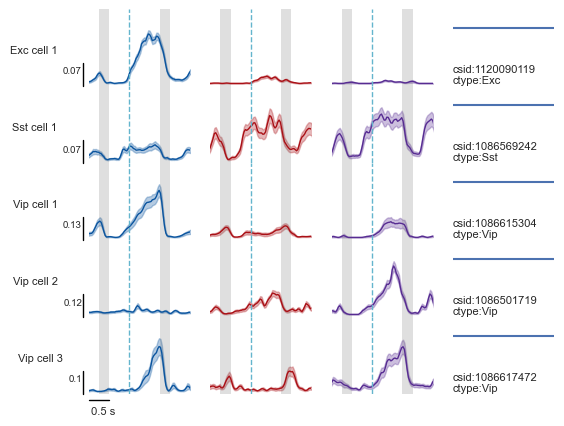

In [64]:
cells_to_plot = [1120090119, # Exc
                 1086569242, # Sst
                 1086615304, # Vip
                 1086501719, # Vip
                 1086617472, # Vip
                ]
event_type = 'omissions'

pse.plot_selected_cell_examples(omission_mdf, cells_to_plot, event_type=event_type,
                                xlim_seconds=[-1, 1.5], linewidth=1, save_dir=save_dir, 
                                folder='selected_example_cells', suffix='_omissions')
    

#### Plot ROI zoom for example cells 

In [65]:
%load_ext autoreload
%autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [66]:
# cells_to_plot = [1120090119, # Exc
#                  1086569242, # Sst
#                  1086615304, # Vip
#                  1086501719, # Vip
#                  1086617472, # Vip
#                 ]

# cell_specimen_id = cells_to_plot[0]

# for cell_specimen_id in cells_to_plot:
#     pse.plot_matched_roi_mask_zoom(cell_specimen_id, platform_cells_table, platform_experiments, save_dir=save_dir)
    

### Matched cell examples

cell_specimen_id: 1086514606
experience_level: Familiar
ophys_experiment_id: 989213060


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 990400778


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 991852002


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

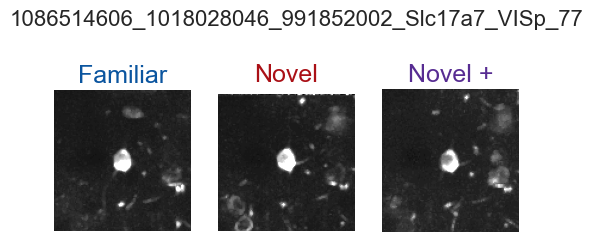

In [67]:
cell_specimen_id = 1086514606 #Excitatory behavior coding cell

pse.plot_matched_rois(cell_specimen_id, platform_cells_table,
                                        folder='matched_rois', save_dir=None)

cell_specimen_id: 1086628708
experience_level: Familiar
ophys_experiment_id: 882551935


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 882968564


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 885146239


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

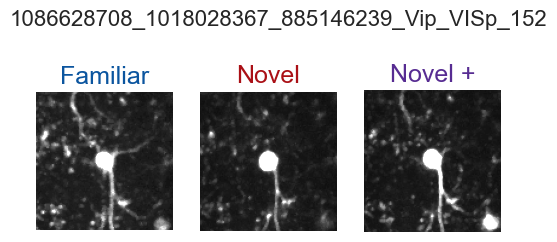

In [68]:
cell_specimen_id = 1086628708  

pse.plot_matched_rois(cell_specimen_id, platform_cells_table,
                                        folder='matched_rois', save_dir=None)

cell_specimen_id: 1086551540
experience_level: Familiar
ophys_experiment_id: 850517352


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 853363749


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 854759900


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

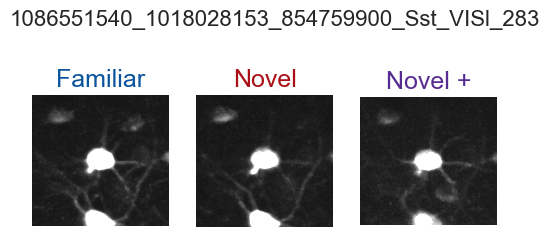

In [69]:
cell_specimen_id = 1086551540  

pse.plot_matched_rois(cell_specimen_id, platform_cells_table,
                                        folder='matched_rois', save_dir=None)

cell_specimen_id: 1086501719
experience_level: Familiar
ophys_experiment_id: 847267622


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel
ophys_experiment_id: 849233396


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 851085100


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

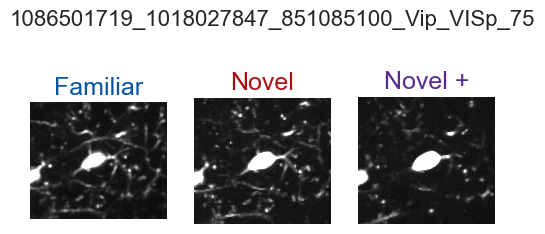

In [70]:
cell_specimen_id = 1086501719

pse.plot_matched_rois(cell_specimen_id, platform_cells_table,
                                        folder='matched_rois', save_dir=None)

#### ROIs and traces across sessions

In [71]:
ophys_container_id = 835006071 
ophys_container_id = 829561794

In [72]:
# cell_type = 'Excitatory'

# # Get high SNR matched cells for container
# matched_cells_snr, dff_metrics = pse.get_high_snr_matched_cells_for_container(ophys_container_id, dataset_dict,
#                                                                                matched_cells_table, platform_experiments, 
#                                                                                )

# # Plot matched max projections for container
# # Note: function signature is (ophys_container_id, platform_experiments, dataset_dict, save_dir, ax)
# # matched_cells_table is NOT a parameter
# pse.plot_matched_max_projections_for_container(ophys_container_id, platform_experiments,
#                                               dataset_dict,
#                                               save_dir=save_dir, ax=None)



In [73]:
# n_reliable_cells_threshold = 5

# reliable_cells = change_mdf[(change_mdf.fraction_significant_p_value_gray_screen>0.15) & 
#             (change_mdf.mean_response > 0.02) &
#             (change_mdf.cell_type==cell_type) & 
#             (change_mdf.ophys_experiment_id.isin(platform_experiments.index.unique()))]

# # reliable_cells = pd.concat([reliable_cells_changes, reliable_cells_omissions])
# matched_reliable_cells = reliable_cells[reliable_cells.cell_specimen_id.isin(matched_cells_table.cell_specimen_id.unique())]


In [74]:
# start_times = np.asarray([512])
# duration_seconds = 18

# matched_cells = matched_reliable_cells[matched_reliable_cells.ophys_container_id==ophys_container_id]
# matched_cells = matched_cells.sort_values(by='fraction_significant_p_value_gray_screen', ascending=False)
# matched_cells = matched_cells.drop_duplicates(subset='cell_specimen_id')
# matched_cells = matched_cells.cell_specimen_id.values
# print(len(matched_cells))

In [75]:
# start_times = np.asarray([513])

# csids = [1086502440, 
#          1086500171,
#          1086502886,
#          1086501666, 
#          1086529369]

# pse.plot_matched_rois_and_traces_for_container(ophys_container_id, dataset_dict,
#                                         matched_cells_table, platform_experiments, fontsize=12,
#                                         start_times=start_times, duration_seconds=18,
#                                         matched_cells=csids, save_dir=save_dir, suffix='')

In [76]:

# suffix = '_reliable_cells_selected'

# pse.plot_matched_traces_across_sessions(ophys_container_id, dataset_dict, 
#                                     matched_cells_table, platform_experiments, 
#                                     change_mdf, omission_mdf, cell_type, skip_behavior=True,
#                                     start_times=start_times, duration_seconds=duration_seconds,
#                                     matched_cells=matched_cells, save_dir=save_dir, suffix=suffix)

## Composite figure (Figure 3 main)
Gutter-aware panel placement via `panel_grid`. Run the data-loading and per-panel plotting cells above first, then the import cell, then the composite cell.

In [77]:
from visual_behavior.visualization.panel_grid import (
    fig_setup, panel, show_label_gutters, show_decoration_zones,
    check_label_overlap, auto_fit_left, snug_left_to_gutter, snug_top_to_gutter, auto_fit_bottom,
)


Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=e

Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


... (23 outputs left out)

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

experience_level: Novel +
ophys_experiment_id: 851085100


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

OVERLAP: axes of panel "C" intrudes into panel "C" (top gutter)
OVERLAP: axes of panel "A" intrudes into panel "A" (top gutter)
OVERLAP: axes of panel "H" intrudes into panel "H" (top gutter)
OVERLAP: axes of panel "E" intrudes into panel "E" (top gutter)
OVERLAP: axes of panel "E" intrudes into panel "E" (top gutter)
OVERLAP: axes of panel "E" intrudes into panel "E" (top gutter)
OVERLAP: axes of panel "F" intrudes into panel "F" (top gutter)
OVERLAP: axes of panel "F" intrudes into panel "F" (top gutter)
OVERLAP: axes of panel "F" intrudes into panel "F" (top gutter)
OVERLAP: axes of panel "G" intrudes into panel "G" (top gutter)
OVERLAP: axes of panel "G" intrudes into panel "G" (top gutter)
OVERLAP: axes of panel "G" intrudes into panel "G" (top gutter)
OVERLAP: axes of panel "J" intrudes into panel "J" (top gutter)
OVERLAP: axes of panel "J" intrudes into panel "J" (top gutter)
OVERLAP: axes of panel "J" intrudes into panel "J" (top gutter)


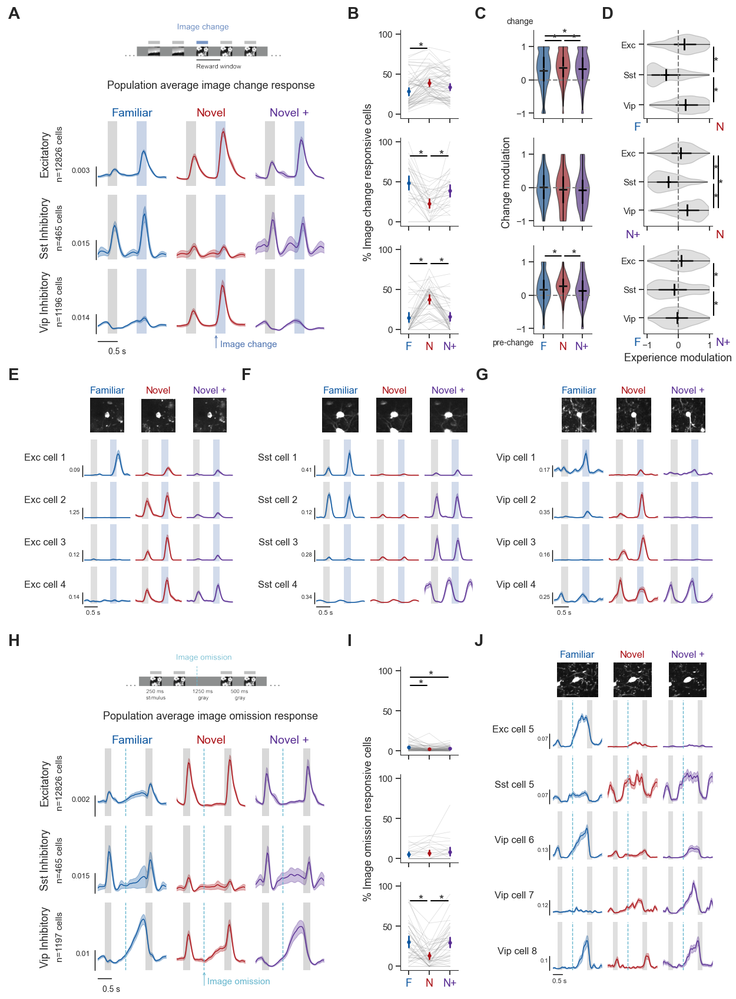

In [78]:
# Composite Figure 3 main - population responses across experience levels
#   Change block:  A pop-avg change (3 cell types x 3 experience) w/ image_change schematic header
#                  B % change-responsive cells | C change modulation | D experience modulation
#                  E/F/G Exc/Sst/Vip example cells (4 cells x 3 exp) each w/ matched-ROI strip
#   Omission block: H pop-avg omission w/ image_omission schematic header
#                   I % omission-responsive cells | J omission example cells (5 cells x 3 exp) + ROI strip
#
# figsize + REGIONS derived from the measured "Figure 3" slide geometry (v6 pptx) and
# tuned against a data-free mock until check_label_overlap was clean. Panels embed LIVE:
#   B/C/D/I  -> ax=list of 3   (functions already support ax=)
#   A/H      -> built inline via plot_population_averages_for_conditions per cell type
#   E/F/G/J  -> plot_selected_cell_examples(ax=flat list, show_metadata_col=False)
#               + plot_matched_rois(ax=3-list) for the ROI strip
#   schematics (A/H) loaded from PNGs via plt.imread
#
# UPSTREAM (run the data-loading cells above first so these stable vars exist):
#   data_type, change_mdf, image_mdf, omission_mdf, each_image_mdf, metrics_table,
#   platform_cells_table, save_dir.
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import visual_behavior.visualization.ophys.summary_figures as sf

# ---------------------------------------------------------------- layout ----
# measured slide geometry (slide fraction) -> figure-fraction REGIONS
SLIDE_W_IN, SLIDE_H_IN = 7.5, 10.0
S = {  # [sx0, sx1, sy0, sy1]  (letter/header top-left -> content bottom-right)
    'A': [0.0050, 0.4200, 0.0926, 0.4150],   # wider (further left + right)
    'B': [0.4400, 0.5950, 0.0926, 0.4150],   # wider; same height as A/I
    'C': [0.6050, 0.7600, 0.0926, 0.4150],   # wider
    'D': [0.7700, 0.9100, 0.0926, 0.4150],   # shifted right
    'E': [0.0050, 0.3000, 0.4450, 0.6700],   # E-G span full width
    'F': [0.3050, 0.6050, 0.4450, 0.6700],
    'G': [0.6100, 0.9100, 0.4450, 0.6700],
    'H': [0.0050, 0.4200, 0.7000, 1.0224],   # wider; same as A
    'I': [0.4400, 0.5950, 0.7000, 1.0224],   # wider; same x-range + height as B
    'J': [0.6050, 0.9100, 0.7000, 1.0224],   # same bottom edge as H/I
}
crop_x0 = min(v[0] for v in S.values()); crop_x1 = max(v[1] for v in S.values())
crop_y0 = min(v[2] for v in S.values()); crop_y1 = max(v[3] for v in S.values())
aspect = ((crop_x1 - crop_x0) * SLIDE_W_IN) / ((crop_y1 - crop_y0) * SLIDE_H_IN)
FIG_W = 12.0; FIG_H = round(FIG_W / aspect, 1)   # ~ (12.0, 15.8)

def _to_region(sx0, sx1, sy0, sy1):
    return [(sx0 - crop_x0) / (crop_x1 - crop_x0), (sx1 - crop_x0) / (crop_x1 - crop_x0),
            (sy0 - crop_y0) / (crop_y1 - crop_y0), (sy1 - crop_y0) / (crop_y1 - crop_y0)]
REGIONS = {k: _to_region(*v) for k, v in S.items()}

GUT = (20, 28)
# per-panel left decoration setback (pt); tuned on the mock, nudge on the real render
DP = {'A': (84, 0), 'B': (58, 0), 'C': (58, 0), 'D': (58, 0),   # A/H bigger -> plots shift right (letter stays)
      'E': (44, 0), 'F': (44, 0), 'G': (44, 0),
      'H': (84, 0), 'I': (58, 0), 'J': (44, 0)}

# ---------------------------------------------------------------- constants ----
# curated example cells (mirrors notebook cells 66/75/81/95; hard-coded here so the
# composite doesn't depend on exploratory vars that later cells overwrite)
Exc_change_cells = [1086579153, 1086559786, 1086523675, 1086514966]
Sst_change_cells = [1086579643, 1120094089, 1086575280, 1086551540]
Vip_change_cells = [1086673402, 1086501825, 1086627590, 1086514444]
omission_cells   = [1120090119, 1086569242, 1086615304, 1086501719, 1086617472]
# representative cell whose matched-ROI strip is shown atop each example panel
ROI_CELL = {'E': 1086514606, 'F': 1086551540, 'G': 1086628708, 'J': 1086501719}
CELL_LABEL_FS = 12      # "Exc cell 1" row labels (plot_selected_cell_examples hardcodes 8)
# J example-cell row labels continue E-G numbering (E-G have 4 cells each)
J_LABELS = ['Exc cell 5', 'Sst cell 5', 'Vip cell 6', 'Vip cell 7', 'Vip cell 8']
ROI_TITLE_DELTA = -6    # shrink the ROI-strip Familiar/Novel/Novel+ titles by 6 pt
# A/H left row labels (rotated 90, centered on each row's y-axis)
CT_FS, N_FS = 13, 11            # cell-type name (bigger) vs n-cells (unchanged) font sizes
CT_OFFSET_PT, N_OFFSET_PT = 64, 46   # left offset (pt) of the cell-type / n-cells labels from the spine
# B/C/D/I axis text + spines
AXIS_LABEL_FS, TICK_FS = 13, 11
SPINE_LW = 0.8
# schematic PNG nudge (figure fraction): left(+) / up(+). positive DY pulls png UP to the gutter
SCHEM_DX, SCHEM_DY = 0.012, 0.010
# standard image-change / image-omission colors (used everywhere else in the paper)
CHANGE_COLOR = sns.color_palette()[0]
OMISSION_COLOR = sns.color_palette()[9]
# informative panel title over A/H, centered on the middle column
TITLE_A = 'Population average image change response'
TITLE_H = 'Population average image omission response'
INFO_TITLE_FS = 13
INFO_TITLE_GAP = 0.010      # figure-fraction gap between schematic and the title below it
# change/omission arrow (A/H): thinner + smaller head to match the originals
ARROW_LW, ARROW_SCALE = 0.8, 7
D_ANNOT_DELTA = -4          # shrink D's F / N / N+ side annotations by 4 pt

SCHEMATIC_DIR = '/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/schematics/Figure 1'
SCHEM = {'A': os.path.join(SCHEMATIC_DIR, 'image_change.png'),
         'H': os.path.join(SCHEMATIC_DIR, 'image_omission.png')}

EXP = ['Familiar', 'Novel', 'Novel +']
exp_colors = utils.get_experience_level_colors()
cell_types = ['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory']

# B input: non-change vs change responsive on preferred image
each_change_pref = each_image_mdf[(each_image_mdf.is_change == True) & (each_image_mdf.pref_stim == True)]

# ---------------------------------------------------------------- figure ----
fig = plt.figure(figsize=(FIG_W, FIG_H)); fig_setup(fig)
# per-panel stats from the embedded component plots are written to a dedicated
# stats folder inside the composite dir (one CSV per panel), mirroring figure 2
stats_dir = os.path.join(save_dir, 'composite', 'figure_3_stats') if save_dir else None

def plot_pop_avg_block(axgrid, mdf, event_type, xlim, arrow_label, arrow_color):
    """A/H: 3 cell-types (rows) x 3 experience (cols) population averages, built inline
    (the library wrapper's ax= path is broken; the inner per-condition fn works)."""
    dist = xlim[1] * 0.07
    for i, cell_type in enumerate(cell_types):
        row = list(np.atleast_1d(axgrid[i]))
        df_ct = mdf[mdf.cell_type == cell_type]
        ppf.plot_population_averages_for_conditions(
            df_ct, data_type, event_type, 'experience_level', 'experience_level',
            horizontal=True, legend=False, xlim_seconds=xlim, interval_sec=1,
            palette=exp_colors, ax=row)
        # scale bar + n-cells label on the first (Familiar) column
        scale = 1.06 if cell_type == 'Excitatory' else 1.15
        _, ymax = row[0].get_ylim(); row[0].set_ylim(0, ymax * scale)
        _, ymax = row[0].get_ylim()
        row[0].set_yticks([0, np.round(ymax * .3, 3)])
        row[0].set_yticklabels(['', np.round(ymax * .3, 3)], va='top', fontsize=9)
        row[0].axvline(x=xlim[0] - dist, ymin=0, ymax=0.3, color='k', linewidth=1, clip_on=False)
        n_cells = df_ct.cell_specimen_id.nunique()
        row[0].set_ylabel('')
        # cell-type label rotated 90 & centered on the row's y-axis; n-cells smaller, just inside it
        row[0].annotate(cell_type, xy=(0, 0.5), xycoords='axes fraction',
                        xytext=(-CT_OFFSET_PT, 0), textcoords='offset points',
                        rotation=90, fontsize=CT_FS, ha='center', va='center', annotation_clip=False)
        row[0].annotate(f'n={n_cells} cells', xy=(0, 0.5), xycoords='axes fraction',
                        xytext=(-N_OFFSET_PT, 0), textcoords='offset points',
                        rotation=90, fontsize=N_FS, ha='center', va='center', annotation_clip=False)
        # exp-level column titles only on the top (Excitatory) row
        for j in range(3):
            row[j].set_title(EXP[j] if i == 0 else '', color=exp_colors[j], fontsize=14)
            row[j].set_xlabel('')
        # col-0: strip spines / ticks / xticklabels but keep the manual scale bar + y-scale label
        sns.despine(ax=row[0], top=True, right=True, left=True, bottom=True)
        row[0].tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
        row[0].set_xticks([])
        # cols 1,2: hide frames entirely (traces stay visible)
        for j in (1, 2):
            row[j].axis('off')
        # change/omission arrow on the BOTTOM (Vip) row, Novel column (clear of the 0.5s bar on col-0)
        if i == len(cell_types) - 1:
            xa = 1
            row[xa].annotate(arrow_label, xy=(0.12, -0.1), xycoords=row[xa].get_xaxis_transform(),
                             ha='left', va='top', color=arrow_color, fontsize=11, clip_on=False)
            row[xa].annotate('', xy=(0.01, -0.25), xycoords=row[xa].get_xaxis_transform(), xytext=(0.01, 0),
                             arrowprops=dict(arrowstyle='<-', color=arrow_color, lw=ARROW_LW,
                                             mutation_scale=ARROW_SCALE), clip_on=False)
        # 0.5 s scale bar on the bottom-row first column (like E-G)
        if i == len(cell_types) - 1:
            ymn, ymx = row[0].get_ylim()
            xfrac = 0.5 / (np.abs(xlim[0]) + xlim[1])   # 0.5 s as a fraction of the x-range (axes coords)
            y_time = (ymx - ymn) * 0.12
            row[0].axhline(y=-y_time, xmin=0, xmax=xfrac, color='k', linewidth=1, clip_on=False)
            row[0].annotate('0.5 s', xy=(xlim[0], -y_time * 1.8), xycoords='data',
                            xytext=(xlim[0] + 0.5, -y_time * 1.8), ha='center', va='top',
                            fontsize=10, clip_on=False, annotation_clip=False)

# ---- A: change population averages (+ image_change schematic header later) ----
axA = np.array(panel(fig, REGIONS['A'][:2], REGIONS['A'][2:], 'A', dim=(3, 3),
                     has_title=True, title_lines=2, title_room_pt=52, hspace=0.14, wspace=0.15,
                     sharey='row', gutter_pt=GUT, decoration_pt=DP['A']), dtype=object)
plot_pop_avg_block(axA, change_mdf, 'changes', [-1, 0.75], 'Image change', CHANGE_COLOR)

# ---- B: % change-responsive cells ----
axB = list(np.atleast_1d(panel(fig, REGIONS['B'][:2], REGIONS['B'][2:], 'B', dim=(3, 1),
                               has_title=True, hspace=0.22, sharex=True, gutter_pt=GUT, decoration_pt=DP['B'])))
ppf.plot_percent_responsive_cells(each_change_pref, responsiveness_threshold=0.2, ylim=(-5, 105),
                                  ylabel='% Image change responsive cells', horizontal=False,
                                  event_type='changes', stats_dir=stats_dir, ax=axB)
for _a in axB:
    _a.set_title('')
for _a in axB[:-1]:                       # shared x -> labels only on bottom subplot
    _a.tick_params(labelbottom=False); _a.set_xlabel('')
axB[1].yaxis.label.set_size(AXIS_LABEL_FS)
for _a in axB:
    _a.tick_params(labelsize=TICK_FS)
    _a.tick_params(axis='x', labelsize=TICK_FS + 2)   # bigger F/N/N+ labels
    for _s in _a.spines.values():
        _s.set_linewidth(SPINE_LW)

# ---- C: change modulation ----
axC = list(np.atleast_1d(panel(fig, REGIONS['C'][:2], REGIONS['C'][2:], 'C', dim=(3, 1),
                               has_title=True, hspace=0.22, sharex=True, gutter_pt=GUT, decoration_pt=DP['C'])))
ppf.plot_modulation_index_distribution(metrics_table, 'change_modulation_index', label='Change modulation',
                                       lims=(-1.15, 1.15), horiz=False, annot=('pre-change', 'change'),
                                       metric_on_y=True, abbreviate_exp=True, fill=True,
                                       event_type='changes', stats_dir=stats_dir, ax=axC)
for _a in axC:
    _a.set_title('')
for _a in axC[:-1]:
    _a.tick_params(labelbottom=False); _a.set_xlabel('')
axC[1].yaxis.label.set_size(AXIS_LABEL_FS)
for _a in axC:
    _a.tick_params(labelsize=TICK_FS)
    _a.tick_params(axis='x', labelsize=TICK_FS + 2)   # bigger F/N/N+ labels
    for _s in _a.spines.values():
        _s.set_linewidth(SPINE_LW)

# ---- D: experience modulation (grouped by comparison, Exc/Sst/Vip within) ----
axD = list(np.atleast_1d(panel(fig, REGIONS['D'][:2], REGIONS['D'][2:], 'D', dim=(3, 1),
                               has_title=True, hspace=0.22, sharex=True, gutter_pt=GUT, decoration_pt=DP['D'])))
ppf.plot_experience_modulation_index_annotated(image_mdf, 'images', 'mean_response', platform_cells_table,
                                               horiz=False, xlims=(-1.1, 1.1), xlabel='Experience modulation',
                                               stats_dir=stats_dir, ax=axD)
# comparison encoded by the F/N side annotations -> drop the verbose block titles
for _a in axD:
    _a.set_title('')
for _a in axD[:-1]:
    _a.tick_params(labelbottom=False); _a.set_xlabel('')
axD[2].xaxis.label.set_size(AXIS_LABEL_FS)
for _a in axD:
    _a.tick_params(labelsize=TICK_FS)
    for _s in _a.spines.values():
        _s.set_linewidth(SPINE_LW)
    for _t in _a.texts:                        # shrink the F / N / N+ side annotations
        if _t.get_text() in ('F', 'N', 'N+'):
            _t.set_fontsize(_t.get_fontsize() + D_ANNOT_DELTA)

# ---- E/F/G: change example cells (traces; ROI strips added after layout is final) ----
example_grids = {}
for lbl, cells in zip(['E', 'F', 'G'], [Exc_change_cells, Sst_change_cells, Vip_change_cells]):
    grid = np.array(panel(fig, REGIONS[lbl][:2], REGIONS[lbl][2:], lbl, dim=(len(cells), 3),
                          has_title=True, title_room_pt=48, hspace=0.15, wspace=0.12,
                          sharey='row', gutter_pt=GUT, decoration_pt=DP[lbl]), dtype=object)
    example_grids[lbl] = grid
    pse.plot_selected_cell_examples(change_mdf, cells, event_type='changes', xlim_seconds=[-1, 0.75],
                                    linewidth=1, save_dir=None, ax=list(grid.ravel()), show_metadata_col=False)
    for _row in grid:
        for _a in np.atleast_1d(_row)[1:]:
            _a.tick_params(labelleft=False)                 # y-scale label only on leftmost column
        np.atleast_1d(_row)[0].yaxis.label.set_size(CELL_LABEL_FS)   # "Exc cell 1" etc, 2pt bigger

# ---- H: omission population averages (+ image_omission schematic header later) ----
axH = np.array(panel(fig, REGIONS['H'][:2], REGIONS['H'][2:], 'H', dim=(3, 3),
                     has_title=True, title_lines=2, title_room_pt=52, hspace=0.14, wspace=0.15,
                     sharey='row', gutter_pt=GUT, decoration_pt=DP['H']), dtype=object)
plot_pop_avg_block(axH, omission_mdf, 'omissions', [-1, 1.5], 'Image omission', OMISSION_COLOR)

# ---- I: % omission-responsive cells ----
axI = list(np.atleast_1d(panel(fig, REGIONS['I'][:2], REGIONS['I'][2:], 'I', dim=(3, 1),
                               has_title=True, hspace=0.22, sharex=True, gutter_pt=GUT, decoration_pt=DP['I'])))
ppf.plot_percent_responsive_cells(omission_mdf, responsiveness_threshold=0.1, ylim=(-5, 105),
                                  ylabel='% Image omission responsive cells', horizontal=False,
                                  event_type='omissions', stats_dir=stats_dir, ax=axI)
for _a in axI:
    _a.set_title('')
for _a in axI[:-1]:
    _a.tick_params(labelbottom=False); _a.set_xlabel('')
axI[1].yaxis.label.set_size(AXIS_LABEL_FS)
for _a in axI:
    _a.tick_params(labelsize=TICK_FS)
    _a.tick_params(axis='x', labelsize=TICK_FS + 2)   # bigger F/N/N+ labels
    for _s in _a.spines.values():
        _s.set_linewidth(SPINE_LW)

# ---- J: omission example cells (traces) ----
gridJ = np.array(panel(fig, REGIONS['J'][:2], REGIONS['J'][2:], 'J', dim=(len(omission_cells), 3),
                       has_title=True, title_room_pt=48, hspace=0.15, wspace=0.12,   # match E-G row spacing
                       sharey='row', gutter_pt=GUT, decoration_pt=DP['J']), dtype=object)
example_grids['J'] = gridJ
pse.plot_selected_cell_examples(omission_mdf, omission_cells, event_type='omissions', xlim_seconds=[-1, 1.5],
                                linewidth=1, save_dir=None, ax=list(gridJ.ravel()), show_metadata_col=False)
for _k, _row in enumerate(gridJ):
    for _a in np.atleast_1d(_row)[1:]:
        _a.tick_params(labelleft=False)
    _a0 = np.atleast_1d(_row)[0]
    _a0.set_ylabel(J_LABELS[_k], rotation=0, ha='right', va='center')   # continue E-G numbering
    _a0.yaxis.label.set_size(CELL_LABEL_FS)

# ---- snap inner (non-leftmost) y-labels to gutters; keep D's x-labels out of G ----
# NOTE: auto_fit_bottom intentionally NOT used - it shifts each subplot's bottom up
# unevenly, distorting the row spacing of multi-row panels. The inter-block gaps are
# sized to absorb the bottom x-labels, so every stacked panel keeps EVEN row spacing.
# include E so its width + label position match F/G (E is leftmost but should not spill into its letter)
snug_left_to_gutter(fig, REGIONS, only=['B', 'C', 'D', 'E', 'F', 'G', 'I', 'J'], gutter_pt=GUT)
snug_top_to_gutter(fig, REGIONS, only=['B', 'C', 'D', 'I'], gutter_pt=GUT)

# equalize the x-axis spine LENGTH across B, C and I (D stays wider); common width = narrowest
_bdi = {'B': axB, 'C': axC, 'I': axI}
_wtarget = min(min(a.get_position().width for a in axs) for axs in _bdi.values())
for axs in _bdi.values():
    for a in axs:
        p = a.get_position()
        a.set_position([p.x0, p.y0, _wtarget, p.height])

# B/C/D share B's per-row y position/height (same top/bottom spines, same row spacing)
for _dst in (axC, axD):
    for _as, _ad in zip(np.atleast_1d(axB), np.atleast_1d(_dst)):
        _ps, _pd = _as.get_position(), _ad.get_position()
        _ad.set_position([_pd.x0, _ps.y0, _pd.width, _ps.height])
# I gets B's exact row heights + spacing, shifted down into I's region (same height as B)
_dy = REGIONS['B'][2] - REGIONS['I'][2]
for _as, _ad in zip(np.atleast_1d(axB), np.atleast_1d(axI)):
    _ps, _pd = _as.get_position(), _ad.get_position()
    _ad.set_position([_pd.x0, _ps.y0 + _dy, _pd.width, _ps.height])
# then re-align I's bottom spine to H's bottom (keeps B's height/spacing, restores row alignment)
_ib = min(a.get_position().y0 for a in np.atleast_1d(axI))
_hb = min(a.get_position().y0 for a in np.array(axH, dtype=object).ravel())
for a in np.atleast_1d(axI):
    p = a.get_position()
    a.set_position([p.x0, p.y0 + (_hb - _ib), p.width, p.height])

# ---- header images (placed AFTER layout is final so they align to the columns) ----
fig.canvas.draw()
gy = GUT[1] / 72.0 / FIG_H

def _cols_xspan(grid):
    """x0,x1 spanning the 3 columns of a drawn grid (from its top row)."""
    top = np.atleast_1d(grid[0])
    pos = [a.get_position() for a in top]
    return min(p.x0 for p in pos), max(p.x1 for p in pos)

def _schematic_header(lbl, grid, title=None, height_frac=0.05, gap_frac=0.004):
    """single wide schematic image centered over the 3 trace columns of A/H, with an
    informative panel title just below it (centered on the middle column)."""
    x0c, x1c = _cols_xspan(grid)
    top_bu = 1 - REGIONS[lbl][2]            # region top (bottom-up)
    schem_y = top_bu - gy - height_frac - gap_frac + SCHEM_DY
    ax = fig.add_axes([x0c - SCHEM_DX, schem_y, x1c - x0c, height_frac])
    try:
        ax.imshow(plt.imread(SCHEM[lbl])); ax.axis('off')
    except Exception as e:
        ax.axis('off'); print('could not load schematic for', lbl, ':', e)
    if title:
        fig.text((x0c + x1c) / 2, schem_y - INFO_TITLE_GAP, title,
                 ha='center', va='top', fontsize=INFO_TITLE_FS)

def _roi_header(lbl, grid, roi_cell, height_frac=0.036, gap_frac=0.004):
    """3-image matched-ROI strip aligned to the 3 trace columns of E/F/G/J."""
    top = np.atleast_1d(grid[0]); pos = [a.get_position() for a in top]
    top_bu = 1 - REGIONS[lbl][2]
    roi_axes = []
    for p in pos:
        a = fig.add_axes([p.x0, top_bu - gy - height_frac - gap_frac, p.width, height_frac])
        roi_axes.append(a)
    try:
        pse.plot_matched_rois(roi_cell, platform_cells_table, save_dir=None, ax=roi_axes)
        for a in roi_axes:                                  # shrink Familiar/Novel/Novel+ ROI titles
            if a.get_title():
                a.title.set_fontsize(a.title.get_fontsize() + ROI_TITLE_DELTA)
    except Exception as e:
        for a in roi_axes:
            a.axis('off')
        print('could not load ROI strip for', lbl, ':', e)

_schematic_header('A', axA, title=TITLE_A)
_schematic_header('H', axH, title=TITLE_H)
for lbl in ['E', 'F', 'G', 'J']:
    _roi_header(lbl, example_grids[lbl], ROI_CELL[lbl])

# ---- audit + save ----
# EXPECTED intentional warnings: A, E, H (leftmost panels) report "left gutter" intrusions --
# their wide horizontal n-cells / cell labels spill into the empty left margin (as in Fig 5).
# Narrow B/C and I/J may report title spill on the real render -> shrink their title fontsize
# or widen the column gap if so. Any OTHER warning is real.
check_label_overlap(fig, REGIONS, gutter_pt=GUT)
for _lax in fig.axes:                       # shrink panel letters (panel() default 24 -> 20)
    if getattr(_lax, '_panel_grid_label_ax', False):
        for _lt in _lax.texts:
            _lt.set_fontsize(20)
utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_3_main_composite', formats=['.png', '.pdf'])


## Composite figure (Figure 3 main) - REVISED LAYOUT (v2)
Addresses reviewer critique: cell type is always a row; one time window/scale for all traces; example cells show Familiar/Novel/Novel+ overlaid. A-D = change, E-H = omission (pop avg | % responsive | modulation index | example cells). Run the data-loading cells first.

In [79]:
# Set cells 

# original, matching first two columns 
# CHANGE_CELLS = {
#     'Excitatory':     [1086523675, 1086512165, 1086579153],
#     'Sst Inhibitory': [1120094089, 1086579643, 1086575280],
#     'Vip Inhibitory': [1086627590, 1086615304, 1086501825],
# }

# OMISSION_CELLS = {
#     'Excitatory':     [1086523675, 1086512165, 1120090119],
#     'Sst Inhibitory': [1120094089, 1086579643, 1086569242],
#     'Vip Inhibitory': [1086627590, 1086615304, 1086501922],
# }

# example cells per cell-type row (final picks; omission cells chosen with reference to the OMI distribution)
CHANGE_CELLS = {
    'Excitatory':     [1086579153, 1086512165, 1086523675],
    'Sst Inhibitory': [1086579643, 1120094089, 1086575280],
    'Vip Inhibitory': [1086615304, 1086627590, 1086501825],
}

# original, matc
OMISSION_CELLS = {
    'Excitatory':     [1086579153, 1086512165, 1120090119],
    'Sst Inhibitory': [1086579643, 1120094089, 1086569242],
    'Vip Inhibitory': [1086615304, 1086627590, 1086501922],
}
# example-cell column titles: cells 1-2 are the same in both panels; the omission panel's 3rd column is a different cell
EX_COL_LABELS = {'changes': ['Cell 1', 'Cell 2', 'Cell 3'],
                 'omissions': ['Cell 1', 'Cell 2', 'Cell 4']}


figsize = (13.0, 11.74); pop-avg column = 1.10 in, example column = 1.10 in; schematic heights = {'A': 0.6414620689655172, 'E': 0.6269304229195088}
Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=e

Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=e

letter overlaps: none


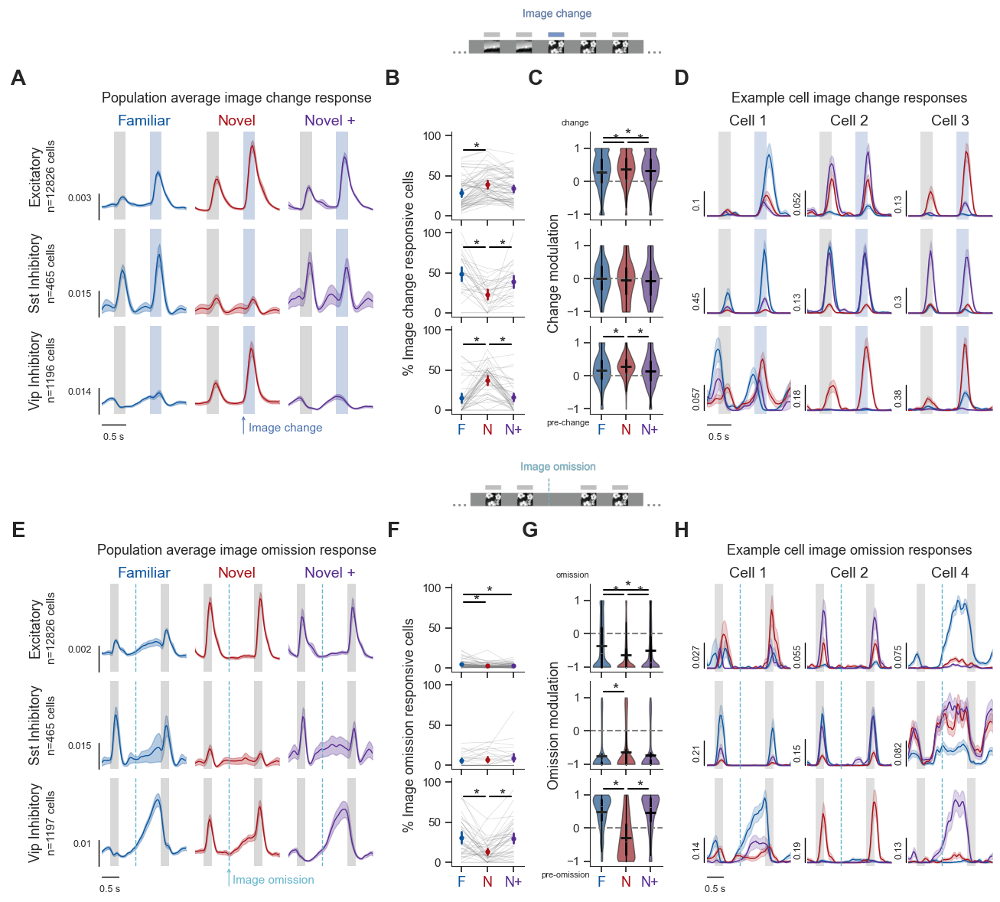

In [80]:
# Composite Figure 3 main (REVISED LAYOUT, v2) - addresses reviewer critique of Fig 3
#   Rule: cell type (Exc / Sst / Vip) is ALWAYS a row; all trace axes in a block share one window + width.
#   Change block:   A pop-avg change (3 exp cols)   | B % responsive | C change modulation   | D example cells
#   Omission block: E pop-avg omission (3 exp cols) | F % responsive | G omission modulation | H example cells
#   Example cells show Familiar/Novel/Novel+ overlaid in one axes per cell.
#   Dropped vs v1: experience-modulation panel (old D). Set SHOW_MOD = False to drop C/G as well.
#
# Geometry is defined in INCHES (constants below) and every axes is placed explicitly, so rows
# align across A/B/C (and D/E/F) and every trace axes has the same seconds-per-inch.
# panel() is still used for letters / axes ownership; letters are then placed from the rendered content.
#
# UPSTREAM (run the data-loading cells above first): data_type, change_mdf, omission_mdf,
#   each_image_mdf, metrics_table, save_dir, and the ppf / utils imports.
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from visual_behavior.visualization.panel_grid import fig_setup, panel

# ---------------------------------------------------------------- knobs ----
FIG_W = 13.0                # extra width goes to the trace panels (A/D/E/H) only
CHANGE_XLIM = [-1, 0.75]    # pre-change + change flashes only (as in the manuscript)
OMISSION_XLIM = [-1, 1.5]   # pre-omission flash, omission, next flash
SHOW_MOD = True             # modulation-index violins (C change / G omission); False -> remove the column


# horizontal layout (inches)
GUT = (20, 28)              # panel-letter gutter (pt)
POP_SETBACK_IN = 1.26       # A/E: letter -> first spine (room for rotated cell-type + n-cells labels)
PCT_SETBACK_IN = 0.97       # B/F: letter -> spine (y tick labels + rotated y label)
EX_SETBACK_IN = 0.52        # D/H: letter -> first spine (room for the rotated y-scale value)
PCT_W_IN = 0.95             # B/F axes width
MOD_SETBACK_IN = 0.80       # C/G: region edge -> spine (y ticks + y label + 'pre-change'/'pre-omission'); smaller = tighter B|C
MOD_W_IN = 0.95             # C/G axes width
COL_GAP_IN = 0.06           # gap between panel blocks (A|B, B|C, C|D)
TRACE_GAP_IN = 0.12         # gap between pop-avg columns (A/E)
EX_GAP_IN = 0.22            # gap between example-cell columns (D/H); holds the rotated y-scale value
POP_W_SCALE = 1.0           # A/E column width relative to a D/H example-cell column (1.0 = same proportions)
RIGHT_MARGIN_IN = 0.10
# vertical layout (inches)
TOP_IN = 0.02
HEADER_IN = 1.20            # letter row + (2-line) title + column titles, above row 1
ROW_IN = 1.15               # height of one cell-type row
ROW_GAP_IN = 0.12
BOTTOM_IN = 0.45            # below last row: F/N/N+ tick labels, 0.5 s scale bar, event arrow
BLOCK_GAP_IN = 0.10
SCHEM_MAX_H_IN = 0.95       # schematic height cap; actual height follows the PNG aspect at the B+C (F+G) width
SCHEM_BOTTOM_IN = 0.22      # schematic bottom, measured DOWN from the block top (keep above the panel-letter row)
SCHEM_TOP_PAD_IN = 0.05     # space above the schematic; the band above each block is sized from these
LETTER_PAD_IN = 0.04        # gap between a panel letter and the top of that panel's content
LETTER_GAP_IN = 0.04        # gap between a panel letter's right edge and the panel's leftmost content (y labels etc)
TITLE_GAP_IN = 0.34         # block-title baseline sits this far above row 1 (clears the column titles)

# text
CT_FS, N_FS = 13, 11
CT_OFFSET_PT, N_OFFSET_PT = 62, 47
AXIS_LABEL_FS, TICK_FS = 13, 11
SPINE_LW = 0.8
EXP_TITLE_FS = 14
INFO_TITLE_FS = 13
SCALE_FS = 9                # ALL scale-bar labels (y values + '0.5 s'), A/E and D/H
MOD_ANNOT_FS = 8            # 'change' / 'pre-change' (C) and 'omission' / 'pre-omission' (G)
ARROW_LW, ARROW_SCALE = 0.8, 7
TRACE_LW = 1

CHANGE_COLOR = sns.color_palette()[0]
OMISSION_COLOR = sns.color_palette()[9]
TITLE_A = 'Population average image change response'
TITLE_E = 'Population average image omission response'
TITLE_EX = {'changes': 'Example cell image change responses',
            'omissions': 'Example cell image omission responses'}
SCHEMATIC_DIR = '/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/schematics/Figure 1'
SCHEM = {'A': os.path.join(SCHEMATIC_DIR, 'image_change_small.png'),
         'E': os.path.join(SCHEMATIC_DIR, 'image_omission_small.png')}
SCHEM_IMG = {}
for _k, _f in SCHEM.items():
    try:
        SCHEM_IMG[_k] = plt.imread(_f)
    except Exception as e:
        SCHEM_IMG[_k] = None
        print('could not load schematic', _f, ':', e)

EXP = utils.get_experience_levels()            # ['Familiar', 'Novel', 'Novel +']
exp_colors = utils.get_experience_level_colors()
cell_types = ['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory']

# ---------------------------------------------------------------- geometry ----
n_ex_cols = max(max(len(v) for v in CHANGE_CELLS.values()), max(len(v) for v in OMISSION_CELLS.values()))
gx_in = GUT[0] / 72.0
# solve trace-column width so the widest block (3 pop-avg cols + n_ex_cols example cols) fills FIG_W
_mod_in = (MOD_SETBACK_IN + MOD_W_IN + COL_GAP_IN) if SHOW_MOD else 0.0
_fixed = (POP_SETBACK_IN + 2 * TRACE_GAP_IN + COL_GAP_IN + PCT_SETBACK_IN + PCT_W_IN + COL_GAP_IN
          + _mod_in + EX_SETBACK_IN + (n_ex_cols - 1) * EX_GAP_IN + RIGHT_MARGIN_IN)
EX_W_IN = (FIG_W - _fixed) / (3 * POP_W_SCALE + n_ex_cols)   # example-cell column width
POP_W_IN = POP_W_SCALE * EX_W_IN                               # A/E column width

# x (inches) of each region's left edge and of each block's first spine
xA = 0.0
xA_sp = xA + POP_SETBACK_IN
xB = xA_sp + 3 * POP_W_IN + 2 * TRACE_GAP_IN + COL_GAP_IN
xB_sp = xB + PCT_SETBACK_IN
xM = xB_sp + PCT_W_IN + COL_GAP_IN            # modulation column (if SHOW_MOD)
xM_sp = xM + MOD_SETBACK_IN
xC = xM + _mod_in                              # example-cell column
xC_sp = xC + EX_SETBACK_IN
# schematic size from the PNG aspect ratio at the B+C (F+G) width, then the band above each block
SCHEM_X0 = xB_sp
SCHEM_X1 = (xM_sp + MOD_W_IN) if SHOW_MOD else (xB_sp + PCT_W_IN)
SCHEM_H = {k: (min(SCHEM_MAX_H_IN, (SCHEM_X1 - SCHEM_X0) * im.shape[0] / im.shape[1]) if im is not None
               else SCHEM_MAX_H_IN) for k, im in SCHEM_IMG.items()}
SCHEM_BAND_IN = max(0.0, max(SCHEM_H.values()) - SCHEM_BOTTOM_IN + SCHEM_TOP_PAD_IN)
BLOCK_H_IN = HEADER_IN + 3 * ROW_IN + 2 * ROW_GAP_IN + BOTTOM_IN
FIG_H = round(TOP_IN + 2 * (SCHEM_BAND_IN + BLOCK_H_IN) + BLOCK_GAP_IN, 2)
print(f'figsize = ({FIG_W}, {FIG_H}); pop-avg column = {POP_W_IN:.2f} in, example column = {EX_W_IN:.2f} in; '
      f'schematic heights = {SCHEM_H}')
# block tops = panel-letter row (inches, top-down); each block's schematic band sits just above it
yblk = [TOP_IN + SCHEM_BAND_IN, TOP_IN + 2 * SCHEM_BAND_IN + BLOCK_H_IN + BLOCK_GAP_IN]

def _fx(x_in): return x_in / FIG_W
def _fy(y_in): return y_in / FIG_H

# panel letters per block: pop-avg, % responsive, [modulation], examples
LETTERS = [('A', 'B', 'C', 'D'), ('E', 'F', 'G', 'H')] if SHOW_MOD else [('A', 'B', None, 'C'), ('D', 'E', None, 'F')]
REGIONS = {}
for (lp, lq, lm, lx), y0 in zip(LETTERS, yblk):
    y1 = y0 + BLOCK_H_IN
    REGIONS[lp] = [_fx(xA), _fx(xB), _fy(y0), _fy(y1)]
    REGIONS[lq] = [_fx(xB), _fx(xM), _fy(y0), _fy(y1)]
    if lm:
        REGIONS[lm] = [_fx(xM), _fx(xC), _fy(y0), _fy(y1)]
    REGIONS[lx] = [_fx(xC), 1.0, _fy(y0), _fy(y1)]

def _row_box(y0_blk, r):
    """bottom-up figure-fraction (y0, h) of cell-type row r in the block starting at y0_blk."""
    top = y0_blk + HEADER_IN + r * (ROW_IN + ROW_GAP_IN)
    return 1 - _fy(top + ROW_IN), _fy(ROW_IN)

def _place(ax, x_in, w_in, y0_blk, r):
    yb, h = _row_box(y0_blk, r)
    ax.set_position([_fx(x_in), yb, _fx(w_in), h])

def _pop_x(j):
    return xA_sp + j * (POP_W_IN + TRACE_GAP_IN)

def _ex_x(j):
    return xC_sp + j * (EX_W_IN + EX_GAP_IN)

# ---------------------------------------------------------------- helpers ----
def plot_pop_avg_block(axgrid, mdf, event_type, xlim, arrow_label, arrow_color):
    """A/E: 3 cell types (rows) x 3 experience levels (cols) population averages (as v1)."""
    dist = (xlim[1] - xlim[0]) * 0.04
    for i, cell_type in enumerate(cell_types):
        row = list(axgrid[i])
        df_ct = mdf[mdf.cell_type == cell_type]
        ppf.plot_population_averages_for_conditions(
            df_ct, data_type, event_type, 'experience_level', 'experience_level',
            horizontal=True, legend=False, xlim_seconds=xlim, interval_sec=1,
            palette=exp_colors, ax=row)
        scale = 1.06 if cell_type == 'Excitatory' else 1.15
        _, ymax = row[0].get_ylim(); row[0].set_ylim(0, ymax * scale)
        _, ymax = row[0].get_ylim()
        row[0].set_yticks([0, np.round(ymax * .3, 3)])
        row[0].set_yticklabels(['', np.round(ymax * .3, 3)], va='top', fontsize=SCALE_FS)
        row[0].axvline(x=xlim[0] - dist, ymin=0, ymax=0.3, color='k', linewidth=1, clip_on=False)
        n_cells = df_ct.cell_specimen_id.nunique()
        row[0].set_ylabel('')
        row[0].annotate(cell_type, xy=(0, 0.5), xycoords='axes fraction',
                        xytext=(-CT_OFFSET_PT, 0), textcoords='offset points',
                        rotation=90, fontsize=CT_FS, ha='center', va='center', annotation_clip=False)
        row[0].annotate(f'n={n_cells} cells', xy=(0, 0.5), xycoords='axes fraction',
                        xytext=(-N_OFFSET_PT, 0), textcoords='offset points',
                        rotation=90, fontsize=N_FS, ha='center', va='center', annotation_clip=False)
        for j in range(3):
            row[j].set_title(EXP[j] if i == 0 else '', color=exp_colors[j], fontsize=EXP_TITLE_FS)
            row[j].set_xlabel('')
        sns.despine(ax=row[0], top=True, right=True, left=True, bottom=True)
        row[0].tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
        row[0].set_xticks([])
        for j in (1, 2):
            row[j].axis('off')
        if i == len(cell_types) - 1:
            _event_arrow(row[1], arrow_label, arrow_color)
            _time_bar(row[0], xlim)

def _event_arrow(ax, label, color):
    ax.annotate(label, xy=(0.12, -0.1), xycoords=ax.get_xaxis_transform(),
                ha='left', va='top', color=color, fontsize=11, clip_on=False)
    ax.annotate('', xy=(0.01, -0.25), xycoords=ax.get_xaxis_transform(), xytext=(0.01, 0),
                arrowprops=dict(arrowstyle='<-', color=color, lw=ARROW_LW, mutation_scale=ARROW_SCALE),
                clip_on=False)

def _time_bar(ax, xlim, seconds=0.5):
    """0.5 s horizontal scale bar under the axes (identical on every trace panel)."""
    ymn, ymx = ax.get_ylim()
    xfrac = seconds / (xlim[1] - xlim[0])
    y_time = (ymx - ymn) * 0.12
    ax.axhline(y=ymn - y_time, xmin=0, xmax=xfrac, color='k', linewidth=1, clip_on=False)
    ax.annotate(f'{seconds} s', xy=(xlim[0] + seconds / 2, ymn - y_time * 1.8), xycoords='data',
                ha='center', va='top', fontsize=SCALE_FS, clip_on=False, annotation_clip=False)

def plot_overlaid_cell(ax, mdf, csid, event_type, xlim):
    """one example cell: Familiar / Novel / Novel+ mean +/- sem overlaid in one axes."""
    change, omitted = event_type == 'changes', event_type == 'omissions'
    cdf = mdf[mdf.cell_specimen_id == csid]
    ts = None
    for e, exp in enumerate(EXP):
        d = cdf[cdf.experience_level == exp]
        if len(d) == 0:
            continue
        utils.plot_mean_trace_from_mean_df(d, ylabel='', xlabel='', xlims=xlim, alpha=0.2,
                                           color=exp_colors[e], interval_sec=1, linewidth=TRACE_LW, ax=ax)
        ts = d.trace_timestamps.values[0]
    if ts is not None:
        utils.plot_flashes_on_trace(ax, ts, change=change, omitted=omitted, alpha=0.25, linewidth=TRACE_LW)
    ax.set_xlim(xlim)
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(min(ymin, 0), ymax * 1.1)
    ymin, ymax = ax.get_ylim()
    bar = float(f'{ymax * .3:.2g}')                      # 2 significant figures (never rounds to 0)
    ax.set_yticks([])
    x_bar = xlim[0] - (xlim[1] - xlim[0]) * 0.03
    ax.axvline(x=x_bar, ymin=(0 - ymin) / (ymax - ymin),
               ymax=(bar - ymin) / (ymax - ymin), color='k', linewidth=1, clip_on=False)
    # scale value OUTSIDE the axes, rotated alongside the bar (fits in the EX_GAP_IN column gap)
    ax.annotate(f'{bar:g}', xy=(x_bar, bar / 2), xycoords='data', xytext=(-2, 0), textcoords='offset points',
                rotation=90, ha='right', va='center', fontsize=SCALE_FS, annotation_clip=False)
    ax.set_xlabel(''); ax.set_ylabel('')
    sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
    ax.tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False, pad=-1)
    ax.set_xticks([])

def plot_example_block(grid, mdf, cells_by_type, event_type, xlim):
    """D/H: rows = cell types, cols = example cells (unused cols hidden)."""
    for i, cell_type in enumerate(cell_types):
        cells = cells_by_type.get(cell_type, [])
        for j in range(grid.shape[1]):
            if j < len(cells):
                plot_overlaid_cell(grid[i, j], mdf, cells[j], event_type, xlim)
            else:
                grid[i, j].axis('off')
    _time_bar(grid[-1, 0], xlim)

def style_pct(axs):
    for _a in axs:
        _a.set_title('')
        _a.tick_params(labelsize=TICK_FS)
        _a.tick_params(axis='x', labelsize=TICK_FS + 2)
        for _s in _a.spines.values():
            _s.set_linewidth(SPINE_LW)
    for _a in axs[:-1]:
        _a.tick_params(labelbottom=False); _a.set_xlabel('')
    axs[1].yaxis.label.set_size(AXIS_LABEL_FS)

# ---------------------------------------------------------------- figure ----
fig = plt.figure(figsize=(FIG_W, FIG_H)); fig_setup(fig)
stats_dir = os.path.join(save_dir, 'composite', 'figure_3_v2_stats') if save_dir else None
if stats_dir:
    os.makedirs(stats_dir, exist_ok=True)

each_change_pref = each_image_mdf[(each_image_mdf.is_change == True) & (each_image_mdf.pref_stim == True)]
BLOCKS = [  # letters, mdf, event_type, xlim, pct df, pct threshold, pct ylabel, examples, arrow, title, modulation
    (LETTERS[0], change_mdf, 'changes', CHANGE_XLIM, each_change_pref, 0.2,
     '% Image change responsive cells', CHANGE_CELLS, ('Image change', CHANGE_COLOR), TITLE_A,
     ('change_modulation_index', 'Change modulation', ('pre-change', 'change'))),
    (LETTERS[1], omission_mdf, 'omissions', OMISSION_XLIM, omission_mdf, 0.1,
     '% Image omission responsive cells', OMISSION_CELLS, ('Image omission', OMISSION_COLOR), TITLE_E,
     ('omission_modulation_index', 'Omission modulation', ('pre-omission', 'omission'))),
]
pop_grids, ex_grids = {}, {}
header_texts = {}   # block titles, so the A/E and D/H letters sit above them
for b, ((lp, lq, lm, lx), mdf, ev, xlim, pct_df, thr, pct_ylabel, cells, arrow, info_title, mod) in enumerate(BLOCKS):
    y0 = yblk[b]
    # --- population averages ---
    gp = np.array(panel(fig, REGIONS[lp][:2], REGIONS[lp][2:], lp, dim=(3, 3), sharey='row',
                        gutter_pt=GUT), dtype=object)
    for i in range(3):
        for j in range(3):
            _place(gp[i, j], _pop_x(j), POP_W_IN, y0, i)
    plot_pop_avg_block(gp, mdf, ev, xlim, *arrow)
    pop_grids[lp] = gp
    # --- % responsive ---
    aq = list(np.atleast_1d(panel(fig, REGIONS[lq][:2], REGIONS[lq][2:], lq, dim=(3, 1), sharex=True,
                                  gutter_pt=GUT)))
    for i in range(3):
        _place(aq[i], xB_sp, PCT_W_IN, y0, i)
    ppf.plot_percent_responsive_cells(pct_df, responsiveness_threshold=thr, ylim=(-5, 105),
                                      ylabel=pct_ylabel, horizontal=False, event_type=ev,
                                      stats_dir=stats_dir, ax=aq)
    style_pct(aq)
    # --- modulation index violins ---
    if lm:
        am = list(np.atleast_1d(panel(fig, REGIONS[lm][:2], REGIONS[lm][2:], lm, dim=(3, 1), sharex=True,
                                      gutter_pt=GUT)))
        for i in range(3):
            _place(am[i], xM_sp, MOD_W_IN, y0, i)
        metric, mod_label, annot = mod
        ppf.plot_modulation_index_distribution(metrics_table, metric, label=mod_label, lims=(-1.15, 1.15),
                                               horiz=False, annot=annot, metric_on_y=True, abbreviate_exp=True,
                                               fill=True, event_type=ev, stats_dir=stats_dir, ax=am)
        style_pct(am)
        for _a in am:                                    # smaller 'change'/'pre-change' side labels
            for _t in _a.texts:
                if _t.get_text() in annot:
                    _t.set_fontsize(MOD_ANNOT_FS)
    # --- example cells (overlaid experience levels) ---
    gx = np.array(panel(fig, REGIONS[lx][:2], REGIONS[lx][2:], lx, dim=(3, n_ex_cols),
                        gutter_pt=GUT), dtype=object).reshape(3, n_ex_cols)
    for i in range(3):
        for j in range(n_ex_cols):
            _place(gx[i, j], _ex_x(j), EX_W_IN, y0, i)
    plot_example_block(gx, mdf, cells, ev, xlim)
    ex_grids[lx] = gx

    # --- headers (all positions are final now) ---
    gy_in = GUT[1] / 72.0
    title_y = y0 + HEADER_IN - TITLE_GAP_IN               # shared bottom edge for the A/E and D/H titles
    # change / omission schematic centered over B+C (F+G), in the band above the panel letters
    sbot = y0 + SCHEM_BOTTOM_IN
    sax = fig.add_axes([_fx(SCHEM_X0), 1 - _fy(sbot), _fx(SCHEM_X1 - SCHEM_X0), _fy(SCHEM_H[lp])])
    if SCHEM_IMG[lp] is not None:
        sax.imshow(SCHEM_IMG[lp])
        sax.set_anchor('S')                                # sit on the bottom edge if aspect leaves slack
    sax.axis('off')
    sax._panel_grid_label_ax = True   # header image spans B|C on purpose -> exclude from the gutter audit
    x0c, x1c = _pop_x(0), _pop_x(2) + POP_W_IN
    header_texts[lp] = fig.text(_fx((x0c + x1c) / 2), 1 - _fy(title_y), info_title,
                                ha='center', va='bottom', fontsize=INFO_TITLE_FS)
    ex_x0, ex_x1 = _ex_x(0), _ex_x(n_ex_cols - 1) + EX_W_IN
    header_texts[lx] = fig.text(_fx((ex_x0 + ex_x1) / 2), 1 - _fy(title_y), TITLE_EX[ev], ha='center',
                                va='bottom', fontsize=INFO_TITLE_FS, linespacing=1.1)
    # "Cell 1/2/3" (or 1/2/4) column titles on the top row, level with A/E's Familiar/Novel/Novel+ titles
    for j in range(n_ex_cols):
        gx[0, j].set_title(EX_COL_LABELS[ev][j], fontsize=EXP_TITLE_FS)

# ---- letters, audit + save ----
for _lax in fig.axes:                       # panel letters 24 -> 20 (as v1)
    if getattr(_lax, '_panel_grid_label_ax', False):
        for _lt in _lax.texts:
            _lt.set_fontsize(20)
# panel letters: fully LEFT of each panel's leftmost content (y labels included), just above A's (E's) top
# content, aligned across the row
# (axes + titles + side annotations, plus the block title for A/E and D/H)
fig.canvas.draw()
_r = fig.canvas.get_renderer()
_inv = fig.transFigure.inverted()
_letter_pos = {}
for _lax in fig.axes:
    if not getattr(_lax, '_panel_grid_label_ax', False) or not _lax.texts:
        continue
    _lbl = _lax.texts[0].get_text()
    if _lbl not in REGIONS:
        continue
    _owned = [a for a in fig.axes if getattr(a, '_panel_grid_owner', None) == _lbl and a.get_visible()
              and (a.has_data() or a.texts or a.get_title())]
    _bbs = [a.get_tightbbox(_r).transformed(_inv) for a in _owned]
    _tops = [bb.y1 for bb in _bbs]
    if _lbl in header_texts:
        _tops.append(header_texts[_lbl].get_window_extent(_r).transformed(_inv).y1)
    if not _tops:
        continue
    _p = _lax.get_position()
    _left = min(bb.x0 for bb in _bbs) if _bbs else _p.x0       # panel's leftmost content (y label etc)
    _t = _lax.texts[0]                                            # letter drawn at x=0.15 (axes frac), ha='left'
    _wl = _t.get_window_extent(_r).transformed(_inv).width
    _x = max(-0.15 * _p.width, _left - _fx(LETTER_GAP_IN) - _wl - 0.15 * _p.width)
    _letter_pos[_lbl] = (_lax, _x, max(_tops) + _fy(LETTER_PAD_IN) - _p.height * 0.2)
# all letters in a block share the height of that block's first letter (A or E)
for _row in LETTERS:
    _ref = _letter_pos.get(_row[0])
    for _lbl in _row:
        if _lbl in _letter_pos and _ref is not None:
            _lax, _x, _ = _letter_pos[_lbl]
            _p = _lax.get_position()
            _lax.set_position([_x, _ref[2], _p.width, _p.height])
# audit: report any panel letter that overlaps drawn content (axes incl. labels, header texts)
fig.canvas.draw()
_items = [(getattr(a, '_panel_grid_owner', None) or 'header', a.get_tightbbox(_r).transformed(_inv))
          for a in fig.axes if not getattr(a, '_panel_grid_label_ax', False) and a.get_visible()
          and (a.has_data() or a.texts or a.get_title() or a.images)]
_items += [('title', t.get_window_extent(_r).transformed(_inv)) for t in fig.texts]
_bad = []
for _lbl, (_lax, _, _) in _letter_pos.items():
    _lb = _lax.texts[0].get_window_extent(_r).transformed(_inv)
    _bad += [(_lbl, o) for o, bb in _items if _lb.overlaps(bb)]
print('letter overlaps:', _bad if _bad else 'none')
utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_3_main_composite_v2', formats=['.png', '.pdf'])


## Composite figure (Figure 3 main) - SIDE-BY-SIDE LAYOUT (v4)
Alternative to v2/v3: row 1 = A | B (change) and E | F (omission); row 2 = D | C and H | G. B/C/F/G rows align with the trace rows. Saves as figure_3_main_composite_v4.

figsize = (13.54, 10.78); trace axes = 1.15 x 1.15 in; B/C width = 1.10 in
Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=e

Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=experience_levels,
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:3723: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  ax[i] = sns.pointplot(data=ct_data, y=y, x=x, order=e

letter overlaps: none


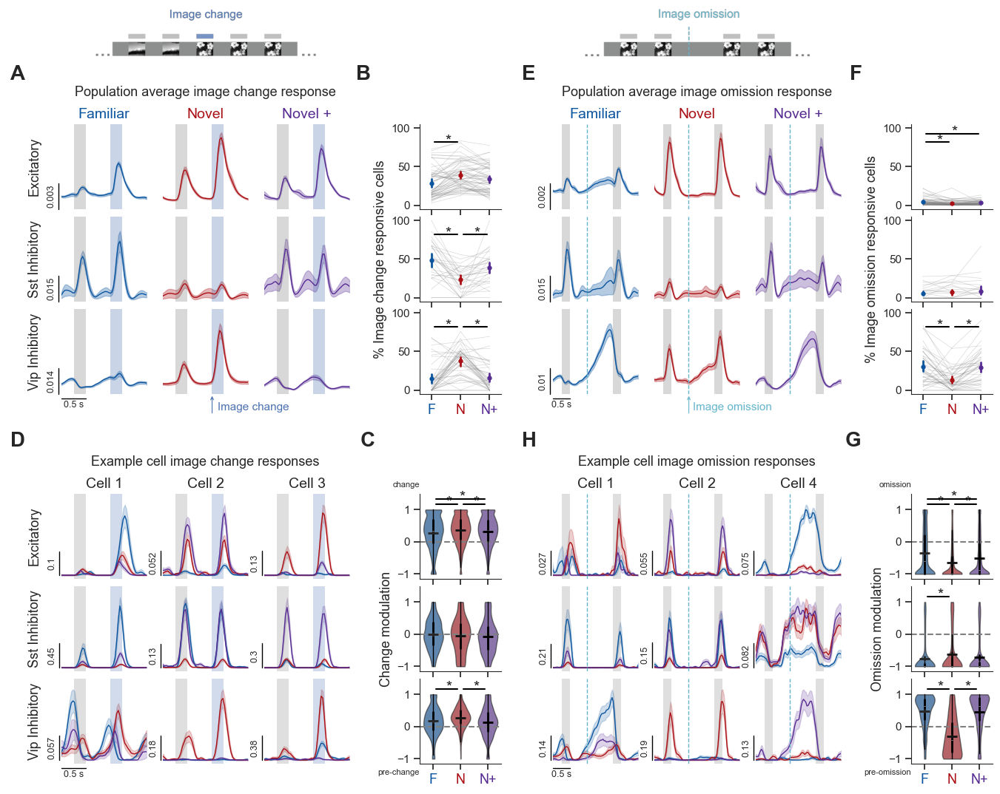

In [ ]:
# # Composite Figure 3 main (SIDE-BY-SIDE LAYOUT, v4) - alternative to v2 / v3 (those cells are unchanged)
# #   Two rows; change on the left half, omission on the right half:
# #     row 1:  A (population averages) | B (% responsive)       ||  E | F
# #     row 2:  D (example cells)       | C (modulation index)   ||  H | G
# #   B/C/F/G rows share the y positions + heights of the trace rows beside them (cell type = row).
# #   Cell-type labels only on the far left (A and D); n cells go in the legend.
# #   Change / omission schematic centered above each half.
# #
# # Geometry is in INCHES (knobs below); every axes is placed explicitly. panel() is used for letters /
# # axes ownership; letters are then placed from the rendered content (left of it, aligned per figure row).
# #
# # UPSTREAM (run the data-loading cells above first): data_type, change_mdf, omission_mdf,
# #   each_image_mdf, metrics_table, save_dir, and the ppf / utils imports.
# import os
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# from visual_behavior.visualization.panel_grid import fig_setup, panel

# # ---------------------------------------------------------------- knobs ----
# TRACE_W_IN = 1.15           # width of every A/E/D/H trace axes; FIG_W is derived from it
# CHANGE_XLIM = [-1, 0.75]
# OMISSION_XLIM = [-1, 1.5]

# GUT = (20, 28)              # panel() letter gutter (pt) - only used for the initial letter axes
# # horizontal (inches)
# COLUMN_GAP_IN = 0.20        # gap between the change and omission columns
# RIGHT_MARGIN_IN = 0.10
# LEFT_SETBACK_IN = [0.78, 0.42]  # column left -> first trace spine: change col (letter + cell-type label + scale)
#                                 #   / omission col (letter + scale value only; no cell-type labels)
# TRACE_GAP_IN = 0.22         # gap between trace columns (same in A/E and D/H so their columns line up)
# SIDE_SETBACK_IN = 0.95      # last trace column's right edge -> B/C (F/G) spine (letter + y ticks + y label)
# BC_W_IN = 1.10              # B/C/F/G axes width
# BC_RIGHT_PAD_IN = 0.08      # space right of B/C (F/G)
# # vertical (inches)
# TOP_IN = 0.02
# TRACE_ROW_IN = 1.15         # row height of every panel (B/C/F/G rows align with the trace rows)
# ROW_GAP_IN = 0.10
# TRACE_HEADER_IN = 0.80      # A/E and D/H: block title + column titles above row 1
# BOTTOM_IN = 0.45            # below last row: tick labels / scale bar / event arrow
# SECTION_GAP_IN = 0.10
# TITLE_GAP_IN = 0.34         # block-title baseline sits this far above row 1
# SCHEM_MAX_H_IN = 0.70       # schematic height cap (actual height follows the PNG aspect)
# SCHEM_W_FRAC = 0.80         # schematic width as a fraction of the A/E trace span
# SCHEM_PAD_IN = 0.08         # space below/above the schematic
# LETTER_PAD_IN = 0.04
# LETTER_GAP_IN = 0.04

# # text
# CT_FS = 13                  # = AXIS_LABEL_FS (matches the other y labels)
# CT_OFFSET_PT = 26           # cell-type label offset left of the first spine (same for A/E and D/H)
# AXIS_LABEL_FS, TICK_FS = 13, 11
# SPINE_LW = 0.8
# EXP_TITLE_FS = 14
# INFO_TITLE_FS = 13
# SCALE_FS = 9
# TIME_BAR_FRAC = 0.05        # 0.5 s bar: distance below the x-axis, as a fraction of the y range
# MOD_ANNOT_FS = 8
# ARROW_LW, ARROW_SCALE = 0.8, 7
# TRACE_LW = 1

# CHANGE_COLOR = sns.color_palette()[0]
# OMISSION_COLOR = sns.color_palette()[9]
# TITLE_POP = {'changes': 'Population average image change response',
#              'omissions': 'Population average image omission response'}
# TITLE_EX = {'changes': 'Example cell image change responses',
#             'omissions': 'Example cell image omission responses'}
# SCHEMATIC_DIR = '/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/schematics/Figure 1'
# SCHEM = {'changes': os.path.join(SCHEMATIC_DIR, 'image_change_small.png'),
#          'omissions': os.path.join(SCHEMATIC_DIR, 'image_omission_small.png')}
# SCHEM_IMG = {}
# for _k, _f in SCHEM.items():
#     try:
#         SCHEM_IMG[_k] = plt.imread(_f)
#     except Exception as e:
#         SCHEM_IMG[_k] = None
#         print('could not load schematic', _f, ':', e)

# EXP = utils.get_experience_levels()
# exp_colors = utils.get_experience_level_colors()
# cell_types = ['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory']

# # ---------------------------------------------------------------- geometry ----
# n_ex_cols = 3
# SPAN_IN = n_ex_cols * TRACE_W_IN + (n_ex_cols - 1) * TRACE_GAP_IN            # A/E/D/H trace span (same in both columns)
# COL_W = [LEFT_SETBACK_IN[c] + SPAN_IN + SIDE_SETBACK_IN + BC_W_IN + BC_RIGHT_PAD_IN for c in range(2)]   # half widths
# COL_X = [0.0, COL_W[0] + COLUMN_GAP_IN]                                       # column left edges
# FIG_W = round(COL_X[1] + COL_W[1] + RIGHT_MARGIN_IN, 2)

# SCHEM_H = {k: (min(SCHEM_MAX_H_IN, SCHEM_W_FRAC * SPAN_IN * im.shape[0] / im.shape[1]) if im is not None
#                else SCHEM_MAX_H_IN) for k, im in SCHEM_IMG.items()}
# SCHEM_BAND_IN = max(SCHEM_H.values()) + 2 * SCHEM_PAD_IN

# ROW_H = {'pop': TRACE_ROW_IN, 'ex': TRACE_ROW_IN}
# ROWS_H_IN = {k: 3 * v + 2 * ROW_GAP_IN for k, v in ROW_H.items()}
# SEC_H = {k: TRACE_HEADER_IN + ROWS_H_IN[k] + BOTTOM_IN for k in ROW_H}
# SEC_Y = {'pop': TOP_IN + SCHEM_BAND_IN}
# SEC_Y['ex'] = SEC_Y['pop'] + SEC_H['pop'] + SECTION_GAP_IN
# SEC_HDR = {'pop': TRACE_HEADER_IN, 'ex': TRACE_HEADER_IN}
# FIG_H = round(SEC_Y['ex'] + SEC_H['ex'], 2)
# print(f'figsize = ({FIG_W}, {FIG_H}); trace axes = {TRACE_W_IN:.2f} x {TRACE_ROW_IN:.2f} in; B/C width = {BC_W_IN:.2f} in')

# def _fx(x_in): return x_in / FIG_W
# def _fy(y_in): return y_in / FIG_H

# def _place(ax, x_in, w_in, sec, r):
#     top = SEC_Y[sec] + SEC_HDR[sec] + r * (ROW_H[sec] + ROW_GAP_IN)
#     ax.set_position([_fx(x_in), 1 - _fy(top + ROW_H[sec]), _fx(w_in), _fy(ROW_H[sec])])

# def _trace_x(c, j):
#     return COL_X[c] + LEFT_SETBACK_IN[c] + j * (TRACE_W_IN + TRACE_GAP_IN)

# LETTERS = {'changes': ('A', 'B', 'C', 'D'), 'omissions': ('E', 'F', 'G', 'H')}
# LETTER_ROWS = [('A', 'B', 'E', 'F'), ('D', 'C', 'H', 'G')]
# REGIONS = {}
# for c, ev in enumerate(['changes', 'omissions']):
#     la, lb, lc, ld = LETTERS[ev]
#     x0, x1 = COL_X[c], COL_X[c] + COL_W[c]
#     xm = _trace_x(c, n_ex_cols - 1) + TRACE_W_IN                   # traces | small panels split
#     for l, sec, a, b in [(la, 'pop', x0, xm), (lb, 'pop', xm, x1), (lc, 'ex', xm, x1), (ld, 'ex', x0, xm)]:
#         REGIONS[l] = [_fx(a), _fx(b), _fy(SEC_Y[sec]), _fy(SEC_Y[sec] + SEC_H[sec])]

# # ---------------------------------------------------------------- helpers ----
# def _cell_type_label(ax, cell_type):
#     ax.annotate(cell_type, xy=(0, 0.5), xycoords='axes fraction', xytext=(-CT_OFFSET_PT, 0),
#                 textcoords='offset points', rotation=90, fontsize=CT_FS, ha='center', va='center',
#                 annotation_clip=False)

# def _event_arrow(ax, label, color):
#     ax.annotate(label, xy=(0.12, -0.1), xycoords=ax.get_xaxis_transform(),
#                 ha='left', va='top', color=color, fontsize=11, clip_on=False)
#     ax.annotate('', xy=(0.01, -0.25), xycoords=ax.get_xaxis_transform(), xytext=(0.01, 0),
#                 arrowprops=dict(arrowstyle='<-', color=color, lw=ARROW_LW, mutation_scale=ARROW_SCALE),
#                 clip_on=False)

# def _time_bar(ax, xlim, seconds=0.5):
#     ymn, ymx = ax.get_ylim()
#     xfrac = seconds / (xlim[1] - xlim[0])
#     y_bar = ymn - (ymx - ymn) * TIME_BAR_FRAC
#     ax.axhline(y=y_bar, xmin=0, xmax=xfrac, color='k', linewidth=1, clip_on=False)
#     ax.annotate(f'{seconds} s', xy=(xlim[0] + seconds / 2, y_bar), xycoords='data', xytext=(0, -2),
#                 textcoords='offset points', ha='center', va='top', fontsize=SCALE_FS,
#                 clip_on=False, annotation_clip=False)

# def plot_pop_avg_block(axgrid, mdf, event_type, xlim, arrow_label, arrow_color, labels=True):
#     dist = (xlim[1] - xlim[0]) * 0.04
#     for i, cell_type in enumerate(cell_types):
#         row = list(axgrid[i])
#         df_ct = mdf[mdf.cell_type == cell_type]
#         ppf.plot_population_averages_for_conditions(
#             df_ct, data_type, event_type, 'experience_level', 'experience_level',
#             horizontal=True, legend=False, xlim_seconds=xlim, interval_sec=1,
#             palette=exp_colors, ax=row)
#         scale = 1.06 if cell_type == 'Excitatory' else 1.15
#         _, ymax = row[0].get_ylim(); row[0].set_ylim(0, ymax * scale)
#         _, ymax = row[0].get_ylim()
#         row[0].set_yticks([])
#         row[0].axvline(x=xlim[0] - dist, ymin=0, ymax=0.3, color='k', linewidth=1, clip_on=False)
#         row[0].annotate(f'{np.round(ymax * .3, 3):g}', xy=(xlim[0] - dist, ymax * .15), xycoords='data',
#                         xytext=(-2, 0), textcoords='offset points', rotation=90, ha='right', va='center',
#                         fontsize=SCALE_FS, annotation_clip=False)   # rotated, like D/H
#         row[0].set_ylabel('')
#         if labels:
#             _cell_type_label(row[0], cell_type)
#         for j in range(3):
#             row[j].set_title(EXP[j] if i == 0 else '', color=exp_colors[j], fontsize=EXP_TITLE_FS)
#             row[j].set_xlabel('')
#         sns.despine(ax=row[0], top=True, right=True, left=True, bottom=True)
#         row[0].tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
#         row[0].set_xticks([])
#         for j in (1, 2):
#             row[j].axis('off')
#         if i == len(cell_types) - 1:
#             _event_arrow(row[1], arrow_label, arrow_color)
#             _time_bar(row[0], xlim)

# def plot_overlaid_cell(ax, mdf, csid, event_type, xlim):
#     change, omitted = event_type == 'changes', event_type == 'omissions'
#     cdf = mdf[mdf.cell_specimen_id == csid]
#     ts = None
#     for e, exp in enumerate(EXP):
#         d = cdf[cdf.experience_level == exp]
#         if len(d) == 0:
#             continue
#         utils.plot_mean_trace_from_mean_df(d, ylabel='', xlabel='', xlims=xlim, alpha=0.2,
#                                            color=exp_colors[e], interval_sec=1, linewidth=TRACE_LW, ax=ax)
#         ts = d.trace_timestamps.values[0]
#     if ts is not None:
#         utils.plot_flashes_on_trace(ax, ts, change=change, omitted=omitted, alpha=0.25, linewidth=TRACE_LW)
#     ax.set_xlim(xlim)
#     ymin, ymax = ax.get_ylim()
#     ax.set_ylim(min(ymin, 0), ymax * 1.1)
#     ymin, ymax = ax.get_ylim()
#     bar = float(f'{ymax * .3:.2g}')
#     ax.set_yticks([])
#     x_bar = xlim[0] - (xlim[1] - xlim[0]) * 0.03
#     ax.axvline(x=x_bar, ymin=(0 - ymin) / (ymax - ymin), ymax=(bar - ymin) / (ymax - ymin),
#                color='k', linewidth=1, clip_on=False)
#     ax.annotate(f'{bar:g}', xy=(x_bar, bar / 2), xycoords='data', xytext=(-2, 0), textcoords='offset points',
#                 rotation=90, ha='right', va='center', fontsize=SCALE_FS, annotation_clip=False)
#     ax.set_xlabel(''); ax.set_ylabel('')
#     sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
#     ax.tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False, pad=-1)
#     ax.set_xticks([])

# def plot_example_block(grid, mdf, cells_by_type, event_type, xlim, labels=True):
#     for i, cell_type in enumerate(cell_types):
#         cells = cells_by_type.get(cell_type, [])
#         for j in range(grid.shape[1]):
#             if j < len(cells):
#                 plot_overlaid_cell(grid[i, j], mdf, cells[j], event_type, xlim)
#             else:
#                 grid[i, j].axis('off')
#         if labels:
#             _cell_type_label(grid[i, 0], cell_type)     # label even if this row has no cell in column 0
#     _time_bar(grid[-1, 0], xlim)

# def style_small(axs):
#     for _a in axs:
#         _a.set_title('')
#         _a.tick_params(labelsize=TICK_FS)
#         _a.tick_params(axis='x', labelsize=TICK_FS + 2)
#         for _s in _a.spines.values():
#             _s.set_linewidth(SPINE_LW)
#     for _a in axs[:-1]:
#         _a.tick_params(labelbottom=False); _a.set_xlabel('')
#     axs[1].yaxis.label.set_size(AXIS_LABEL_FS)

# # ---------------------------------------------------------------- figure ----
# fig = plt.figure(figsize=(FIG_W, FIG_H)); fig_setup(fig)
# stats_dir = os.path.join(save_dir, 'composite', 'figure_3_v4_stats') if save_dir else None
# if stats_dir:
#     os.makedirs(stats_dir, exist_ok=True)

# each_change_pref = each_image_mdf[(each_image_mdf.is_change == True) & (each_image_mdf.pref_stim == True)]
# COLS = [  # event, mdf, xlim, pct df, threshold, pct ylabel, examples, arrow, modulation
#     ('changes', change_mdf, CHANGE_XLIM, each_change_pref, 0.2, '% Image change responsive cells',
#      CHANGE_CELLS, ('Image change', CHANGE_COLOR), ('change_modulation_index', 'Change modulation', ('pre-change', 'change'))),
#     ('omissions', omission_mdf, OMISSION_XLIM, omission_mdf, 0.1, '% Image omission responsive cells',
#      OMISSION_CELLS, ('Image omission', OMISSION_COLOR), ('omission_modulation_index', 'Omission modulation', ('pre-omission', 'omission'))),
# ]
# header_texts = {}
# for c, (ev, mdf, xlim, pct_df, thr, pct_ylabel, cells, arrow, mod) in enumerate(COLS):
#     la, lb, lc, ld = LETTERS[ev]
#     # --- A/E population averages ---
#     gp = np.array(panel(fig, REGIONS[la][:2], REGIONS[la][2:], la, dim=(3, 3), sharey='row', gutter_pt=GUT), dtype=object)
#     for i in range(3):
#         for j in range(3):
#             _place(gp[i, j], _trace_x(c, j), TRACE_W_IN, 'pop', i)
#     plot_pop_avg_block(gp, mdf, ev, xlim, *arrow, labels=(c == 0))   # cell-type labels on the change column only
#     # --- B/F % responsive ---
#     ab = list(np.atleast_1d(panel(fig, REGIONS[lb][:2], REGIONS[lb][2:], lb, dim=(3, 1), sharex=True, gutter_pt=GUT)))
#     xb = _trace_x(c, n_ex_cols - 1) + TRACE_W_IN + SIDE_SETBACK_IN      # right of A/E, same rows
#     for i in range(3):
#         _place(ab[i], xb, BC_W_IN, 'pop', i)
#     ppf.plot_percent_responsive_cells(pct_df, responsiveness_threshold=thr, ylim=(-5, 105), ylabel=pct_ylabel,
#                                       horizontal=False, event_type=ev, stats_dir=stats_dir, ax=ab)
#     style_small(ab)
#     # --- C/G modulation index ---
#     ac = list(np.atleast_1d(panel(fig, REGIONS[lc][:2], REGIONS[lc][2:], lc, dim=(3, 1), sharex=True, gutter_pt=GUT)))
#     for i in range(3):                                                  # right of D/H, same x as B/F
#         _place(ac[i], xb, BC_W_IN, 'ex', i)
#     metric, mod_label, annot = mod
#     ppf.plot_modulation_index_distribution(metrics_table, metric, label=mod_label, lims=(-1.15, 1.15),
#                                            horiz=False, annot=annot, metric_on_y=True, abbreviate_exp=True,
#                                            fill=True, event_type=ev, stats_dir=stats_dir, ax=ac)
#     style_small(ac)
#     for _a in ac:
#         for _t in _a.texts:
#             if _t.get_text() in annot:
#                 _t.set_fontsize(MOD_ANNOT_FS)
#     # --- D/H example cells ---
#     gx = np.array(panel(fig, REGIONS[ld][:2], REGIONS[ld][2:], ld, dim=(3, n_ex_cols), gutter_pt=GUT),
#                   dtype=object).reshape(3, n_ex_cols)
#     for i in range(3):
#         for j in range(n_ex_cols):
#             _place(gx[i, j], _trace_x(c, j), TRACE_W_IN, 'ex', i)
#     plot_example_block(gx, mdf, cells, ev, xlim, labels=(c == 0))
#     for j in range(n_ex_cols):
#         gx[0, j].set_title(EX_COL_LABELS[ev][j], fontsize=EXP_TITLE_FS)

#     # --- headers: block titles + schematic above the column ---
#     xs0, xs1 = _trace_x(c, 0), _trace_x(c, n_ex_cols - 1) + TRACE_W_IN
#     for l, sec, title in [(la, 'pop', TITLE_POP[ev]), (ld, 'ex', TITLE_EX[ev])]:
#         ty = SEC_Y[sec] + SEC_HDR[sec] - TITLE_GAP_IN
#         header_texts[l] = fig.text(_fx((xs0 + xs1) / 2), 1 - _fy(ty), title, ha='center', va='bottom',
#                                    fontsize=INFO_TITLE_FS)
#     sw = SCHEM_W_FRAC * SPAN_IN
#     sax = fig.add_axes([_fx((xs0 + xs1 - sw) / 2), 1 - _fy(TOP_IN + SCHEM_PAD_IN + SCHEM_H[ev]),
#                         _fx(sw), _fy(SCHEM_H[ev])])
#     if SCHEM_IMG[ev] is not None:
#         sax.imshow(SCHEM_IMG[ev])
#         sax.set_anchor('S')
#     sax.axis('off')
#     sax._panel_grid_label_ax = True    # not a panel; skip in letter placement / audit

# # ---- panel letters: left of each panel's leftmost content, just above its top, aligned per figure row ----
# for _lax in fig.axes:
#     if getattr(_lax, '_panel_grid_label_ax', False):
#         for _lt in _lax.texts:
#             _lt.set_fontsize(20)
# fig.canvas.draw()
# _r = fig.canvas.get_renderer()
# _inv = fig.transFigure.inverted()
# _letter_pos = {}
# for _lax in fig.axes:
#     if not getattr(_lax, '_panel_grid_label_ax', False) or not _lax.texts:
#         continue
#     _lbl = _lax.texts[0].get_text()
#     if _lbl not in REGIONS:
#         continue
#     _owned = [a for a in fig.axes if getattr(a, '_panel_grid_owner', None) == _lbl and a.get_visible()
#               and (a.has_data() or a.texts or a.get_title())]
#     _bbs = [a.get_tightbbox(_r).transformed(_inv) for a in _owned]
#     if not _bbs:
#         continue
#     _tops = [bb.y1 for bb in _bbs]
#     if _lbl in header_texts:
#         _tops.append(header_texts[_lbl].get_window_extent(_r).transformed(_inv).y1)
#     _p = _lax.get_position()
#     _wl = _lax.texts[0].get_window_extent(_r).transformed(_inv).width
#     _x = max(-0.15 * _p.width, min(bb.x0 for bb in _bbs) - _fx(LETTER_GAP_IN) - _wl - 0.15 * _p.width)
#     _letter_pos[_lbl] = (_lax, _x, max(_tops) + _fy(LETTER_PAD_IN) - _p.height * 0.2)
# for _row in LETTER_ROWS:                     # same height across a figure row (highest of the row)
#     _y = max(_letter_pos[l][2] for l in _row if l in _letter_pos)
#     for l in _row:
#         if l in _letter_pos:
#             _lax, _x, _ = _letter_pos[l]
#             _p = _lax.get_position()
#             _lax.set_position([_x, _y, _p.width, _p.height])
# # every B/C/F/G plot is pushed right (if needed) so its leftmost content starts right of its own letter
# fig.canvas.draw()
# for _lbl in ['B', 'C', 'F', 'G']:
#     _lax = _letter_pos[_lbl][0]
#     _right = _lax.texts[0].get_window_extent(_r).transformed(_inv).x1 + _fx(LETTER_GAP_IN)
#     _axs = [a for a in fig.axes if getattr(a, '_panel_grid_owner', None) == _lbl]
#     _left = min(a.get_tightbbox(_r).transformed(_inv).x0 for a in _axs)
#     if _left < _right - 1e-4:
#         for a in _axs:
#             _p = a.get_position()
#             a.set_position([_p.x0 + (_right - _left), _p.y0, _p.width, _p.height])
#         print(f'shifted {_lbl} right by {(_right - _left) * FIG_W:.2f} in to clear its letter')

# # audit: any panel letter overlapping drawn content?
# fig.canvas.draw()
# _items = [(getattr(a, '_panel_grid_owner', None) or 'other', a.get_tightbbox(_r).transformed(_inv))
#           for a in fig.axes if a.get_visible() and (a.has_data() or a.texts or a.get_title() or a.images)
#           and not (getattr(a, '_panel_grid_label_ax', False) and not a.images)]
# _items += [('title', t.get_window_extent(_r).transformed(_inv)) for t in fig.texts]
# _bad = []
# for _lbl, (_lax, _, _) in _letter_pos.items():
#     _lb = _lax.texts[0].get_window_extent(_r).transformed(_inv)
#     _bad += [(_lbl, o) for o, bb in _items if _lb.overlaps(bb)]
# print('letter overlaps:', _bad if _bad else 'none')

# utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_3_main_composite_v4', formats=['.png', '.pdf'])


## Composite figure (Figure 3 main) - EXPERIENCE-MOD LAYOUT (v5)
Like v4 but C/G = experience modulation (cell types as rows), placed LEFT of D/H: row 1 = A | B and E | F; row 2 = C | D and G | H. Saves as figure_3_main_composite_v5.

figsize = (14.08, 10.98); trace axes = 1.15 x 1.15 in; B/C width = 1.10 in
Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Excitatory includes 62 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


Sst Inhibitory includes 30 containers
Vip Inhibitory includes 42 containers


/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/visualization/ophys/platform_paper_figures.py:1575: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(utils.get_abbreviated_experience_levels(), rotation=0)


letter overlaps: none


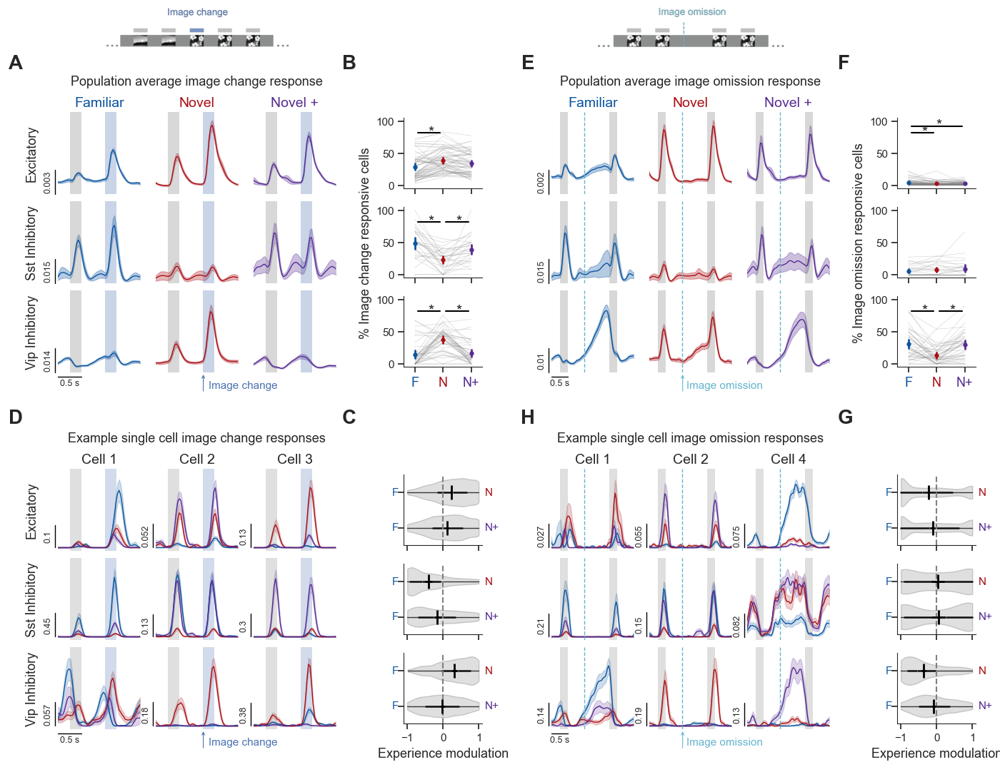

In [ ]:
# # Composite Figure 3 main (EXPERIENCE-MOD LAYOUT, v5) - alternative to v2/v3/v4 (those cells are unchanged)
# #   Two rows; change on the left half, omission on the right half:
# #     row 1:  A (population averages)  | B (% responsive)   ||  E | F
# #     row 2:  D (example cells)       | C (experience modulation) ||  H | G
# #   C/G = experience modulation with cell types as rows, F vs N and F vs N+ only, using each column's
# #   own responses (change responses for C, omission responses for G).
# #   All panels in a row share the cell-type row positions/heights. Cell-type labels on the far left (A, D).
# #   NOTE: needs the `comparisons=` kwarg added to plot_experience_modulation_index_annotated_by_cell_type
# #   (restart the kernel / re-import platform_paper_figures after pulling that change).
# #
# # Geometry is in INCHES (knobs below); every axes is placed explicitly. panel() is used for letters /
# # axes ownership; letters are then placed from the rendered content (left of it, aligned per figure row).
# #
# # UPSTREAM (run the data-loading cells above first): data_type, change_mdf, omission_mdf,
# #   each_image_mdf, platform_cells_table, save_dir, and the ppf / utils imports.
# import os
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# from visual_behavior.visualization.panel_grid import fig_setup, panel

# # ---------------------------------------------------------------- knobs ----
# TRACE_W_IN = 1.15           # width of every A/E/D/H trace axes; FIG_W is derived from it
# CHANGE_XLIM = [-1, 0.75]
# OMISSION_XLIM = [-1, 1.5]


# GUT = (20, 28)              # panel() letter gutter (pt) - only used for the initial letter axes
# # horizontal (inches)
# COLUMN_GAP_IN = 0.20        # gap between the change and omission columns
# RIGHT_MARGIN_IN = 0.10
# LEFT_SETBACK_IN = [0.78, 0.42]  # column left -> first trace spine: change col (letter + cell-type label + scale)
#                                 #   / omission col (letter + scale value only; no cell-type labels)
# TRACE_GAP_IN = 0.22         # gap between trace columns (same in A/E and D/H so their columns line up)
# SIDE_SETBACK_IN = 0.95      # last trace column's right edge -> B/C (F/G) spine (letter + y ticks + y label)
# BC_W_IN = 1.10              # B/C/F/G axes width
# BC_RIGHT_PAD_IN = 0.35      # space right of B/C (F/G): holds C/G's right-side N / N+ markers
# EXP_METRIC = 'mean_response'
# EXP_COMPARISONS = ['F N', 'F N+']   # top-to-bottom within each cell-type row
# EXP_ANNOT_FS = 11           # F / N / N+ markers beside the C/G violins
# # vertical (inches)
# TOP_IN = 0.02
# TRACE_ROW_IN = 1.15         # row height of every panel (B/C/F/G rows align with the trace rows)
# ROW_GAP_IN = 0.10
# TRACE_HEADER_IN = 0.80      # A/E and D/H: block title + column titles above row 1
# BOTTOM_IN = 0.45            # below last row: tick labels / scale bar / event arrow
# EX_BOTTOM_IN = 0.75         # bottom row: also holds C/G's x tick labels + 'Experience modulation' label
# SECTION_GAP_IN = 0.10
# TITLE_GAP_IN = 0.34         # block-title baseline sits this far above row 1
# SCHEM_MAX_H_IN = 0.60       # schematic height cap (actual height follows the PNG aspect)
# SCHEM_W_FRAC = 0.70         # schematic width as a fraction of the A/E trace span
# SCHEM_PAD_IN = 0.08         # space below/above the schematic
# LETTER_PAD_IN = 0.04
# LETTER_GAP_IN = 0.04

# # text
# CT_FS = 13                  # = AXIS_LABEL_FS (matches the other y labels)
# CT_OFFSET_PT = 26           # cell-type label offset left of the first spine (same for A/E and D/H)
# AXIS_LABEL_FS, TICK_FS = 13, 11
# SPINE_LW = 0.8
# EXP_TITLE_FS = 14
# INFO_TITLE_FS = 13
# SCALE_FS = 9
# SCALE_BAR_OFFSET = 0.04      # y-scale bar distance left of the axes, as a fraction of the x range (A/E/D/H)
# SMALL_INSET_IN = 0.08       # B/C/F/G axes are this much shorter at top AND bottom of each row (more hspace)
# TIME_BAR_FRAC = 0.05        # 0.5 s bar: distance below the x-axis, as a fraction of the y range
# ARROW_LW, ARROW_SCALE = 0.8, 7
# TRACE_LW = 1

# CHANGE_COLOR = sns.color_palette()[0]
# OMISSION_COLOR = sns.color_palette()[9]
# TITLE_POP = {'changes': 'Population average image change response',
#              'omissions': 'Population average image omission response'}
# TITLE_EX = {'changes': 'Example single cell image change responses',
#             'omissions': 'Example single cell image omission responses'}
# SCHEMATIC_DIR = '/Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/schematics/Figure 1'
# SCHEM = {'changes': os.path.join(SCHEMATIC_DIR, 'image_change_small.png'),
#          'omissions': os.path.join(SCHEMATIC_DIR, 'image_omission_small.png')}
# SCHEM_IMG = {}
# for _k, _f in SCHEM.items():
#     try:
#         SCHEM_IMG[_k] = plt.imread(_f)
#     except Exception as e:
#         SCHEM_IMG[_k] = None
#         print('could not load schematic', _f, ':', e)

# EXP = utils.get_experience_levels()
# exp_colors = utils.get_experience_level_colors()
# cell_types = ['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory']

# # ---------------------------------------------------------------- geometry ----
# n_ex_cols = 3
# SPAN_IN = n_ex_cols * TRACE_W_IN + (n_ex_cols - 1) * TRACE_GAP_IN            # A/E/D/H trace span (same in both columns)
# COL_W = [LEFT_SETBACK_IN[c] + SPAN_IN + SIDE_SETBACK_IN + BC_W_IN + BC_RIGHT_PAD_IN for c in range(2)]   # half widths
# COL_X = [0.0, COL_W[0] + COLUMN_GAP_IN]                                       # column left edges
# FIG_W = round(COL_X[1] + COL_W[1] + RIGHT_MARGIN_IN, 2)

# EXP_W_IN = BC_W_IN          # C/G have the same x and width as B/F (aligned)

# SCHEM_H = {k: (min(SCHEM_MAX_H_IN, SCHEM_W_FRAC * SPAN_IN * im.shape[0] / im.shape[1]) if im is not None
#                else SCHEM_MAX_H_IN) for k, im in SCHEM_IMG.items()}
# SCHEM_BAND_IN = max(SCHEM_H.values()) + 2 * SCHEM_PAD_IN

# ROW_H = {'pop': TRACE_ROW_IN, 'ex': TRACE_ROW_IN}
# ROWS_H_IN = {k: 3 * v + 2 * ROW_GAP_IN for k, v in ROW_H.items()}
# SEC_H = {k: TRACE_HEADER_IN + ROWS_H_IN[k] + (EX_BOTTOM_IN if k == 'ex' else BOTTOM_IN) for k in ROW_H}
# SEC_Y = {'pop': TOP_IN + SCHEM_BAND_IN}
# SEC_Y['ex'] = SEC_Y['pop'] + SEC_H['pop'] + SECTION_GAP_IN
# SEC_HDR = {'pop': TRACE_HEADER_IN, 'ex': TRACE_HEADER_IN}
# FIG_H = round(SEC_Y['ex'] + SEC_H['ex'], 2)
# print(f'figsize = ({FIG_W}, {FIG_H}); trace axes = {TRACE_W_IN:.2f} x {TRACE_ROW_IN:.2f} in; B/C width = {BC_W_IN:.2f} in')

# def _fx(x_in): return x_in / FIG_W
# def _fy(y_in): return y_in / FIG_H

# def _place(ax, x_in, w_in, sec, r, inset=0.0):
#     top = SEC_Y[sec] + SEC_HDR[sec] + r * (ROW_H[sec] + ROW_GAP_IN) + inset
#     h = ROW_H[sec] - 2 * inset                       # inset keeps the row centered on the trace row
#     ax.set_position([_fx(x_in), 1 - _fy(top + h), _fx(w_in), _fy(h)])

# def _trace_x(c, j):
#     return COL_X[c] + LEFT_SETBACK_IN[c] + j * (TRACE_W_IN + TRACE_GAP_IN)

# def _exp_x(c):                      # C/G spine = B/F spine (right of D/H)
#     return _trace_x(c, n_ex_cols - 1) + TRACE_W_IN + SIDE_SETBACK_IN

# LETTERS = {'changes': ('A', 'B', 'C', 'D'), 'omissions': ('E', 'F', 'G', 'H')}
# LETTER_ROWS = [('A', 'B', 'E', 'F'), ('D', 'C', 'H', 'G')]
# REGIONS = {}
# for c, ev in enumerate(['changes', 'omissions']):
#     la, lb, lc, ld = LETTERS[ev]
#     x0, x1 = COL_X[c], COL_X[c] + COL_W[c]
#     xm = _trace_x(c, n_ex_cols - 1) + TRACE_W_IN                   # traces | small panels split
#     for l, sec, a, b in [(la, 'pop', x0, xm), (lb, 'pop', xm, x1), (lc, 'ex', xm, x1), (ld, 'ex', x0, xm)]:
#         REGIONS[l] = [_fx(a), _fx(b), _fy(SEC_Y[sec]), _fy(SEC_Y[sec] + SEC_H[sec])]

# # ---------------------------------------------------------------- helpers ----
# def _cell_type_label(ax, cell_type):
#     ax.annotate(cell_type, xy=(0, 0.5), xycoords='axes fraction', xytext=(-CT_OFFSET_PT, 0),
#                 textcoords='offset points', rotation=90, fontsize=CT_FS, ha='center', va='center',
#                 annotation_clip=False)

# def _event_arrow(ax, label, color):
#     ax.annotate(label, xy=(0.12, -0.1), xycoords=ax.get_xaxis_transform(),
#                 ha='left', va='top', color=color, fontsize=11, clip_on=False)
#     ax.annotate('', xy=(0.01, -0.25), xycoords=ax.get_xaxis_transform(), xytext=(0.01, 0),
#                 arrowprops=dict(arrowstyle='<-', color=color, lw=ARROW_LW, mutation_scale=ARROW_SCALE),
#                 clip_on=False)

# def _time_bar(ax, xlim, seconds=0.5):
#     ymn, ymx = ax.get_ylim()
#     xfrac = seconds / (xlim[1] - xlim[0])
#     y_bar = ymn - (ymx - ymn) * TIME_BAR_FRAC
#     ax.axhline(y=y_bar, xmin=0, xmax=xfrac, color='k', linewidth=1, clip_on=False)
#     ax.annotate(f'{seconds} s', xy=(xlim[0] + seconds / 2, y_bar), xycoords='data', xytext=(0, -2),
#                 textcoords='offset points', ha='center', va='top', fontsize=SCALE_FS,
#                 clip_on=False, annotation_clip=False)

# def plot_pop_avg_block(axgrid, mdf, event_type, xlim, arrow_label, arrow_color, labels=True):
#     dist = (xlim[1] - xlim[0]) * SCALE_BAR_OFFSET
#     for i, cell_type in enumerate(cell_types):
#         row = list(axgrid[i])
#         df_ct = mdf[mdf.cell_type == cell_type]
#         ppf.plot_population_averages_for_conditions(
#             df_ct, data_type, event_type, 'experience_level', 'experience_level',
#             horizontal=True, legend=False, xlim_seconds=xlim, interval_sec=1,
#             palette=exp_colors, ax=row)
#         scale = 1.06 if cell_type == 'Excitatory' else 1.15
#         _, ymax = row[0].get_ylim(); row[0].set_ylim(0, ymax * scale)
#         _, ymax = row[0].get_ylim()
#         row[0].set_yticks([])
#         row[0].axvline(x=xlim[0] - dist, ymin=0, ymax=0.3, color='k', linewidth=1, clip_on=False)
#         row[0].annotate(f'{np.round(ymax * .3, 3):g}', xy=(xlim[0] - dist, ymax * .15), xycoords='data',
#                         xytext=(-2, 0), textcoords='offset points', rotation=90, ha='right', va='center',
#                         fontsize=SCALE_FS, annotation_clip=False)   # rotated, like D/H
#         row[0].set_ylabel('')
#         if labels:
#             _cell_type_label(row[0], cell_type)
#         for j in range(3):
#             row[j].set_title(EXP[j] if i == 0 else '', color=exp_colors[j], fontsize=EXP_TITLE_FS)
#             row[j].set_xlabel('')
#         sns.despine(ax=row[0], top=True, right=True, left=True, bottom=True)
#         row[0].tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False)
#         row[0].set_xticks([])
#         for j in (1, 2):
#             row[j].axis('off')
#         if i == len(cell_types) - 1:
#             _event_arrow(row[1], arrow_label, arrow_color)
#             _time_bar(row[0], xlim)

# def plot_overlaid_cell(ax, mdf, csid, event_type, xlim):
#     change, omitted = event_type == 'changes', event_type == 'omissions'
#     cdf = mdf[mdf.cell_specimen_id == csid]
#     ts = None
#     for e, exp in enumerate(EXP):
#         d = cdf[cdf.experience_level == exp]
#         if len(d) == 0:
#             continue
#         utils.plot_mean_trace_from_mean_df(d, ylabel='', xlabel='', xlims=xlim, alpha=0.2,
#                                            color=exp_colors[e], interval_sec=1, linewidth=TRACE_LW, ax=ax)
#         ts = d.trace_timestamps.values[0]
#     if ts is not None:
#         utils.plot_flashes_on_trace(ax, ts, change=change, omitted=omitted, alpha=0.25, linewidth=TRACE_LW)
#     ax.set_xlim(xlim)
#     ymin, ymax = ax.get_ylim()
#     ax.set_ylim(min(ymin, 0), ymax * 1.1)
#     ymin, ymax = ax.get_ylim()
#     bar = float(f'{ymax * .3:.2g}')
#     ax.set_yticks([])
#     x_bar = xlim[0] - (xlim[1] - xlim[0]) * SCALE_BAR_OFFSET   # same offset as A/E
#     ax.axvline(x=x_bar, ymin=(0 - ymin) / (ymax - ymin), ymax=(bar - ymin) / (ymax - ymin),
#                color='k', linewidth=1, clip_on=False)
#     ax.annotate(f'{bar:g}', xy=(x_bar, bar / 2), xycoords='data', xytext=(-2, 0), textcoords='offset points',
#                 rotation=90, ha='right', va='center', fontsize=SCALE_FS, annotation_clip=False)
#     ax.set_xlabel(''); ax.set_ylabel('')
#     sns.despine(ax=ax, top=True, right=True, left=True, bottom=True)
#     ax.tick_params(bottom=False, left=False, right=False, top=False, labelbottom=False, pad=-1)
#     ax.set_xticks([])

# def plot_example_block(grid, mdf, cells_by_type, event_type, xlim, labels=True, arrow=None):
#     for i, cell_type in enumerate(cell_types):
#         cells = cells_by_type.get(cell_type, [])
#         for j in range(grid.shape[1]):
#             if j < len(cells):
#                 plot_overlaid_cell(grid[i, j], mdf, cells[j], event_type, xlim)
#             else:
#                 grid[i, j].axis('off')
#         if labels:
#             _cell_type_label(grid[i, 0], cell_type)     # label even if this row has no cell in column 0
#     _time_bar(grid[-1, 0], xlim)
#     if arrow is not None:                              # 'Image change' / 'Image omission' arrow, as under A/E
#         _event_arrow(grid[-1, 1], *arrow)

# def style_small(axs):
#     for _a in axs:
#         _a.set_title('')
#         _a.tick_params(labelsize=TICK_FS)
#         _a.tick_params(axis='x', labelsize=TICK_FS + 2)
#         for _s in _a.spines.values():
#             _s.set_linewidth(SPINE_LW)
#     for _a in axs[:-1]:
#         _a.tick_params(labelbottom=False); _a.set_xlabel('')
#     axs[1].yaxis.label.set_size(AXIS_LABEL_FS)

# # ---------------------------------------------------------------- figure ----
# fig = plt.figure(figsize=(FIG_W, FIG_H)); fig_setup(fig)
# stats_dir = os.path.join(save_dir, 'composite', 'figure_3_v5_stats') if save_dir else None
# if stats_dir:
#     os.makedirs(stats_dir, exist_ok=True)

# each_change_pref = each_image_mdf[(each_image_mdf.is_change == True) & (each_image_mdf.pref_stim == True)]
# COLS = [  # event, mdf, xlim, pct df, threshold, pct ylabel, examples, arrow, (unused)
#     ('changes', change_mdf, CHANGE_XLIM, each_change_pref, 0.2, '% Image change responsive cells',
#      CHANGE_CELLS, ('Image change', CHANGE_COLOR), None),
#     ('omissions', omission_mdf, OMISSION_XLIM, omission_mdf, 0.1, '% Image omission responsive cells',
#      OMISSION_CELLS, ('Image omission', OMISSION_COLOR), None),
# ]
# header_texts = {}
# for c, (ev, mdf, xlim, pct_df, thr, pct_ylabel, cells, arrow, mod) in enumerate(COLS):
#     la, lb, lc, ld = LETTERS[ev]
#     # --- A/E population averages ---
#     gp = np.array(panel(fig, REGIONS[la][:2], REGIONS[la][2:], la, dim=(3, 3), sharey='row', gutter_pt=GUT), dtype=object)
#     for i in range(3):
#         for j in range(3):
#             _place(gp[i, j], _trace_x(c, j), TRACE_W_IN, 'pop', i)
#     plot_pop_avg_block(gp, mdf, ev, xlim, *arrow, labels=(c == 0))   # cell-type labels on the change column only
#     # --- B/F % responsive ---
#     ab = list(np.atleast_1d(panel(fig, REGIONS[lb][:2], REGIONS[lb][2:], lb, dim=(3, 1), sharex=True, gutter_pt=GUT)))
#     xb = _trace_x(c, n_ex_cols - 1) + TRACE_W_IN + SIDE_SETBACK_IN      # right of A/E, same rows
#     for i in range(3):
#         _place(ab[i], xb, BC_W_IN, 'pop', i, inset=SMALL_INSET_IN)
#     ppf.plot_percent_responsive_cells(pct_df, responsiveness_threshold=thr, ylim=(-5, 105), ylabel=pct_ylabel,
#                                       horizontal=False, event_type=ev, stats_dir=stats_dir, ax=ab)
#     style_small(ab)
#     # --- C/G modulation index ---
#     ac = list(np.atleast_1d(panel(fig, REGIONS[lc][:2], REGIONS[lc][2:], lc, dim=(3, 1), sharex=True, gutter_pt=GUT)))
#     for i in range(3):                                                  # right of D/H, same rows
#         _place(ac[i], _exp_x(c), EXP_W_IN, 'ex', i, inset=SMALL_INSET_IN)
#     ppf.plot_experience_modulation_index_annotated_by_cell_type(
#         mdf, ev, EXP_METRIC, platform_cells_table, xlims=(-1.1, 1.1), xlabel='Experience modulation',
#         horiz=False, stats_dir=stats_dir, ax=ac, comparisons=EXP_COMPARISONS)
#     style_small(ac)
#     ac[-1].xaxis.label.set_size(AXIS_LABEL_FS)
#     for _a in ac:
#         _a.tick_params(axis='x', labelsize=TICK_FS)
#         for _t in _a.texts:
#             if _t.get_text() in ('F', 'N', 'N+'):
#                 _t.set_fontsize(EXP_ANNOT_FS)
#     # --- D/H example cells ---
#     gx = np.array(panel(fig, REGIONS[ld][:2], REGIONS[ld][2:], ld, dim=(3, n_ex_cols), gutter_pt=GUT),
#                   dtype=object).reshape(3, n_ex_cols)
#     for i in range(3):
#         for j in range(n_ex_cols):
#             _place(gx[i, j], _trace_x(c, j), TRACE_W_IN, 'ex', i)
#     plot_example_block(gx, mdf, cells, ev, xlim, labels=(c == 0), arrow=arrow)     # cell-type labels on the change half
#     for j in range(n_ex_cols):
#         gx[0, j].set_title(EX_COL_LABELS[ev][j], fontsize=EXP_TITLE_FS)

#     # --- headers: block titles + schematic above the column ---
#     xs0, xs1 = _trace_x(c, 0), _trace_x(c, n_ex_cols - 1) + TRACE_W_IN
#     xd0, xd1 = xs0, xs1
#     for l, sec, title, (t0, t1) in [(la, 'pop', TITLE_POP[ev], (xs0, xs1)), (ld, 'ex', TITLE_EX[ev], (xd0, xd1))]:
#         ty = SEC_Y[sec] + SEC_HDR[sec] - TITLE_GAP_IN
#         header_texts[l] = fig.text(_fx((t0 + t1) / 2), 1 - _fy(ty), title, ha='center', va='bottom',
#                                    fontsize=INFO_TITLE_FS)
#     sw = SCHEM_W_FRAC * SPAN_IN
#     sax = fig.add_axes([_fx((xs0 + xs1 - sw) / 2), 1 - _fy(TOP_IN + SCHEM_PAD_IN + SCHEM_H[ev]),
#                         _fx(sw), _fy(SCHEM_H[ev])])
#     if SCHEM_IMG[ev] is not None:
#         sax.imshow(SCHEM_IMG[ev])
#         sax.set_anchor('S')
#     sax.axis('off')
#     sax._panel_grid_label_ax = True    # not a panel; skip in letter placement / audit

# # ---- panel letters: left of each panel's leftmost content, just above its top, aligned per figure row ----
# for _lax in fig.axes:
#     if getattr(_lax, '_panel_grid_label_ax', False):
#         for _lt in _lax.texts:
#             _lt.set_fontsize(20)
# fig.canvas.draw()
# _r = fig.canvas.get_renderer()
# _inv = fig.transFigure.inverted()
# _letter_pos = {}
# for _lax in fig.axes:
#     if not getattr(_lax, '_panel_grid_label_ax', False) or not _lax.texts:
#         continue
#     _lbl = _lax.texts[0].get_text()
#     if _lbl not in REGIONS:
#         continue
#     _owned = [a for a in fig.axes if getattr(a, '_panel_grid_owner', None) == _lbl and a.get_visible()
#               and (a.has_data() or a.texts or a.get_title())]
#     _bbs = [a.get_tightbbox(_r).transformed(_inv) for a in _owned]
#     if not _bbs:
#         continue
#     _tops = [bb.y1 for bb in _bbs]
#     if _lbl in header_texts:
#         _tops.append(header_texts[_lbl].get_window_extent(_r).transformed(_inv).y1)
#     _p = _lax.get_position()
#     _wl = _lax.texts[0].get_window_extent(_r).transformed(_inv).width
#     _x = max(-0.15 * _p.width, min(bb.x0 for bb in _bbs) - _fx(LETTER_GAP_IN) - _wl - 0.15 * _p.width)
#     _letter_pos[_lbl] = (_lax, _x, max(_tops) + _fy(LETTER_PAD_IN) - _p.height * 0.2)
# for _row in LETTER_ROWS:                     # same height across a figure row (highest of the row)
#     _y = max(_letter_pos[l][2] for l in _row if l in _letter_pos)
#     for l in _row:
#         if l in _letter_pos:
#             _lax, _x, _ = _letter_pos[l]
#             _p = _lax.get_position()
#             _lax.set_position([_x, _y, _p.width, _p.height])
# # C/G letters share the x of B/F (their axes are aligned); then every B/C/F/G plot is pushed right
# # (if needed) so its leftmost content starts right of its own letter
# for _top, _bot in [('B', 'C'), ('F', 'G')]:
#     if _top in _letter_pos and _bot in _letter_pos:
#         _lax = _letter_pos[_bot][0]
#         _p = _lax.get_position()
#         _lax.set_position([min(_letter_pos[_top][1], _letter_pos[_bot][1]), _p.y0, _p.width, _p.height])
# fig.canvas.draw()
# for _lbl in ['B', 'C', 'F', 'G']:
#     _lax = _letter_pos[_lbl][0]
#     _right = _lax.texts[0].get_window_extent(_r).transformed(_inv).x1 + _fx(LETTER_GAP_IN)
#     _axs = [a for a in fig.axes if getattr(a, '_panel_grid_owner', None) == _lbl]
#     _left = min(a.get_tightbbox(_r).transformed(_inv).x0 for a in _axs)
#     if _left < _right - 1e-4:
#         for a in _axs:
#             _p = a.get_position()
#             a.set_position([_p.x0 + (_right - _left), _p.y0, _p.width, _p.height])
#         print(f'shifted {_lbl} right by {(_right - _left) * FIG_W:.2f} in to clear its letter')

# # audit: any panel letter overlapping drawn content?
# fig.canvas.draw()
# _items = [(getattr(a, '_panel_grid_owner', None) or 'other', a.get_tightbbox(_r).transformed(_inv))
#           for a in fig.axes if a.get_visible() and (a.has_data() or a.texts or a.get_title() or a.images)
#           and not (getattr(a, '_panel_grid_label_ax', False) and not a.images)]
# _items += [('title', t.get_window_extent(_r).transformed(_inv)) for t in fig.texts]
# _bad = []
# for _lbl, (_lax, _, _) in _letter_pos.items():
#     _lb = _lax.texts[0].get_window_extent(_r).transformed(_inv)
#     _bad += [(_lbl, o) for o, bb in _items if _lb.overlaps(bb)]
# print('letter overlaps:', _bad if _bad else 'none')

# utils.save_figure(fig, (FIG_W, FIG_H), save_dir, 'composite', 'figure_3_main_composite_v5', formats=['.png', '.pdf'])
